# ECS708 Machine Learning: Fashion-MNIST investigation

**Research question.** What structure exists in Fashion-MNIST, how can different models exploit it, and what do their successes and failures teach us about the data and its representations?

Task IDs are in headings and captions. *Restart and run all* takes about 25 minutes (2 CPU cores, no GPU). Experiments are logged in `results/experiment_register.csv` (R3).

## Part 0: setup (addresses 0.1, 0.2, 0.3)

Run from the repository root; the four Fashion-MNIST `.gz` files are expected in `data/fashion/` (downloaded with `torchvision` if missing).

In [1]:
import os, platform, time, json, gzip, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve, roc_auc_score, log_loss

ROOT = Path.cwd()                                   # run from the repository root
DATA_DIR, SPLITS_DIR = ROOT / "data" / "fashion", ROOT / "splits"
FIG_DIR, RES_DIR = ROOT / "figures", ROOT / "results" / "part1"
for d in (DATA_DIR, SPLITS_DIR, FIG_DIR, RES_DIR): d.mkdir(parents=True, exist_ok=True)
REGISTER_PATH = ROOT / "results" / "experiment_register.csv"

SEED = 2208
np.random.seed(SEED)
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
SHORT = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

### 0.1 Fixed data partitions

* **Split.** Fashion-MNIST (28×28, 10 classes; 60,000 official train, 10,000 official test). The official train set is split once, stratified with seed 2208, into **50,000 train / 10,000 validation**, plus stratified subsets: 10,000 for CPU use (unused) and 3,000 / 1,000 / 1,000 for clustering. Indices are saved in `splits/`; each run re-creates them and asserts they match.
* **Index convention.** All indices point into the official 60,000 train array, except `cluster_test_idx` (official test array). Subsets drawn from `train_idx` or `val_idx` still index the original array.
* **Roles (R1, R2, R6, R7).** Train fits parameters; validation chooses hyperparameters and thresholds; test is used once at the end. Only test *labels* are read here (to stratify the clustering subset); test images stay unread until the guarded final cell. Pixels are divided by 255, which uses no fitted statistics.
* **Seeds.** 2208 for partitions, tree tie-breaking and examples (2209 for the Fig. 4b grid); the tree is also refitted with seeds 1 and 2. LR and naive Bayes are deterministic.

In [2]:
# ----------------------------------------------------------------- data files
FILES = {"tr_x": "train-images-idx3-ubyte.gz", "tr_y": "train-labels-idx1-ubyte.gz", "te_x": "t10k-images-idx3-ubyte.gz", "te_y": "t10k-labels-idx1-ubyte.gz"}
def ensure_downloaded():
    if all((DATA_DIR / f).exists() for f in FILES.values()): return
    from torchvision.datasets import FashionMNIST            # only used to download the official files
    for train in (True, False): FashionMNIST(ROOT / "data" / "_tv", train=train, download=True)
    for f in FILES.values(): (DATA_DIR / f).write_bytes((ROOT / "data" / "_tv" / "FashionMNIST" / "raw" / f).read_bytes())
def read_images(name):
    with gzip.open(DATA_DIR / name, "rb") as f: return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784)
def read_labels(name):
    with gzip.open(DATA_DIR / name, "rb") as f: return np.frombuffer(f.read(), np.uint8, offset=8).astype(np.int64)
def prep(X): return (X / 255.0).astype(np.float32)           # fixed transform, no fitted statistics (R2)

ensure_downloaded()
X_off, y_off = read_images(FILES["tr_x"]), read_labels(FILES["tr_y"])   # official TRAIN set (60,000)
y_test_labels = read_labels(FILES["te_y"])                               # test LABELS only; test images stay unread (R1, R6, R7)

# ----------------------------------------------------------------- 0.1 fixed stratified partitions
def stratified_pick(indices, labels, n):
    picked, _ = train_test_split(indices, train_size=n, stratify=labels, random_state=SEED)
    return np.sort(picked)
all_idx = np.arange(len(y_off))
train_idx, val_idx = train_test_split(all_idx, test_size=10_000, stratify=y_off, random_state=SEED)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)
IDX = dict(train_idx=train_idx, val_idx=val_idx,
           train_subset10k_idx=stratified_pick(train_idx, y_off[train_idx], 10_000),            # CPU option, unused
           cluster_train_idx=stratified_pick(train_idx, y_off[train_idx], 3_000),               # indexes official TRAIN array
           cluster_val_idx=stratified_pick(val_idx, y_off[val_idx], 1_000),                     # indexes official TRAIN array
           cluster_test_idx=stratified_pick(np.arange(len(y_test_labels)), y_test_labels, 1_000))  # indexes official TEST array
assert len(np.intersect1d(train_idx, val_idx)) == 0 and len(train_idx) + len(val_idx) == 60_000
assert np.isin(IDX["cluster_train_idx"], train_idx).all() and np.isin(IDX["cluster_val_idx"], val_idx).all()
assert np.isin(IDX["train_subset10k_idx"], train_idx).all()

npz = SPLITS_DIR / f"splits_seed{SEED}.npz"
if npz.exists():
    with np.load(npz) as old: assert all(np.array_equal(old[k], v) for k, v in IDX.items()), "saved splits differ: partitions are frozen"
    print("Saved partitions found and reproduced exactly.")
else:
    np.savez_compressed(npz, **IDX); print("Partitions created and saved to", npz.relative_to(ROOT))
y_all = {"train_idx": y_off, "val_idx": y_off, "train_subset10k_idx": y_off, "cluster_train_idx": y_off, "cluster_val_idx": y_off, "cluster_test_idx": y_test_labels}
counts = pd.DataFrame({k: np.bincount(y_all[k][v], minlength=10) for k, v in IDX.items()}, index=CLASS_NAMES)
counts.loc["TOTAL"] = counts.sum()
print("Images per class in every partition (stratified: balanced):"); display(counts)
json.dump({"seed": SEED, "method": "train_test_split(stratify=labels, random_state=seed)", "sizes": {k: int(len(v)) for k, v in IDX.items()},
           "index_convention": "all index the official 60k train array except cluster_test_idx (official 10k test array)"},
          open(SPLITS_DIR / f"splits_seed{SEED}.json", "w"), indent=2)

Xtr, ytr = prep(X_off[train_idx]), y_off[train_idx]
Xva, yva = prep(X_off[val_idx]), y_off[val_idx]
print(f"train {Xtr.shape} | validation {Xva.shape} | test images not loaded")

Saved partitions found and reproduced exactly.
Images per class in every partition (stratified: balanced):


,train_idx,val_idx,train_subset10k_idx,cluster_train_idx,cluster_val_idx,cluster_test_idx
T-shirt/top,5000,1000,1000,300,100,100
Trouser,5000,1000,1000,300,100,100
Pullover,5000,1000,1000,300,100,100
Dress,5000,1000,1000,300,100,100
Coat,5000,1000,1000,300,100,100
Sandal,5000,1000,1000,300,100,100
Shirt,5000,1000,1000,300,100,100
Sneaker,5000,1000,1000,300,100,100
Bag,5000,1000,1000,300,100,100
Ankle boot,5000,1000,1000,300,100,100


train (50000, 784) | validation (10000, 784) | test images not loaded


### 0.2 Hardware and runtimes

The next cell records the device; fit and prediction times are tabulated at the end of Part 1.

In [3]:
# ----------------------------------------------------------------- 0.2 computing
def cpu_name():
    try: return next(l.split(":")[1].strip() for l in open("/proc/cpuinfo") if "model name" in l)
    except Exception: return platform.processor() or "unknown"
print("Hardware (0.2):", cpu_name(), "|", os.cpu_count(), "logical CPUs | no GPU used")
print("Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Hardware (0.2): Intel(R) Xeon(R) Processor @ 2.10GHz | 2 logical CPUs | no GPU used
Python 3.13.18 | numpy 2.5.3 | scikit-learn 1.9.1 | pandas 3.0.5


### 0.3 Repository layout

Notebook, `README.md`, `requirements.txt`, `splits/`, `results/`, `figures/`. The helper functions below live in this notebook (no `src/` or `scripts/`).

In [4]:
# ----------------------------------------------------------------- small helpers (all of them are here, nothing is imported from the repo)
FIG_INDEX, TIMES = [], []
def save_fig(fig, name, tasks, caption):
    path = FIG_DIR / f"{name}.png"; fig.savefig(path, dpi=150, bbox_inches="tight")
    FIG_INDEX.append({"file": f"figures/{path.name}", "tasks": tasks, "produced_by": "ecs708_fashion_mnist.ipynb", "caption": caption})

def timed_fit(model, X, y, label=""):
    """Fit and time; return (model, seconds, warning messages). Warnings are kept so they can be reported, not hidden."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always"); t0 = time.perf_counter(); model.fit(X, y); sec = time.perf_counter() - t0
    TIMES.append({"what": f"fit {label}", "seconds": sec}); return model, sec, sorted({str(w.message).split("\n")[0][:80] for w in caught})

def timed_predict(model, X, label=""):
    t0 = time.perf_counter(); p = model.predict(X); TIMES.append({"what": f"predict {label} ({len(X)} images)", "seconds": time.perf_counter() - t0}); return p

def wilson_interval(k, n, z=1.96):
    """95% Wilson interval for k/n: sampling uncertainty of the evaluation set only."""
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(10), zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=range(10))
    return pd.DataFrame({"class": CLASS_NAMES, "support": s, "correct (TP)": np.diag(cm), "recall": r, "predicted as class": cm.sum(0), "precision": p, "F1": f})

def top_confusions(y_true, y_pred, k=6):
    cm = confusion_matrix(y_true, y_pred, labels=range(10)); off = cm.copy(); np.fill_diagonal(off, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:k], off.shape))[0]
    return pd.DataFrame([{"true": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "count": int(off[i, j]), "share of true class": off[i, j] / cm[i].sum()} for i, j in idx])

# experiment register (rule R3): one row per experiment in results/experiment_register.csv
REGISTER_COLUMNS = ["id", "part_task", "question", "hypothesis", "changed_variable", "fixed_conditions", "split", "seed", "configuration", "metric", "result", "output_path", "notes"]
def reset_register(prefix):
    df = pd.read_csv(REGISTER_PATH, dtype=str).fillna("") if REGISTER_PATH.exists() else pd.DataFrame(columns=REGISTER_COLUMNS)
    df[~df["id"].str.startswith(prefix)].reindex(columns=REGISTER_COLUMNS, fill_value="").to_csv(REGISTER_PATH, index=False)
def log_experiment(**row):
    df = pd.read_csv(REGISTER_PATH, dtype=str).fillna("")
    pd.concat([df, pd.DataFrame([{c: str(row.get(c, "")) for c in REGISTER_COLUMNS}])], ignore_index=True).to_csv(REGISTER_PATH, index=False)

---
# Part 1: Classical classification

*How do different classifiers use the same data, and what can their errors tell us?*

Every model uses the same 50,000 training and 10,000 validation images (R4); the test set is sealed. **Unavoidable differences:** the three models have different knobs, grid sizes (8 values of C, 12 depths, 8 smoothing values) and fit times (tabulated at the end), so equal tuning effort is not equal compute. **Selection rule:** highest validation accuracy, preferring a simpler setting within 0.1 points of the best. 1.4 runs first because it selects the settings used in 1.2, 1.3 and 1.5. **Variability:** LR and naive Bayes are deterministic; the tree is refitted with 3 seeds; validation sampling uncertainty is shown as 95% Wilson intervals.

**Disclosure (R7).** A first LR sweep with 400 iterations did not converge for C ≥ 1; it is discarded and nothing was chosen from it.

## 1.1 Models and justification

The data are 784 pixel features in [0, 1] and 10 balanced classes. Three methods from the module that use pixels differently:

* **Logistic regression (L2):** one linear score per class over all pixels; gives probabilities (needed in 1.5); complexity set by `C` (smaller C = stronger shrinkage). *Expected (lectures):* the strongest of the three, because it combines all pixels.
* **Decision tree (entropy):** nested single-pixel tests, a different bias; complexity set by `max_depth`. *Expected:* competitive on easy classes, over-fits when deep.
* **Gaussian naive Bayes:** a simple baseline assuming independent pixels; smoothing set by `var_smoothing`. *Expected:* weakest, because neighbouring pixels are strongly correlated.

## 1.4 Complexity study (run first)

**Hypotheses (before running).** LR: small C under-fits and the train-validation gap grows with C. Tree: training accuracy approaches 100% while validation flattens. Naive Bayes: far below LR. **Changed:** one knob per model; **metric:** accuracy on train and validation.

In [5]:
reset_register("P1-")        # idempotent: re-running the notebook never duplicates Part 1 rows
MODELS = {}                     # (family, setting) -> fitted model (all fitted on the 50,000 training images only)
HYP = {
 "LR": "Small C under-fits; larger C widens the train-validation gap; weight norm and confidence grow with C.",
 "DT": "Shallow trees under-fit; train accuracy -> 100% with depth while validation flattens (over-fitting).",
 "NB": "Independence assumption makes accuracy far lower than LR; variance smoothing may help.",
}
SEED_NOTE = "seed 2208"

# ---------------- Logistic regression: sweep C (inverse L2 strength) -----------------
LR_C = [1e-4, 1e-3, 1e-2, 1e-1, 3e-1, 1.0, 3.0, 10.0]
LR_MAXIT = 5000        # large enough for every setting to converge (checked below); 400 was too small for C >= 1
rows = []
for i, C in enumerate(LR_C, 1):
    m, sec, warns = timed_fit(LogisticRegression(C=C, max_iter=LR_MAXIT), Xtr, ytr, f'LR C={C:g}')
    proba = m.predict_proba(Xva)
    r = dict(C=C, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva), val_logloss=log_loss(yva, proba),
             weight_norm=float(np.linalg.norm(m.coef_)), mean_top_prob=float(proba.max(1).mean()),
             n_iter=int(np.max(m.n_iter_)), converged=bool(np.max(m.n_iter_) < LR_MAXIT), fit_s=sec)
    rows.append(r); MODELS[("LR", C)] = m
    log_experiment(id=f"P1-LR-{i:02d}", part_task="1.4", question="How does L2 strength (C) affect train/val accuracy?",
        hypothesis=HYP["LR"], changed_variable="C", fixed_conditions=f"multinomial LR, lbfgs, max_iter={LR_MAXIT}, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (deterministic)", configuration=f"C={C}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}; converged={r['converged']}",
        output_path="results/part1/sweep_logreg.csv", notes=f"fit {sec:.0f}s; weight_norm={r['weight_norm']:.1f}; " + ("; ".join(warns) if warns else "no warnings"))
lr_df = pd.DataFrame(rows)
assert lr_df.converged.all(), 'a logistic-regression fit did not converge: raise LR_MAXIT before interpreting the sweep'
print('All logistic-regression fits converged (n_iter < max_iter).')

# ---------------- Decision tree: sweep max_depth -----------------
DT_DEPTH = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for i, d in enumerate(DT_DEPTH, 1):
    m, sec, _ = timed_fit(DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED), Xtr, ytr, f'tree depth={d}')
    r = dict(max_depth="None" if d is None else d, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva),
             n_leaves=int(m.get_n_leaves()), actual_depth=int(m.get_depth()), fit_s=sec)
    rows.append(r); MODELS[("DT", d)] = m
    log_experiment(id=f"P1-DT-{i:02d}", part_task="1.4", question="How does tree depth affect train/val accuracy?",
        hypothesis=HYP["DT"], changed_variable="max_depth", fixed_conditions="entropy criterion, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (tie-breaking)", configuration=f"max_depth={d}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}; leaves={r['n_leaves']}",
        output_path="results/part1/sweep_tree.csv", notes=f"fit {sec:.0f}s; actual depth {r['actual_depth']}")
dt_df = pd.DataFrame(rows)

# ---------------- Gaussian naive Bayes: sweep var_smoothing -----------------
NB_VS = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 3e-1, 1.0]
rows = []
for i, v in enumerate(NB_VS, 1):
    m, sec, _ = timed_fit(GaussianNB(var_smoothing=v), Xtr, ytr, f'NB var_smoothing={v:g}')
    proba = m.predict_proba(Xva)
    r = dict(var_smoothing=v, train_acc=m.score(Xtr, ytr), val_acc=m.score(Xva, yva), val_logloss=log_loss(yva, np.clip(proba, 1e-15, 1)),
             mean_top_prob=float(proba.max(1).mean()), fit_s=sec)
    rows.append(r); MODELS[("NB", v)] = m
    log_experiment(id=f"P1-NB-{i:02d}", part_task="1.4", question="How does variance smoothing affect train/val accuracy?",
        hypothesis=HYP["NB"], changed_variable="var_smoothing", fixed_conditions="Gaussian NB, pixels/255",
        split="fit train 50k; evaluate train and validation 10k", seed=SEED_NOTE + " (deterministic)", configuration=f"var_smoothing={v}",
        metric="accuracy (train, val)", result=f"train={r['train_acc']:.4f}; val={r['val_acc']:.4f}",
        output_path="results/part1/sweep_nb.csv", notes=f"fit {sec:.1f}s")
nb_df = pd.DataFrame(rows)

lr_df.to_csv(RES_DIR / "sweep_logreg.csv", index=False); dt_df.to_csv(RES_DIR / "sweep_tree.csv", index=False); nb_df.to_csv(RES_DIR / "sweep_nb.csv", index=False)
fmt = {"train_acc": "{:.4f}", "val_acc": "{:.4f}", "val_logloss": "{:.4f}", "weight_norm": "{:.1f}", "mean_top_prob": "{:.3f}", "fit_s": "{:.1f}", "C": "{:g}", "var_smoothing": "{:g}"}
print("Logistic regression (train 50k; accuracy on train and on validation 10k)"); display(lr_df.style.format(fmt).hide(axis="index"))
print("Decision tree (entropy)"); display(dt_df.style.format(fmt).hide(axis="index"))
print("Gaussian naive Bayes"); display(nb_df.style.format(fmt).hide(axis="index"))

All logistic-regression fits converged (n_iter < max_iter).


Logistic regression (train 50k; accuracy on train and on validation 10k)


C,train_acc,val_acc,val_logloss,weight_norm,mean_top_prob,n_iter,converged,fit_s
0.0001,0.7551,0.7578,0.8946,1.7,0.515,102,True,6.2
0.001,0.8206,0.8225,0.5618,3.7,0.712,140,True,7.8
0.01,0.8549,0.8575,0.4322,7.7,0.805,206,True,11.9
0.1,0.8732,0.8621,0.3966,16.7,0.845,295,True,17.4
0.3,0.8777,0.8618,0.3996,24.5,0.857,436,True,27.5
1,0.8821,0.8599,0.4144,37.6,0.865,621,True,37.2
3,0.8850,0.8563,0.4330,53.9,0.871,899,True,64.4
10,0.8865,0.8528,0.4564,76.4,0.875,1110,True,93.8


Decision tree (entropy)


max_depth,train_acc,val_acc,n_leaves,actual_depth,fit_s
1,0.1987,0.1991,2,1,1.2
2,0.3426,0.3415,4,2,2.2
3,0.5337,0.5298,8,3,4.0
4,0.6784,0.6790,16,4,5.1
5,0.7184,0.7230,32,5,6.4
6,0.7594,0.7558,64,6,7.2
8,0.8144,0.7964,246,8,10.3
10,0.8590,0.8168,679,10,12.2
12,0.9009,0.8207,1343,12,14.8
15,0.9594,0.8200,2500,15,17.4


Gaussian naive Bayes


var_smoothing,train_acc,val_acc,val_logloss,mean_top_prob,fit_s
1e-09,0.5912,0.5910,6.4162,0.998,0.2
1e-07,0.6096,0.6101,6.1161,0.998,0.2
1e-05,0.6331,0.6335,5.7498,0.998,0.2
0.001,0.6591,0.6587,5.3239,0.998,0.2
0.01,0.6716,0.6710,5.1069,0.998,0.2
0.1,0.6756,0.6799,4.8614,0.996,0.2
0.3,0.6665,0.6733,4.8336,0.994,0.2
1,0.6472,0.6548,4.6873,0.986,0.2


In [6]:
# ---------------- Selection on VALIDATION accuracy (rule R1) -----------------
def pick_simplest_within(df, key, tol=0.001):
    # rows are ordered from simplest to most complex; take the first within `tol` of the best validation accuracy
    best = df["val_acc"].max()
    return df[df["val_acc"] >= best - tol].iloc[0][key]

SEL = {
    "LR": float(pick_simplest_within(lr_df, "C")),
    "DT": pick_simplest_within(dt_df, "max_depth"),
    "NB": float(nb_df.loc[nb_df["val_acc"].idxmax(), "var_smoothing"]),
}
SEL["DT"] = None if SEL["DT"] == "None" else int(SEL["DT"])
SEL_MODELS = {"LR": MODELS[("LR", SEL["LR"])], "DT": MODELS[("DT", SEL["DT"])], "NB": MODELS[("NB", SEL["NB"])]}
LABEL = {"LR": f"Logistic regression (C={SEL['LR']:g})", "DT": f"Decision tree (max_depth={SEL['DT']})", "NB": f"Gaussian NB (var_smoothing={SEL['NB']:g})"}
print("Selected on validation accuracy:"); [print("  ", v) for v in LABEL.values()]

# ---------------- Tree variability: refit the selected depth with 3 seeds (R5 spirit) -----------------
tree_seed_rows = []
for s in [SEED, 1, 2]:
    m, sec, _ = timed_fit(DecisionTreeClassifier(criterion="entropy", max_depth=SEL["DT"], random_state=s), Xtr, ytr, f'tree seed={s}')
    tree_seed_rows.append({"seed": s, "train_acc": m.score(Xtr, ytr), "val_acc": m.score(Xva, yva), "n_leaves": int(m.get_n_leaves())})
    log_experiment(id=f"P1-DTSEED-{s}", part_task="1.2/1.4", question="How much does the selected tree depend on the seed (tie-breaking)?",
        hypothesis="Small effect: ties between equally good splits are rare for continuous-valued pixels.", changed_variable="random_state",
        fixed_conditions=f"entropy, max_depth={SEL['DT']}", split="fit train 50k; validation 10k", seed=str(s), configuration=f"max_depth={SEL['DT']}",
        metric="validation accuracy", result=f"{tree_seed_rows[-1]['val_acc']:.4f}", output_path="results/part1/tree_seeds.csv", notes=f"fit {sec:.0f}s")
tree_seeds = pd.DataFrame(tree_seed_rows); tree_seeds.to_csv(RES_DIR / "tree_seeds.csv", index=False)
display(tree_seeds.style.format({"train_acc": "{:.4f}", "val_acc": "{:.4f}"}).hide(axis="index"))
print(f"Tree validation accuracy over 3 seeds: mean {tree_seeds.val_acc.mean():.4f}, sample std (ddof=1) {tree_seeds.val_acc.std(ddof=1):.4f}")

Selected on validation accuracy:
   Logistic regression (C=0.1)
   Decision tree (max_depth=12)
   Gaussian NB (var_smoothing=0.1)


seed,train_acc,val_acc,n_leaves
2208,0.9009,0.8207,1343
1,0.9012,0.8201,1345
2,0.9006,0.8156,1348


Tree validation accuracy over 3 seeds: mean 0.8188, sample std (ddof=1) 0.0028


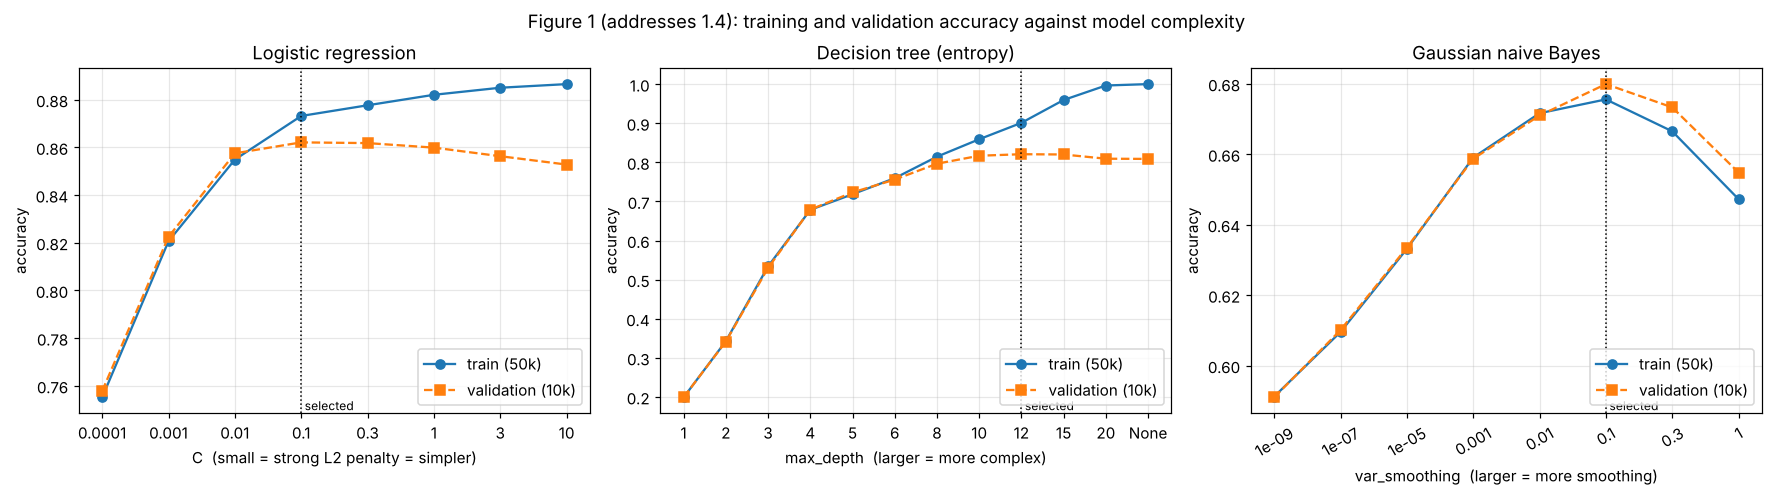

In [7]:
# ---------------- Figure 1: train vs validation across the complexity knob (addresses 1.4) -----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)

x = np.arange(len(lr_df)); ax[0].plot(x, lr_df.train_acc, "o-", label="train (50k)"); ax[0].plot(x, lr_df.val_acc, "s--", label="validation (10k)")
ax[0].set_xticks(x, [f"{c:g}" for c in lr_df.C]); ax[0].set_xlabel("C  (small = strong L2 penalty = simpler)"); ax[0].set_title("Logistic regression")
ax[0].axvline(list(lr_df.C).index(SEL["LR"]), color="k", ls=":", lw=1); ax[0].text(list(lr_df.C).index(SEL["LR"]), ax[0].get_ylim()[0], " selected", va="bottom", fontsize=8)

x = np.arange(len(dt_df)); ax[1].plot(x, dt_df.train_acc, "o-", label="train (50k)"); ax[1].plot(x, dt_df.val_acc, "s--", label="validation (10k)")
ax[1].set_xticks(x, [str(d) for d in dt_df.max_depth], rotation=0); ax[1].set_xlabel("max_depth  (larger = more complex)"); ax[1].set_title("Decision tree (entropy)")
sel_pos = [str(d) for d in dt_df.max_depth].index(str(SEL["DT"])); ax[1].axvline(sel_pos, color="k", ls=":", lw=1); ax[1].text(sel_pos, ax[1].get_ylim()[0], " selected", va="bottom", fontsize=8)

x = np.arange(len(nb_df)); ax[2].plot(x, nb_df.train_acc, "o-", label="train (50k)"); ax[2].plot(x, nb_df.val_acc, "s--", label="validation (10k)")
ax[2].set_xticks(x, [f"{v:g}" for v in nb_df.var_smoothing], rotation=30); ax[2].set_xlabel("var_smoothing  (larger = more smoothing)"); ax[2].set_title("Gaussian naive Bayes")
ax[2].axvline(list(nb_df.var_smoothing).index(SEL["NB"]), color="k", ls=":", lw=1); ax[2].text(list(nb_df.var_smoothing).index(SEL["NB"]), ax[2].get_ylim()[0], " selected", va="bottom", fontsize=8)

for a in ax: a.set_ylabel("accuracy"); a.legend(loc="lower right")
fig.suptitle("Figure 1 (addresses 1.4): training and validation accuracy against model complexity", fontsize=12)
save_fig(fig, "fig1_complexity_train_vs_val", "1.4", "Train (solid, circles) and validation (dashed, squares) accuracy against the complexity knob of each model; dotted line = value selected on validation.")
plt.show()

**Figure 1 (addresses 1.4).** Train (solid) and validation (dashed) accuracy against model complexity; 50,000 train / 10,000 validation images, seed 2208; dotted line = selected value.

**Interpretation.** LR (all 8 fits converged): the train-validation gap is about zero or slightly negative for C ≤ 0.01 and grows to 0.011 (C=0.1), 0.022 (C=1) and 0.034 (C=10). Validation accuracy peaks at C=0.1 (0.8621), is flat to C=1 (0.8599, within sampling error of about ±0.7 points), then falls to 0.8528 at C=10 while log-loss rises from 0.3966 to 0.4564: mild over-fitting. Selected C=0.1. Tree: depth 1 and 2 under-fit (0.1991, 0.3415); validation peaks at depth 12 to 15 (0.8207, 0.8200) and falls to 0.8087 unrestricted while training reaches 1.000. Selected depth 12; three seeds give 0.8207, 0.8201, 0.8156 (mean 0.8188, sample std 0.0028). Naive Bayes: best 0.6799 (var_smoothing 0.1), with over-confident probabilities (log-loss about 4.9 versus 0.40 for LR).

## 1.2 Metrics

Validation set (1,000 images per class), settings selected in 1.4. *Support* = images per class (recall 0.59 means 590 of 1,000).

In [8]:
PRED_VA = {k: timed_predict(m, Xva, k) for k, m in SEL_MODELS.items()}
n = len(yva)
rows = []
for k, p in PRED_VA.items():
    correct = int((p == yva).sum()); lo, hi = wilson_interval(correct, n)
    t = per_class_table(yva, p)
    rows.append({"model": LABEL[k], "correct / n": f"{correct} / {n}", "accuracy": correct / n, "95% interval (sampling)": f"[{lo:.4f}, {hi:.4f}]", "macro-F1": t["F1"].mean()})
overall = pd.DataFrame(rows)
overall.to_csv(RES_DIR / "overall_validation.csv", index=False)
print("Overall accuracy on VALIDATION (majority-class baseline = 0.1000, since the 10 classes are balanced)")
display(overall.style.format({"accuracy": "{:.4f}", "macro-F1": "{:.4f}"}).hide(axis="index"))

tables = {k: per_class_table(yva, p) for k, p in PRED_VA.items()}
wide = tables["LR"][["class", "support"]].copy()
for k in ["LR", "DT", "NB"]:
    wide[f"{k} recall"] = tables[k]["recall"]; wide[f"{k} precision"] = tables[k]["precision"]; wide[f"{k} F1"] = tables[k]["F1"]
wide.to_csv(RES_DIR / "per_class_validation.csv", index=False)
print("Class-level view on VALIDATION (support = images per class)")
display(wide.style.format({c: "{:.3f}" for c in wide.columns if c not in ("class", "support")}).hide(axis="index"))
for k in ["LR", "DT", "NB"]:
    log_experiment(id=f"P1-EVAL-{k}", part_task="1.2", question="Overall and per-class performance of the selected model on validation",
        hypothesis="Footwear and trousers/bags are easy; upper-body garments (shirt, T-shirt, pullover, coat) are hard.", changed_variable="model family",
        fixed_conditions="same 50k train / same 10k validation images / pixels/255", split="validation 10k", seed=SEED_NOTE, configuration=LABEL[k],
        metric="accuracy; per-class precision/recall/F1 with support", result=f"acc={overall.set_index('model').loc[LABEL[k], 'accuracy']:.4f}",
        output_path="results/part1/per_class_validation.csv", notes="single deterministic fit" if k != "DT" else "tree seed spread in tree_seeds.csv")

Overall accuracy on VALIDATION (majority-class baseline = 0.1000, since the 10 classes are balanced)


model,correct / n,accuracy,95% interval (sampling),macro-F1
Logistic regression (C=0.1),8621 / 10000,0.8621,"[0.8552, 0.8687]",0.8618
Decision tree (max_depth=12),8207 / 10000,0.8207,"[0.8131, 0.8281]",0.8209
Gaussian NB (var_smoothing=0.1),6799 / 10000,0.6799,"[0.6707, 0.6890]",0.6690


Class-level view on VALIDATION (support = images per class)


class,support,LR recall,LR precision,LR F1,DT recall,DT precision,DT F1,NB recall,NB precision,NB F1
T-shirt/top,1000,0.836,0.796,0.816,0.781,0.788,0.785,0.692,0.752,0.721
Trouser,1000,0.966,0.989,0.977,0.942,0.964,0.953,0.915,0.910,0.913
Pullover,1000,0.779,0.767,0.773,0.723,0.727,0.725,0.410,0.662,0.506
Dress,1000,0.867,0.863,0.865,0.831,0.858,0.844,0.850,0.610,0.710
Coat,1000,0.783,0.751,0.767,0.767,0.663,0.711,0.672,0.505,0.577
Sandal,1000,0.934,0.950,0.942,0.887,0.904,0.896,0.451,0.592,0.512
Shirt,1000,0.606,0.657,0.631,0.568,0.617,0.591,0.231,0.380,0.287
Sneaker,1000,0.942,0.938,0.940,0.871,0.876,0.874,0.950,0.591,0.729
Bag,1000,0.944,0.955,0.950,0.919,0.940,0.929,0.800,0.939,0.864
Ankle boot,1000,0.964,0.952,0.958,0.918,0.885,0.901,0.828,0.919,0.871


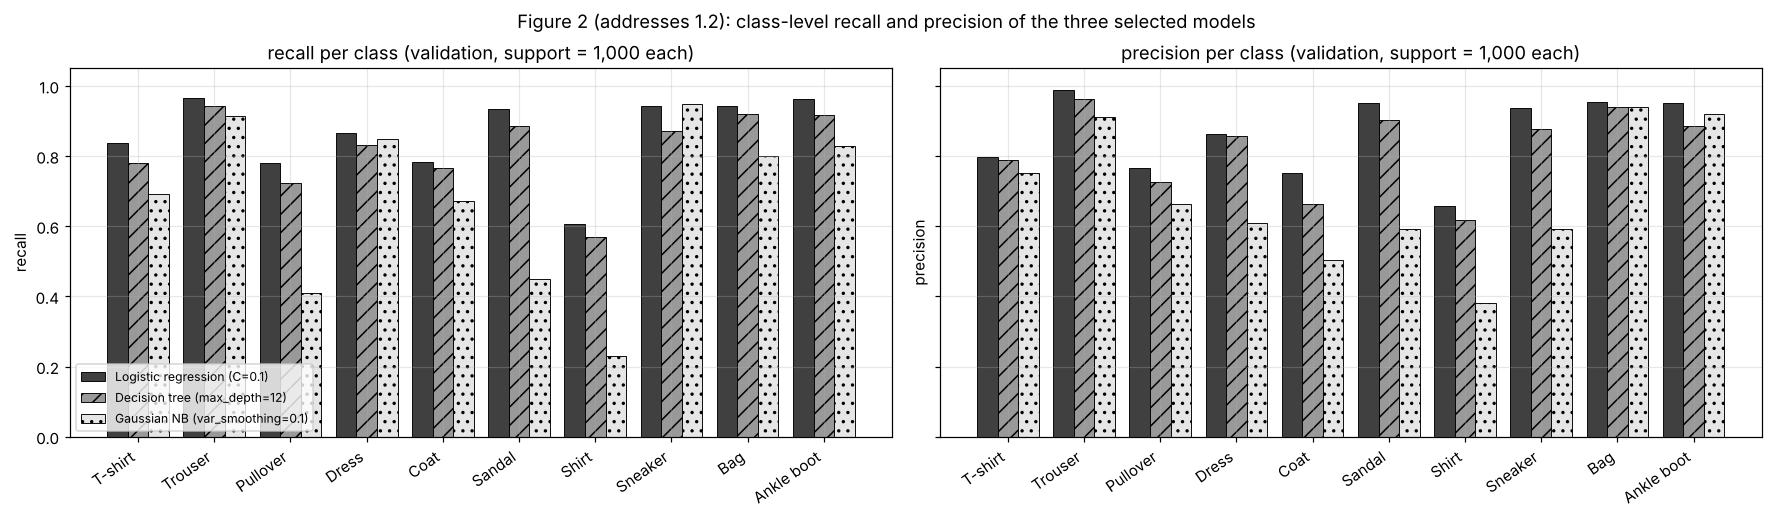

In [9]:
# ---------------- Figure 2: class-level recall and precision (addresses 1.2) -----------------
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), constrained_layout=True, sharey=True)
w = 0.27; xs = np.arange(10); hatches = {"LR": "", "DT": "//", "NB": ".."}; shade = {"LR": "0.25", "DT": "0.6", "NB": "0.9"}
for a, col in zip(ax, ["recall", "precision"]):
    for j, k in enumerate(["LR", "DT", "NB"]):
        bars = a.bar(xs + (j - 1) * w, tables[k][col], w, label=LABEL[k], hatch=hatches[k], facecolor=shade[k], edgecolor="k", lw=0.6)
    a.set_xticks(xs, SHORT, rotation=35, ha="right"); a.set_ylim(0, 1.05); a.set_title(f"{col} per class (validation, support = 1,000 each)"); a.set_ylabel(col)
ax[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure 2 (addresses 1.2): class-level recall and precision of the three selected models", fontsize=12)
save_fig(fig, "fig2_per_class_recall_precision", "1.2", "Recall and precision per class on the validation set for the three selected models (patterns distinguish the models).")
plt.show()

**Figure 2 (addresses 1.2).** Per-class recall and precision, validation set, selected models.

**Interpretation.** Validation accuracy (settings were selected on this same set, so these values are slightly optimistic): LR 0.8621 (95% interval [0.8552, 0.8687]), tree 0.8207 ([0.8131, 0.8281]), naive Bayes 0.6799 (chance 0.10). Recall is highest for Ankle boot (LR 0.964) and Trouser (0.966) and lowest for Shirt (0.606), Pullover (0.779) and Coat (0.783); the same classes are weakest for all three models (tree Shirt recall 0.568, naive Bayes 0.231), so the difficulty comes mostly from the data. Naive Bayes over-predicts Dress (precision 0.610). *Likely reasons for the order LR > tree > naive Bayes (explanations, not tested here):* LR combines all 784 pixels in one weighted sum per class; a depth-12 tree asks at most 12 single-pixel questions per image; naive Bayes treats neighbouring pixels as independent although they are strongly correlated, so it counts the same evidence repeatedly, which fits its over-confident probabilities.

## 1.3 Error analysis

**Hypothesis.** Errors concentrate among upper-body garments with similar silhouettes.

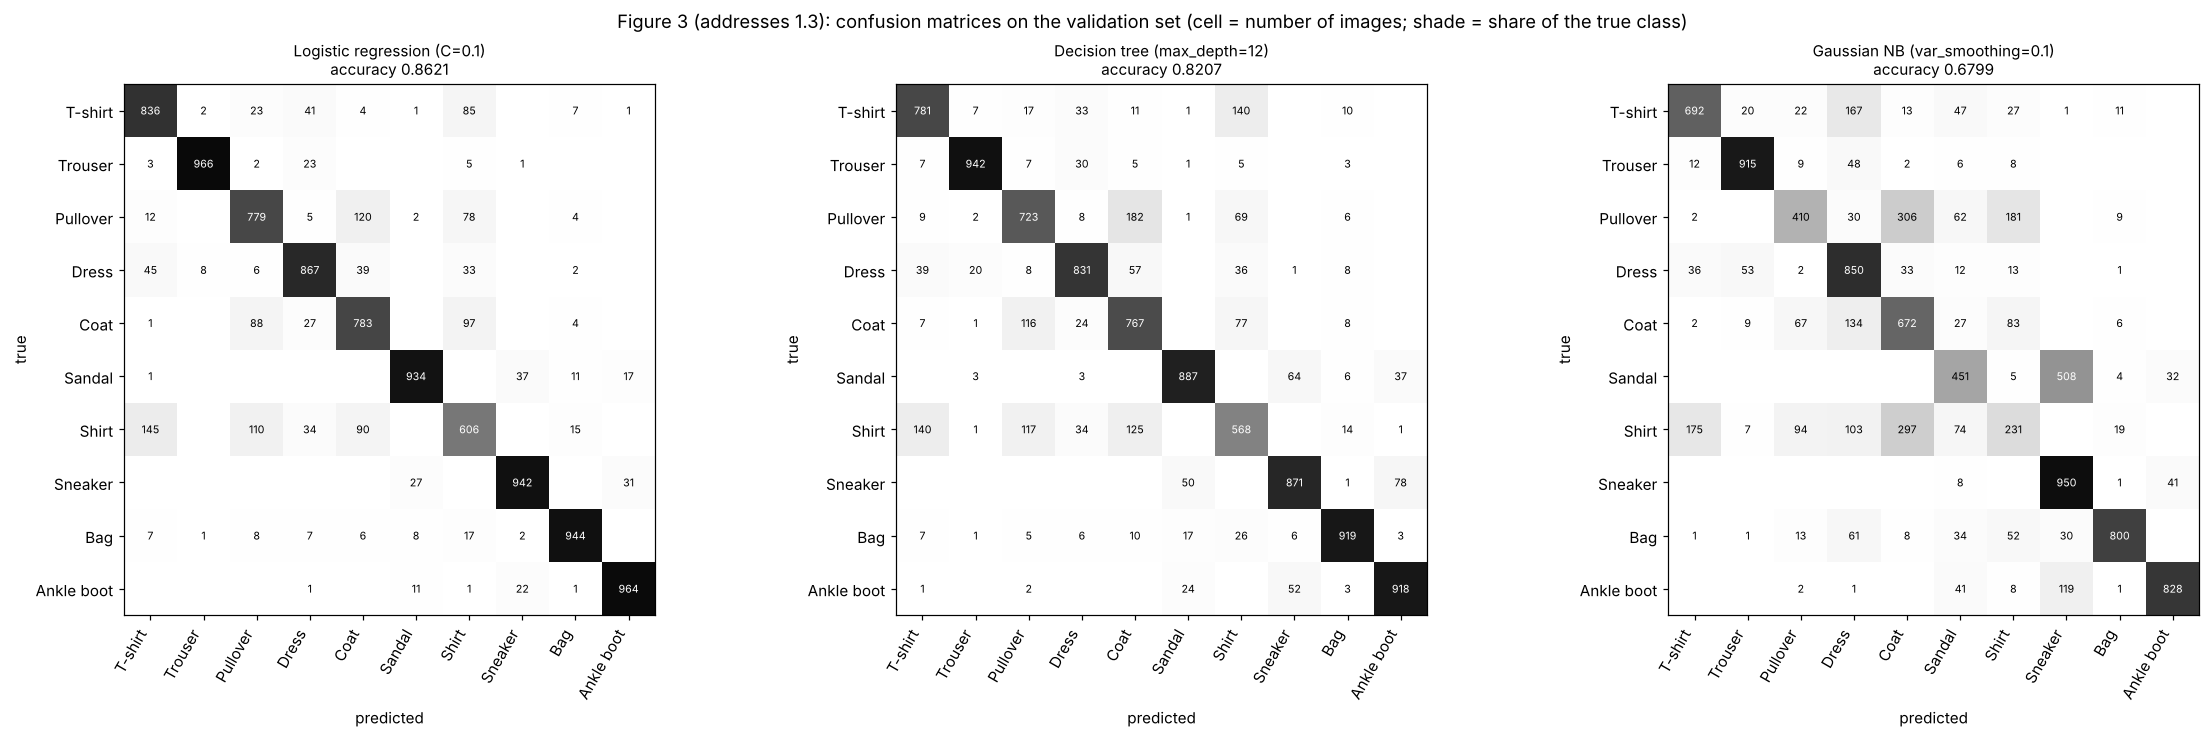

Most frequent confusions, Logistic regression (C=0.1) (validation):


true,predicted,count,share of true class
Shirt,T-shirt/top,145,0.145
Pullover,Coat,120,0.120
Shirt,Pullover,110,0.110
Coat,Shirt,97,0.097
Shirt,Coat,90,0.090
Coat,Pullover,88,0.088


Most frequent confusions, Decision tree (max_depth=12) (validation):


true,predicted,count,share of true class
Pullover,Coat,182,0.182
T-shirt/top,Shirt,140,0.140
Shirt,T-shirt/top,140,0.140
Shirt,Coat,125,0.125
Shirt,Pullover,117,0.117
Coat,Pullover,116,0.116


Most frequent confusions, Gaussian NB (var_smoothing=0.1) (validation):


true,predicted,count,share of true class
Sandal,Sneaker,508,0.508
Pullover,Coat,306,0.306
Shirt,Coat,297,0.297
Pullover,Shirt,181,0.181
Shirt,T-shirt/top,175,0.175
T-shirt/top,Dress,167,0.167


In [10]:
# ---------------- Figure 3: row-normalised confusion matrices (addresses 1.3) -----------------
fig, ax = plt.subplots(1, 3, figsize=(21, 6.6), constrained_layout=True)
CMS = {}
for a, k in zip(ax, ["LR", "DT", "NB"]):
    cm = confusion_matrix(yva, PRED_VA[k], labels=range(10)); CMS[k] = cm
    a.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            v = cm[i, j]
            if v > 0: a.text(j, i, f"{v}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
    a.set_xticks(range(10), SHORT, rotation=60, ha="right"); a.set_yticks(range(10), SHORT); a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
    a.set_title(f"{LABEL[k]}\naccuracy {np.trace(cm) / cm.sum():.4f}", fontsize=10)
fig.suptitle("Figure 3 (addresses 1.3): confusion matrices on the validation set (cell = number of images; shade = share of the true class)", fontsize=12)
save_fig(fig, "fig3_confusion_matrices", "1.3", "Confusion matrices (counts; shading = row-normalised share) for the three selected models on the validation set.")
plt.show()

for k in ["LR", "DT", "NB"]:
    print(f"Most frequent confusions, {LABEL[k]} (validation):")
    display(top_confusions(yva, PRED_VA[k], 6).style.format({"share of true class": "{:.3f}"}).hide(axis="index"))

Agreement of LR and tree on the SAME 10,000 validation images


,DT correct,DT wrong
LR correct,7677,944
LR wrong,530,849


Exact McNemar test: only LR right 944, only tree right 530, p = 2.5e-27


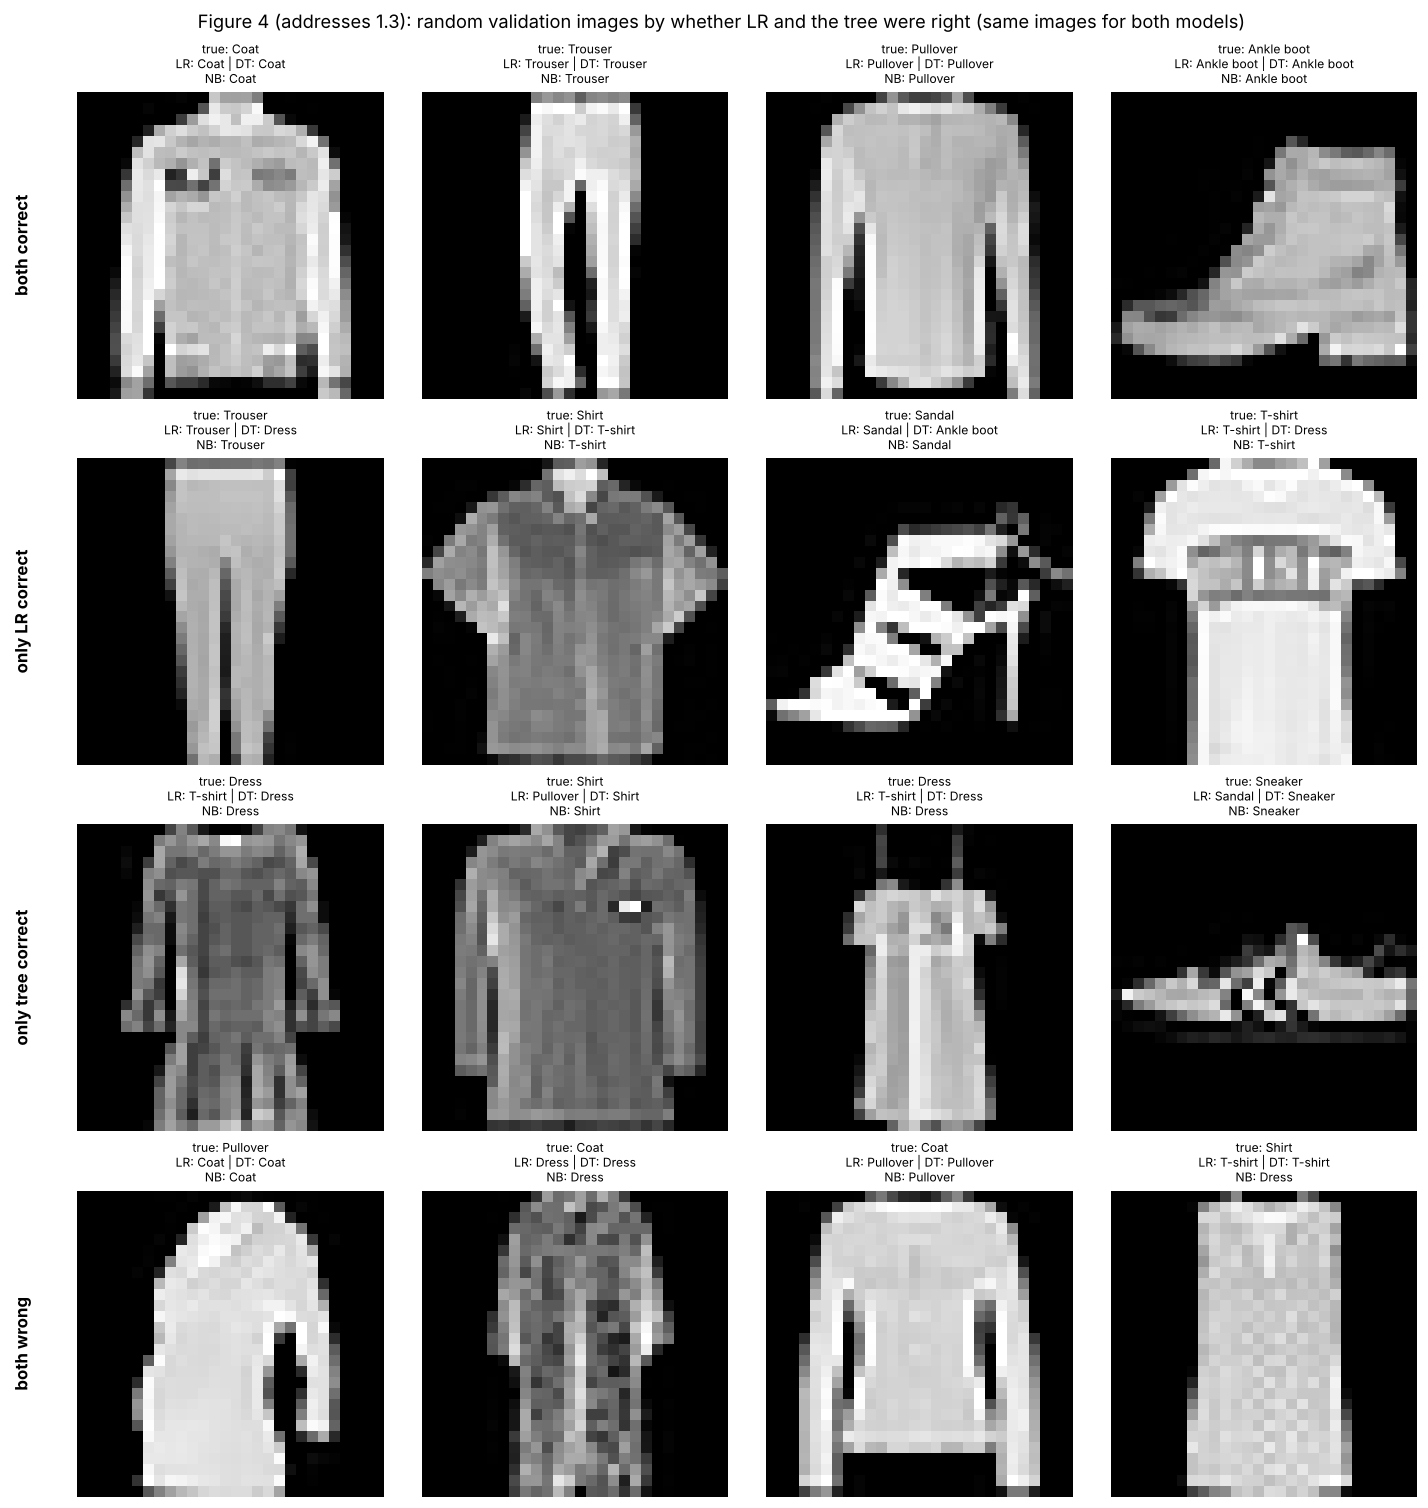

Classes from hardest to easiest (validation, mean F1 over the three models)


class,mean F1 over 3 models
Shirt,0.503
Pullover,0.668
Coat,0.685
T-shirt/top,0.774
Sandal,0.783
Dress,0.806
Sneaker,0.847
Ankle boot,0.910
Bag,0.914
Trouser,0.948


In [11]:
# ---------------- Same images, two models: agreement table and a fixed random example grid (addresses 1.3) -----------------
lr_ok = PRED_VA["LR"] == yva; dt_ok = PRED_VA["DT"] == yva
agree = pd.DataFrame({"DT correct": [int((lr_ok & dt_ok).sum()), int((~lr_ok & dt_ok).sum())],
                      "DT wrong":   [int((lr_ok & ~dt_ok).sum()), int((~lr_ok & ~dt_ok).sum())]}, index=["LR correct", "LR wrong"])
print("Agreement of LR and tree on the SAME 10,000 validation images"); display(agree)
log_experiment(id="P1-ERR-01", part_task="1.3", question="Do LR and the tree fail on the same validation images?",
    hypothesis="Largely the same hard classes, but different individual images, because the models use pixels differently.", changed_variable="model family",
    fixed_conditions="identical validation images", split="validation 10k", seed=SEED_NOTE, configuration=f"{LABEL['LR']} vs {LABEL['DT']}",
    metric="2x2 agreement counts", result=agree.to_dict(), output_path="results/part1/agreement_lr_dt.csv", notes="")
agree.to_csv(RES_DIR / "agreement_lr_dt.csv")
from scipy.stats import binomtest
only_lr, only_dt = int((lr_ok & ~dt_ok).sum()), int((~lr_ok & dt_ok).sum())
P_MCNEMAR = binomtest(only_dt, only_lr + only_dt, 0.5).pvalue   # exact McNemar test on the disagreements
print(f"Exact McNemar test: only LR right {only_lr}, only tree right {only_dt}, p = {P_MCNEMAR:.1e}")

rng = np.random.default_rng(SEED)           # fixed seed: images are drawn at random, not hand-picked
groups = {"both correct": np.flatnonzero(lr_ok & dt_ok), "only LR correct": np.flatnonzero(lr_ok & ~dt_ok),
          "only tree correct": np.flatnonzero(~lr_ok & dt_ok), "both wrong": np.flatnonzero(~lr_ok & ~dt_ok)}
fig, ax = plt.subplots(4, 4, figsize=(13, 13.6), constrained_layout=True)
for r, (g, idx) in enumerate(groups.items()):
    chosen = rng.choice(idx, size=min(4, len(idx)), replace=False)
    for c in range(4):
        a = ax[r, c]; a.axis("off")
        if c < len(chosen):
            i = chosen[c]; a.imshow(Xva[i].reshape(28, 28), cmap="gray")
            a.set_title(f"true: {SHORT[yva[i]]}\nLR: {SHORT[PRED_VA['LR'][i]]} | DT: {SHORT[PRED_VA['DT'][i]]}\nNB: {SHORT[PRED_VA['NB'][i]]}", fontsize=8)
    ax[r, 0].text(-0.15, 0.5, g, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
fig.suptitle("Figure 4 (addresses 1.3): random validation images by whether LR and the tree were right (same images for both models)", fontsize=12)
save_fig(fig, "fig4_error_examples", "1.3", "Four randomly drawn validation images (seed 2208) per agreement group; titles give the true class and the predictions of LR, tree and NB.")
plt.show()

rank = wide[["class"]].copy(); rank["mean F1 over 3 models"] = wide[["LR F1", "DT F1", "NB F1"]].mean(axis=1); rank = rank.sort_values("mean F1 over 3 models")
print("Classes from hardest to easiest (validation, mean F1 over the three models)"); display(rank.style.format({"mean F1 over 3 models": "{:.3f}"}).hide(axis="index"))

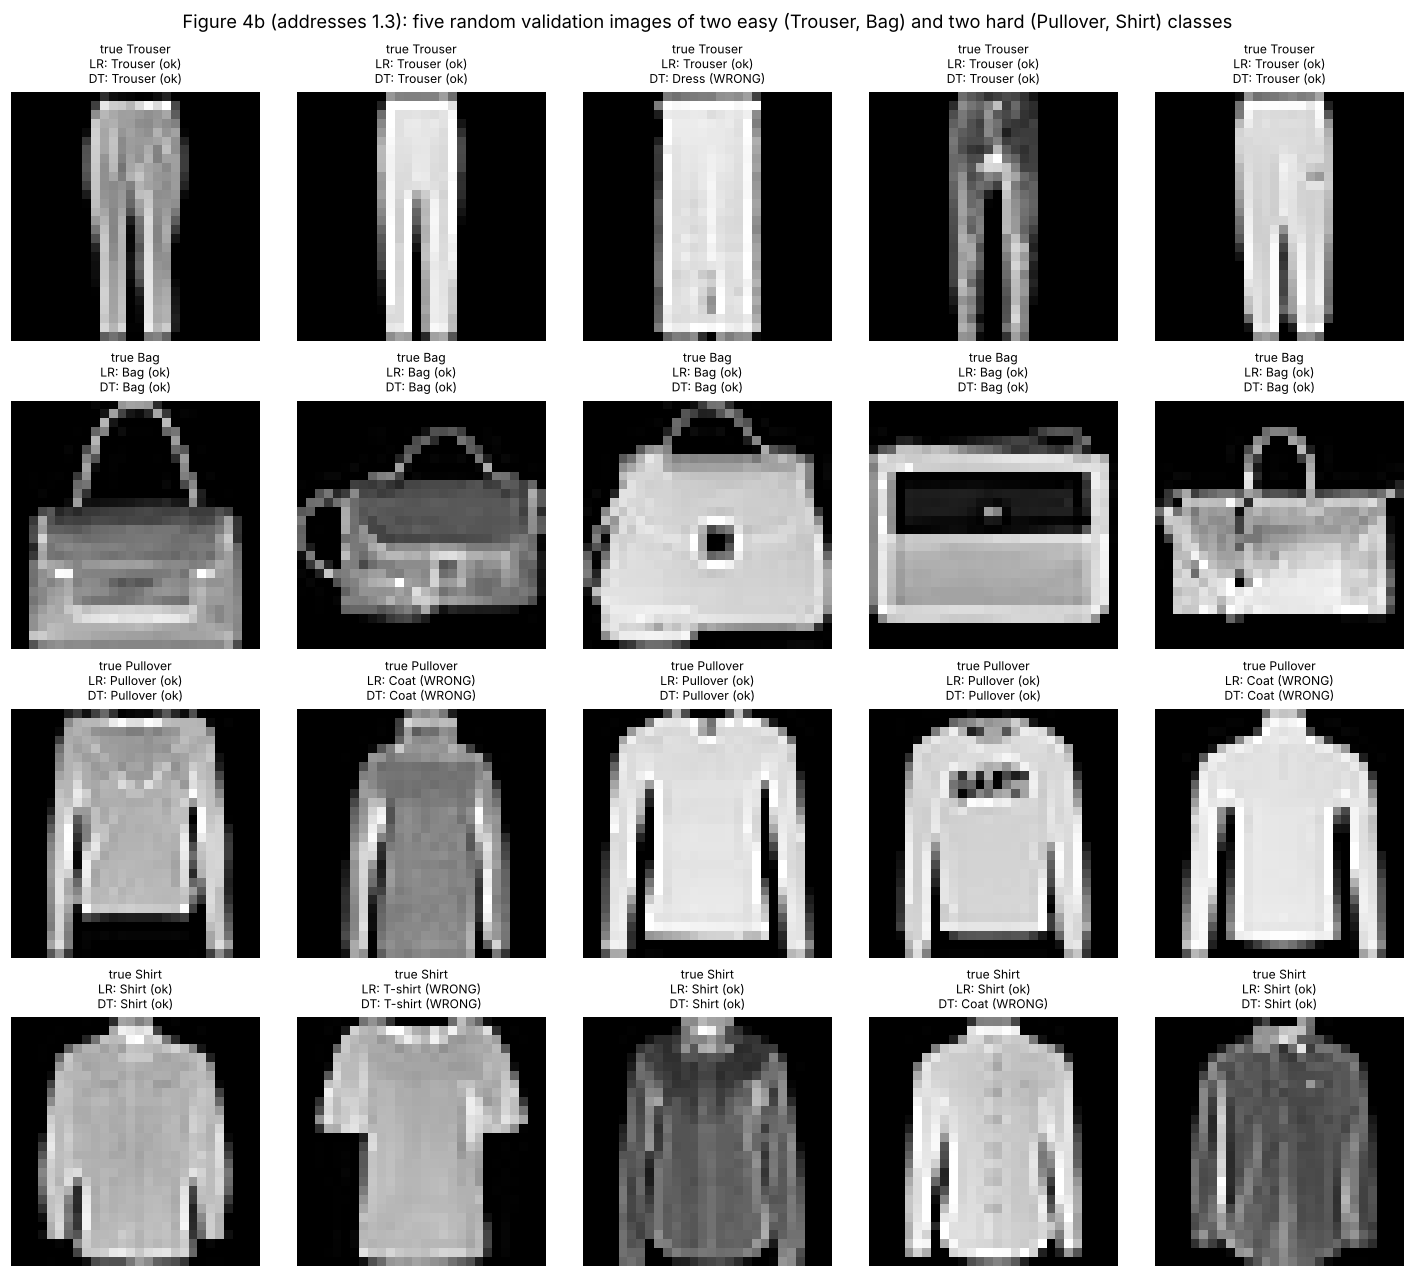

In [12]:
# ---------------- Figure 4b: easy and hard classes side by side, random validation images of ONE class each (addresses 1.3) -----------------
rng2 = np.random.default_rng(SEED + 1)                       # seeded sample, same images shown for every model
focus = [("Trouser", 1), ("Bag", 8), ("Pullover", 2), ("Shirt", 6)]       # two easy and two hard classes (by the F1 ranking above)
fig, ax = plt.subplots(4, 5, figsize=(13, 11.5), constrained_layout=True)
for r, (nm, c) in enumerate(focus):
    for j, i in enumerate(rng2.choice(np.flatnonzero(yva == c), 5, replace=False)):
        a = ax[r, j]; a.imshow(Xva[i].reshape(28, 28), cmap="gray"); a.axis("off")
        ok = lambda k: "ok" if PRED_VA[k][i] == yva[i] else "WRONG"
        a.set_title(f"true {nm}\nLR: {SHORT[PRED_VA['LR'][i]]} ({ok('LR')})\nDT: {SHORT[PRED_VA['DT'][i]]} ({ok('DT')})", fontsize=8)
fig.suptitle("Figure 4b (addresses 1.3): five random validation images of two easy (Trouser, Bag) and two hard (Pullover, Shirt) classes", fontsize=12)
save_fig(fig, "fig4b_easy_vs_hard_classes", "1.3", "Five seeded random validation images for each of two easy and two hard classes, with LR and tree predictions.")
plt.show()

**Figures 4 and 4b (addresses 1.3).** Seeded random validation images, the same for both models: by LR/tree agreement (Fig. 4) and for two easy and two hard classes (Fig. 4b).

**Interpretation.** Hardest classes by mean F1 over the three models: Shirt (0.503), Pullover (0.668), Coat (0.685); easiest: Trouser (0.948), Bag (0.914), Ankle boot (0.910). The most frequent LR confusions are upper-body pairs (Shirt to T-shirt 145, Pullover to Coat 120, Shirt to Pullover 110 per 1,000); the tree shows the same group (Pullover to Coat 182, T-shirt and Shirt confused both ways, 140 each). On the same 10,000 images both models are right on 7,677 and both wrong on 849; only LR is right on 944, only the tree on 530 (exact McNemar test on these 1,474 disagreements: p < 1e-6, so the accuracy gap is not sampling noise): they fail in the same regions, not on the same images, so the models are close on which classes are hard and differ in how many images of those classes they get right. Fig. 4b (five images per class, illustration only): easy classes are almost always right (9 of 10 images correct for both models; one plain wide trouser is called Dress by the tree); the wrong Pullover cases are close-fitting high-collar tops called Coat, and a short-sleeved Shirt is called T-shirt by both models.

## 1.5 Decisions and costs

**Problem.** *Shirt versus the rest*, for a shop filing photos automatically. Positive = Shirt: 1,000 of 10,000 validation images (10%), so "never Shirt" is already 90% accurate. **Score:** predicted probability of Shirt, flagged if ≥ threshold *t*. Tree scores are leaf proportions and naive Bayes scores are over-confident, so only LR's are treated as probabilities. **Costs (assumptions, per item):** A: miss 1, false alarm 1; B: miss 5, false alarm 1; C: miss 1, false alarm 5.

**Hypotheses.** LR has the best ROC; the best threshold falls when misses cost more and rises when false alarms cost more, near c<sub>FP</sub>/(c<sub>FP</sub>+c<sub>FN</sub>) = 0.5, 0.167, 0.833 if LR is calibrated. Thresholds are chosen on validation only.

In [13]:
SHIRT = CLASS_NAMES.index("Shirt"); y_bin = (yva == SHIRT).astype(int); N = len(y_bin); prev = y_bin.mean()
SCORES = {k: m.predict_proba(Xva)[:, SHIRT] for k, m in SEL_MODELS.items()}
SCEN = {"A: balanced (FN 1, FP 1)": (1, 1), "B: missed shirt 5x worse (FN 5, FP 1)": (5, 1), "C: false alarm 5x worse (FN 1, FP 5)": (1, 5)}
TS = np.linspace(0, 1, 1001)

def counts_at(score, t):
    pred = score >= t
    return int((pred & (y_bin == 1)).sum()), int((pred & (y_bin == 0)).sum()), int((~pred & (y_bin == 1)).sum()), int((~pred & (y_bin == 0)).sum())  # TP FP FN TN

CURVE = {k: np.array([counts_at(s, t) for t in TS]) for k, s in SCORES.items()}   # columns TP FP FN TN for every threshold
def cost_curve(k, cfn, cfp): c = CURVE[k]; return (cfn * c[:, 2] + cfp * c[:, 1]) / N

# ---- ROC / AUC on validation
ROC = {k: roc_curve(y_bin, s) for k, s in SCORES.items()}; AUC = {k: roc_auc_score(y_bin, s) for k, s in SCORES.items()}
print("Shirt-vs-rest, validation: prevalence", prev, "| 'never shirt' accuracy", 1 - prev)
print("ROC AUC:", {LABEL[k]: round(v, 4) for k, v in AUC.items()})

# ---- LR at a few thresholds
rows = []
for t in [0.05, 0.1, 0.167, 0.2, 0.3, 0.5, 0.7, 0.833, 0.9]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    rows.append({"threshold": t, "TP": TP, "FP": FP, "FN": FN, "TN": TN, "TPR (recall)": TP / (TP + FN), "FPR": FP / (FP + TN),
                 "precision": TP / max(TP + FP, 1), "accuracy": (TP + TN) / N})
thr_table = pd.DataFrame(rows); thr_table.to_csv(RES_DIR / "shirt_threshold_table_lr.csv", index=False)
print("Logistic regression: confusion counts and rates at several thresholds (validation)")
display(thr_table.style.format({"threshold": "{:.3f}", "TPR (recall)": "{:.3f}", "FPR": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.4f}"}).hide(axis="index"))

# ---- cost-minimising thresholds on validation
rows = []; BEST_T = {}
for sname, (cfn, cfp) in SCEN.items():
    for k in ["LR", "DT", "NB"]:
        cc = cost_curve(k, cfn, cfp); j = int(np.argmin(cc)); t_star = float(TS[j])
        if k == "LR": BEST_T[sname] = t_star
        rows.append({"scenario": sname, "model": k, "best threshold": t_star, "expected cost @ best": cc[j], "expected cost @ 0.5": cc[500],
                     "never-shirt baseline": cfn * prev, "calibrated-theory threshold": cfp / (cfp + cfn)})
cost_table = pd.DataFrame(rows); cost_table.to_csv(RES_DIR / "shirt_cost_table.csv", index=False)
print("Expected cost per item on validation (lower is better)")
display(cost_table.style.format({"best threshold": "{:.3f}", "expected cost @ best": "{:.4f}", "expected cost @ 0.5": "{:.4f}", "never-shirt baseline": "{:.4f}", "calibrated-theory threshold": "{:.3f}"}).hide(axis="index"))
for sname in SCEN:
    log_experiment(id=f"P1-THR-{sname[0]}", part_task="1.5", question="How does the decision threshold trade false negatives against false positives, and where is the cost minimum?",
        hypothesis="Optimal threshold moves down when FN is costlier and up when FP is costlier; near cFP/(cFP+cFN) if calibrated.", changed_variable="decision threshold (and cost ratio)",
        fixed_conditions="Shirt-vs-rest from selected LR scores; same validation images", split="validation 10k", seed=SEED_NOTE, configuration=sname,
        metric="expected cost per item; TPR/FPR", result=f"best threshold (LR) = {BEST_T[sname]:.3f}", output_path="results/part1/shirt_cost_table.csv", notes="costs are illustrative assumptions")

Shirt-vs-rest, validation: prevalence 0.1 | 'never shirt' accuracy 0.9
ROC AUC: {'Logistic regression (C=0.1)': 0.9449, 'Decision tree (max_depth=12)': 0.8781, 'Gaussian NB (var_smoothing=0.1)': 0.7131}
Logistic regression: confusion counts and rates at several thresholds (validation)


threshold,TP,FP,FN,TN,TPR (recall),FPR,precision,accuracy
0.050,948,2094,52,6906,0.948,0.233,0.312,0.7854
0.100,893,1453,107,7547,0.893,0.161,0.381,0.8440
0.167,830,988,170,8012,0.830,0.110,0.457,0.8842
0.200,803,796,197,8204,0.803,0.088,0.502,0.9007
0.300,697,506,303,8494,0.697,0.056,0.579,0.9191
0.500,526,198,474,8802,0.526,0.022,0.727,0.9328
0.700,329,56,671,8944,0.329,0.006,0.855,0.9273
0.833,197,18,803,8982,0.197,0.002,0.916,0.9179
0.900,94,4,906,8996,0.094,0.000,0.959,0.9090


Expected cost per item on validation (lower is better)


scenario,model,best threshold,expected cost @ best,expected cost @ 0.5,never-shirt baseline,calibrated-theory threshold
"A: balanced (FN 1, FP 1)",LR,0.524,0.0667,0.0672,0.1000,0.500
"A: balanced (FN 1, FP 1)",DT,0.706,0.0742,0.0772,0.1000,0.500
"A: balanced (FN 1, FP 1)",NB,1.000,0.1111,0.1146,0.1000,0.500
"B: missed shirt 5x worse (FN 5, FP 1)",LR,0.199,0.1776,0.2568,0.5000,0.167
"B: missed shirt 5x worse (FN 5, FP 1)",DT,0.188,0.2121,0.2680,0.5000,0.167
"B: missed shirt 5x worse (FN 5, FP 1)",NB,0.003,0.4193,0.4222,0.5000,0.167
"C: false alarm 5x worse (FN 1, FP 5)",LR,0.829,0.0890,0.1464,0.1000,0.833
"C: false alarm 5x worse (FN 1, FP 5)",DT,0.957,0.1106,0.1952,0.1000,0.833
"C: false alarm 5x worse (FN 1, FP 5)",NB,1.000,0.2351,0.2654,0.1000,0.833


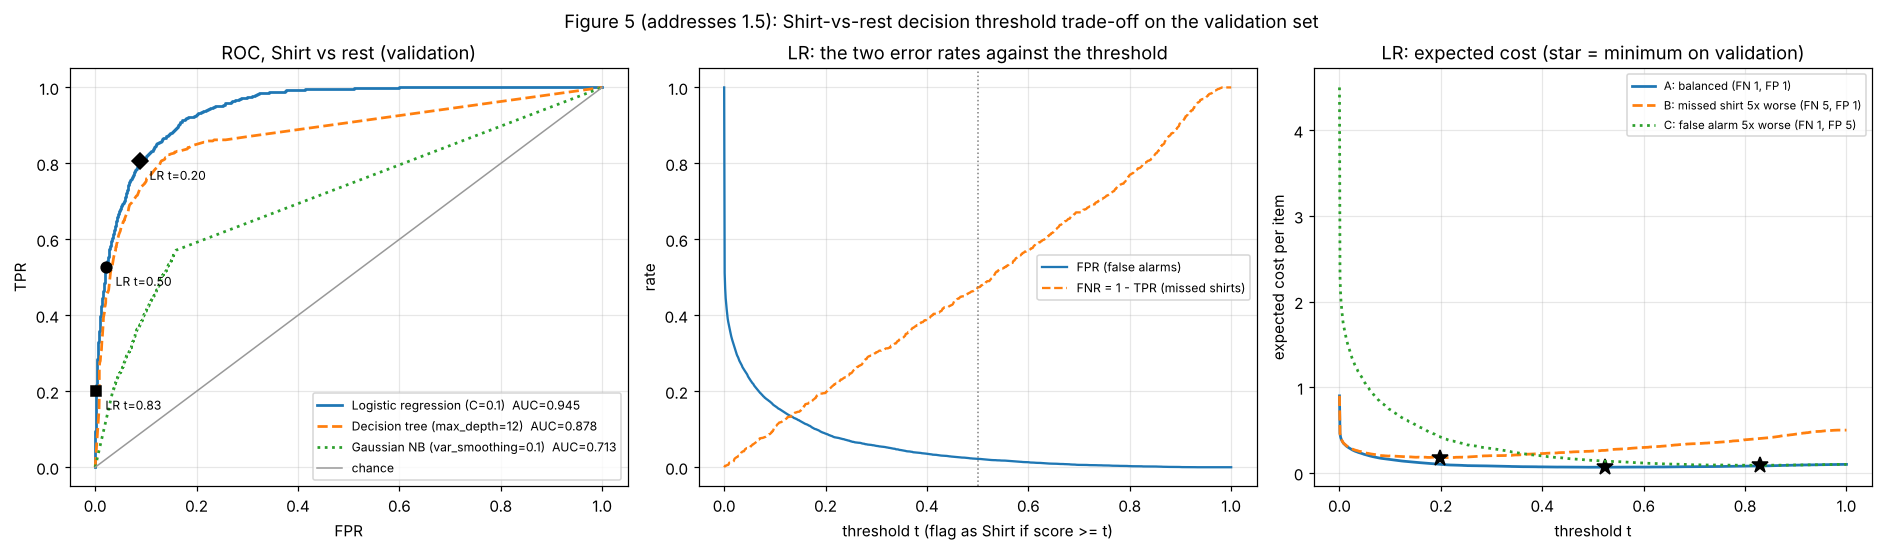

LR, scenario A: balanced (FN 1, FP 1): threshold 0.524 -> TP 508, FP 175, FN 492, TN 8825  (TPR 0.508, FPR 0.019, precision 0.744)
LR, scenario B: missed shirt 5x worse (FN 5, FP 1): threshold 0.199 -> TP 805, FP 801, FN 195, TN 8199  (TPR 0.805, FPR 0.089, precision 0.501)
LR, scenario C: false alarm 5x worse (FN 1, FP 5): threshold 0.829 -> TP 200, FP 18, FN 800, TN 8982  (TPR 0.200, FPR 0.002, precision 0.917)


In [14]:
# ---------------- Figure 5: ROC and threshold trade-off on validation (addresses 1.5) -----------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), constrained_layout=True)
styles = {"LR": ("-", "o"), "DT": ("--", "s"), "NB": (":", "^")}
for k in ["LR", "DT", "NB"]:
    f, tpr, _ = ROC[k]; ax[0].plot(f, tpr, ls=styles[k][0], lw=1.8, label=f"{LABEL[k]}  AUC={AUC[k]:.3f}")
ax[0].plot([0, 1], [0, 1], color="0.6", lw=1, label="chance")
for t, mk in [(0.5, "o"), (BEST_T["B: missed shirt 5x worse (FN 5, FP 1)"], "D"), (BEST_T["C: false alarm 5x worse (FN 1, FP 5)"], "s")]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t); ax[0].plot(FP / (FP + TN), TP / (TP + FN), mk, color="k", ms=7); ax[0].annotate(f"LR t={t:.2f}", (FP / (FP + TN), TP / (TP + FN)), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC, Shirt vs rest (validation)"); ax[0].legend(loc="lower right", fontsize=8)

c = CURVE["LR"]; ax[1].plot(TS, c[:, 1] / (c[:, 1] + c[:, 3]), "-", label="FPR (false alarms)"); ax[1].plot(TS, c[:, 2] / (c[:, 0] + c[:, 2]), "--", label="FNR = 1 - TPR (missed shirts)")
ax[1].axvline(0.5, color="0.5", lw=1, ls=":"); ax[1].set_xlabel("threshold t (flag as Shirt if score >= t)"); ax[1].set_ylabel("rate"); ax[1].set_title("LR: the two error rates against the threshold"); ax[1].legend(fontsize=8)

for (sname, (cfn, cfp)), ls in zip(SCEN.items(), ["-", "--", ":"]):
    cc = cost_curve("LR", cfn, cfp); ax[2].plot(TS, cc, ls=ls, lw=1.8, label=sname); j = int(np.argmin(cc)); ax[2].plot(TS[j], cc[j], "k*", ms=11)
ax[2].set_xlabel("threshold t"); ax[2].set_ylabel("expected cost per item"); ax[2].set_title("LR: expected cost (star = minimum on validation)"); ax[2].legend(fontsize=7.5)
fig.suptitle("Figure 5 (addresses 1.5): Shirt-vs-rest decision threshold trade-off on the validation set", fontsize=12)
save_fig(fig, "fig5_threshold_tradeoff", "1.5", "ROC curves of the three models; LR error rates against threshold; LR expected cost per item against threshold for three cost scenarios (validation).")
plt.show()

for sname, t in BEST_T.items():
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    print(f"LR, scenario {sname}: threshold {t:.3f} -> TP {TP}, FP {FP}, FN {FN}, TN {TN}  (TPR {TP/(TP+FN):.3f}, FPR {FP/(FP+TN):.3f}, precision {TP/max(TP+FP,1):.3f})")

In [15]:
# ---------------- Calibration check of the LR Shirt score (supports the 'calibrated' hypothesis iii) -----------------
bins = np.array([0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0001]); b = np.digitize(SCORES["LR"], bins) - 1
cal = pd.DataFrame({"score bin": [f"[{bins[i]:.2f}, {min(bins[i+1], 1):.2f})" for i in range(len(bins) - 1)],
                    "n images": [int((b == i).sum()) for i in range(len(bins) - 1)],
                    "mean predicted P(Shirt)": [SCORES["LR"][b == i].mean() if (b == i).any() else np.nan for i in range(len(bins) - 1)],
                    "observed share of Shirts": [y_bin[b == i].mean() if (b == i).any() else np.nan for i in range(len(bins) - 1)]})
cal.to_csv(RES_DIR / "shirt_calibration_lr.csv", index=False)
print("LR calibration on validation: if the probabilities were calibrated the last two columns would agree"); display(cal.style.format({"mean predicted P(Shirt)": "{:.3f}", "observed share of Shirts": "{:.3f}"}).hide(axis="index"))

# ---------------- Chosen operating point (primary scenario B), chosen on VALIDATION and frozen -----------------
PRIMARY = "B: missed shirt 5x worse (FN 5, FP 1)"; T_OP = BEST_T[PRIMARY]; cfn, cfp = SCEN[PRIMARY]
rows = []
for name, t in [("LR, default t = 0.5", 0.5), (f"LR, chosen operating point t = {T_OP:.3f}", T_OP)]:
    TP, FP, FN, TN = counts_at(SCORES["LR"], t)
    rows.append({"decision rule": name, "TP": TP, "FP": FP, "FN": FN, "TN": TN, "TPR": TP / (TP + FN), "FPR": FP / (FP + TN), "precision": TP / max(TP + FP, 1), "accuracy": (TP + TN) / N, f"cost/item (B)": (cfn * FN + cfp * FP) / N})
rows.insert(0, {"decision rule": "never flag Shirt", "TP": 0, "FP": 0, "FN": int(y_bin.sum()), "TN": int((1 - y_bin).sum()), "TPR": 0.0, "FPR": 0.0, "precision": np.nan, "accuracy": 1 - prev, "cost/item (B)": cfn * prev})
op = pd.DataFrame(rows); op.to_csv(RES_DIR / "shirt_operating_point.csv", index=False)
print(f"Operating point for scenario B (validation, 1,000 Shirts / 9,000 others):"); display(op.style.format({"TPR": "{:.3f}", "FPR": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.4f}", "cost/item (B)": "{:.4f}"}).hide(axis="index"))

LR calibration on validation: if the probabilities were calibrated the last two columns would agree


score bin,n images,mean predicted P(Shirt),observed share of Shirts
"[0.00, 0.05)",6958,0.006,0.007
"[0.05, 0.10)",696,0.072,0.079
"[0.10, 0.20)",747,0.147,0.120
"[0.20, 0.30)",396,0.244,0.268
"[0.30, 0.50)",479,0.392,0.357
"[0.50, 0.70)",339,0.596,0.581
"[0.70, 0.90)",287,0.811,0.819
"[0.90, 1.00)",98,0.933,0.959


Operating point for scenario B (validation, 1,000 Shirts / 9,000 others):


decision rule,TP,FP,FN,TN,TPR,FPR,precision,accuracy,cost/item (B)
never flag Shirt,0,0,1000,9000,0.000,0.000,nan,0.9000,0.5000
"LR, default t = 0.5",526,198,474,8802,0.526,0.022,0.727,0.9328,0.2568
"LR, chosen operating point t = 0.199",805,801,195,8199,0.805,0.089,0.501,0.9004,0.1776


**Chosen operating point.** Scenario B, LR, validation-optimal threshold (frozen below). *Assumption:* a shirt in the wrong category is a lost sale; a wrong item among shirts is cheap to correct.

**Figure 5 (addresses 1.5).** ROC curves, LR error rates and LR expected cost against the threshold; validation data, selected models, seed 2208.

**Interpretation.** ROC AUC (Shirt vs rest, validation): LR 0.945, tree 0.878, naive Bayes 0.713. Naive Bayes is no better than "never Shirt" in A (cost 0.1111 vs 0.100); LR beats it in A (0.0667), B (0.1776 vs 0.500) and narrowly in C (0.0890 vs 0.100). Lowering t from 0.5 to 0.1 raises LR's TPR from 0.526 to 0.893 but also FPR from 0.022 to 0.161. The optimal LR thresholds are 0.524 (A), 0.199 (B) and 0.829 (C): down when misses cost more, up when false alarms cost more, near 0.5, 0.167, 0.833; the calibration table agrees within 0.04 per bin. **Chosen point (B, t=0.199):** 805 of 1,000 shirts found with 801 false flags (precision 0.501); cost 0.1776 per item vs 0.2568 at t=0.5 and 0.500 for "never Shirt"; accuracy falls to 0.9004, so accuracy is not the criterion. Thresholds are tuned and evaluated on the same validation images, so costs are slightly optimistic.

## Limitations of Part 1

* One fixed split and one validation set: differences below about 0.5 points are unreliable (e.g. LR with C from 0.1 to 1), and the three-seed tree spread (std 0.0028) is not negligible.
* Coarse grids; only the tree's seed variability was measured, not variability across data splits.
* Shirt-vs-rest costs are assumptions; thresholds are tuned and evaluated on the same validation data.

---
# Part 2: Neural networks, architecture and learning

*How do network design and training choices affect what is learned?*

Same 50,000 training and 10,000 validation images as Part 1 (R4); the test set stays sealed. Every configuration below is trained with the **same three seeds** (2208, 1, 2); the seeds control weight initialisation and mini-batch order, the only random sources (R5). Each result is shown per seed, with the mean and the sample standard deviation; three seeds give a rough estimate, not proof.

## 2.1 Baseline MLP (trained from scratch)

**Design.** 784 → 128 → 10: one hidden layer of 128 ReLU units and 10 output logits (101,770 trainable parameters); softmax is inside the cross-entropy loss. One hidden layer is the smallest genuine MLP; ReLU keeps it non-linear (a linear activation would collapse it to a linear classifier like Part 1's). **Training:** mini-batch SGD, batch 128, learning rate 0.1, no momentum, no weight decay, 60 epochs, PyTorch default initialisation. **Checkpoint rule:** the epoch with the lowest validation loss. The code below exposes the model, the loss, the gradient update (w ← w − lr·gradient) and the training and validation loops. The learning rate and epoch budget came from preliminary single-seed validation trials that are not reproduced here; 2.3 re-examines the rate with three seeds.

In [16]:
# ---------------- 2.1 Baseline MLP: model, loss, gradient update, training and validation loops -----------------
import torch, copy
import torch.nn.functional as F
torch.set_num_threads(2)
reset_register("P2-")
SEEDS = [SEED, 1, 2]                          # the same three seeds for every Part 2 / 3 configuration (R5)
EPOCHS, BATCH = 60, 128
RES2 = ROOT / "results" / "part2"; RES2.mkdir(parents=True, exist_ok=True)
Xt_t, yt_t = torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.int64))
Xv_t, yv_t = torch.from_numpy(Xva), torch.from_numpy(yva.astype(np.int64))

class MLP(torch.nn.Module):
    # 784 -> hidden layers (ReLU) -> 10 logits; no softmax here, it is part of the loss
    def __init__(self, hidden):
        super().__init__()
        dims = [784] + list(hidden) + [10]
        self.layers = torch.nn.ModuleList(torch.nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
    def forward(self, x):
        for layer in self.layers[:-1]: x = torch.relu(layer(x))
        return self.layers[-1](x)

def n_params(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y):
    z = model(X); return F.cross_entropy(z, y).item(), (z.argmax(1) == y).float().mean().item()   # plain cross-entropy, no penalty term

def train_mlp(hidden, lr, seed, epochs=EPOCHS, batch=BATCH, weight_decay=0.0, order_seed=None):
    torch.manual_seed(seed)                                   # random source 1: weight initialisation
    model = MLP(hidden); gen = torch.Generator().manual_seed(seed if order_seed is None else order_seed)   # random source 2: mini-batch order
    hist, best = [], {"val_loss": np.inf}; t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(len(Xt_t), generator=gen)
        for i in range(0, len(perm), batch):                  # training loop: one gradient step per mini-batch
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(Xt_t[idx]), yt_t[idx])      # forward pass and loss
            model.zero_grad(); loss.backward()                       # backpropagation: gradient of the loss
            with torch.no_grad():
                for p in model.parameters(): p -= lr * (p.grad + (weight_decay * p if p.ndim > 1 else 0.0))   # w <- w - lr * (gradient + weight decay * w); biases (1-D) are not decayed
        trl, tra = evaluate(model, Xt_t, yt_t); val, vaa = evaluate(model, Xv_t, yv_t)   # validation loop (after every epoch)
        hist.append((epoch, trl, val, tra, vaa))
        if val < best["val_loss"]: best = {"epoch": epoch, "val_loss": val, "state": copy.deepcopy(model.state_dict())}   # checkpoint rule
    return {"hidden": hidden, "lr": lr, "seed": seed, "params": n_params(model), "best_epoch": best["epoch"], "best_state": best["state"],
            "hist": pd.DataFrame(hist, columns=["epoch", "train_loss", "val_loss", "train_acc", "val_acc"]), "seconds": time.perf_counter() - t0}

CFG = {}                                                      # configuration name -> list of runs (one per seed)
def run_config(name, hidden, lr, weight_decay=0.0):
    CFG[name] = []
    for s in SEEDS:
        r = train_mlp(hidden, lr, s, weight_decay=weight_decay); r["name"] = name; CFG[name].append(r)
        TIMES.append({"what": f"train MLP {name}, seed {s} ({EPOCHS} epochs)", "seconds": r["seconds"]})
    return CFG[name]

def summarise(names, key):
    rows = []
    for nm in names:
        runs = CFG[nm]; best = [r["hist"].iloc[r["best_epoch"] - 1] for r in runs]; last = [r["hist"].iloc[-1] for r in runs]
        va = np.array([b.val_acc for b in best]); ta = np.array([b.train_acc for b in best])
        drop = [1 - r["hist"].train_loss.iloc[-1] / r["hist"].train_loss.iloc[-11] for r in runs]    # train-loss drop over the last 10 epochs
        rows.append({key: nm, "parameters": runs[0]["params"], "best epoch (seeds 2208/1/2)": "/".join(str(r["best_epoch"]) for r in runs),
                     "val acc seeds 2208/1/2": " / ".join(f"{v:.4f}" for v in va), "val acc mean": va.mean(), "val acc std": va.std(ddof=1),
                     "train acc mean": ta.mean(), "val loss at best (mean)": np.mean([b.val_loss for b in best]),
                     "val loss at epoch 60 (mean)": np.mean([x.val_loss for x in last]), "train loss drop, last 10 epochs": np.mean(drop)})
    return pd.DataFrame(rows)

FMT = {"val acc mean": "{:.4f}", "val acc std": "{:.4f}", "train acc mean": "{:.4f}", "val loss at best (mean)": "{:.3f}",
       "val loss at epoch 60 (mean)": "{:.3f}", "train loss drop, last 10 epochs": "{:.1%}", "parameters": "{:,}"}

def curves_figure(names, labels, colors, fname, tasks, caption, ylims):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6)); ep = np.arange(1, EPOCHS + 1)
    for nm, lab, c in zip(names, labels, colors):
        runs = CFG[nm]
        for a, col, ttl in zip(ax, ["train_loss", "val_loss", "val_acc"], ["Training loss", "Validation loss", "Validation accuracy"]):
            M = np.vstack([r["hist"][col].to_numpy() for r in runs]); a.plot(ep, M.mean(0), color=c, label=lab); a.fill_between(ep, M.min(0), M.max(0), color=c, alpha=.2)
            a.set_title(ttl); a.set_xlabel("epoch"); a.grid(alpha=.3)
        ax[1].scatter([r["best_epoch"] for r in runs], [r["hist"].val_loss.iloc[r["best_epoch"] - 1] for r in runs], color=c, marker="v", s=40, zorder=3)
    ax[0].set_ylim(*ylims[0]); ax[1].set_ylim(*ylims[1]); ax[2].set_ylim(*ylims[2]); ax[0].legend(); fig.tight_layout()
    save_fig(fig, fname, tasks, caption); plt.show()

def register(names, prefix, task, question, hypothesis, changed, fixed, table, key, out):
    for nm in names:
        row = table[table[key] == nm].iloc[0]
        log_experiment(id=f"{prefix}-{nm}", part_task=task, question=question, hypothesis=hypothesis, changed_variable=changed, fixed_conditions=fixed,
            split="fit train 50k; validate 10k", seed="2208/1/2", configuration=nm, metric="validation accuracy at the lowest-validation-loss epoch (mean, sample std)",
            result=f"{row['val acc mean']:.4f} (std {row['val acc std']:.4f})", output_path=out, notes="")

# ---- the baseline itself: spec and parameter count (extra architectures are added in 2.2)
BASE_HIDDEN, BASE_LR = [128], 0.1
_m = MLP(BASE_HIDDEN)
print("Baseline MLP:", _m); print(f"trainable parameters: {n_params(_m):,}  (784*128+128 + 128*10+10)")
print(f"optimiser: mini-batch SGD, batch {BATCH}, lr {BASE_LR}, momentum 0, weight decay 0, {EPOCHS} epochs; init: PyTorch default (seeded); checkpoint: lowest validation loss; seeds {SEEDS}")

Baseline MLP: MLP(
  (layers): ModuleList(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): Linear(in_features=128, out_features=10, bias=True)
  )
)
trainable parameters: 101,770  (784*128+128 + 128*10+10)
optimiser: mini-batch SGD, batch 128, lr 0.1, momentum 0, weight decay 0, 60 epochs; init: PyTorch default (seeded); checkpoint: lowest validation loss; seeds [2208, 1, 2]


## 2.2 Experiment A: capacity

**Expectations.** Larger networks fit the training data faster; the small one under-fits; the large one starts to over-fit (validation loss rises while training loss keeps falling). **Changed:** hidden layers (32; 128 = baseline; 256 and 128). **Fixed:** data, loss, SGD with learning rate 0.1, batch 128, 60 epochs, seeds, checkpoint rule. Unavoidable difference: more parameters also means more computation per epoch.

Capacity: every value per seed, with mean and sample std (checkpoint = lowest validation loss; train acc taken at the same epoch)


architecture,parameters,best epoch (seeds 2208/1/2),val acc seeds 2208/1/2,val acc mean,val acc std,train acc mean,val loss at best (mean),val loss at epoch 60 (mean),"train loss drop, last 10 epochs"
small 32,"25,450",49/49/55,0.8930 / 0.8911 / 0.8918,0.8920,0.0010,0.9162,0.314,0.328,4.7%
baseline 128,"101,770",49/44/44,0.9012 / 0.9026 / 0.9000,0.9013,0.0013,0.9313,0.282,0.287,13.7%
large 256-128,"235,146",23/29/24,0.9021 / 0.9016 / 0.8977,0.9005,0.0024,0.9248,0.278,0.328,17.5%


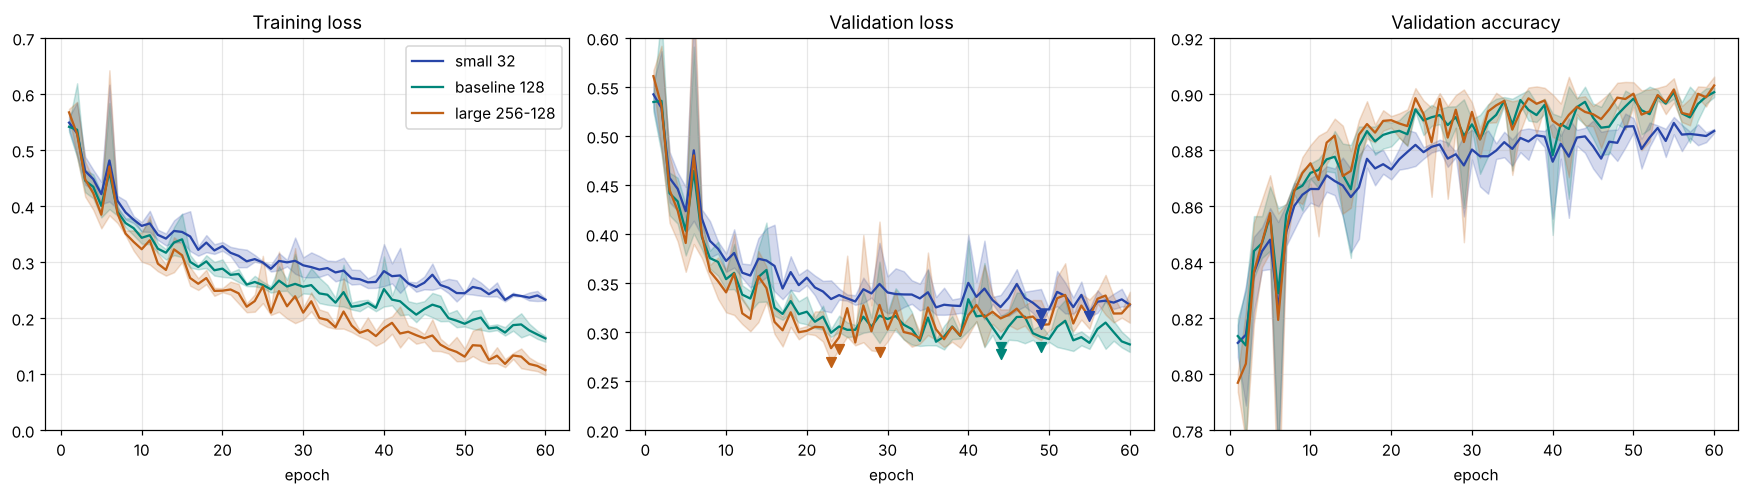

In [17]:
# ---------------- 2.2 Capacity: three architectures x three seeds, same training recipe -----------------
ARCH = {"small 32": [32], "baseline 128": [128], "large 256-128": [256, 128]}
for nm, h in ARCH.items(): run_config(nm, h, BASE_LR)
cap = summarise(list(ARCH), "architecture"); cap.to_csv(RES2 / "summary_capacity.csv", index=False)
print("Capacity: every value per seed, with mean and sample std (checkpoint = lowest validation loss; train acc taken at the same epoch)")
display(cap.style.format(FMT).hide(axis="index"))
register(list(ARCH), "P2-CAP", "2.2", "How does capacity change training fit and validation performance?", "Larger nets fit training data more; the large net over-fits.",
         "hidden layers", "lr 0.1, batch 128, SGD, 60 epochs, same data and seeds", cap, "architecture", "results/part2/summary_capacity.csv")
curves_figure(list(ARCH), list(ARCH), ["#2845A8", "#008579", "#C06016"], "fig6_capacity_curves", "2.2",
              "Learning curves for three capacities: mean over seeds 2208, 1, 2 (line) with min-max band; triangles mark each seed's lowest-validation-loss epoch.", [(0, 0.7), (0.2, 0.6), (0.78, 0.92)])

**Figure 6 (addresses 2.2).** Mean learning curves over the three seeds (band = min to max); triangles = lowest-validation-loss epochs. Training loss is plain cross-entropy for all networks.

**Interpretation.** Validation accuracy is 0.8920 (small, 25,450 parameters), 0.9013 (baseline, 101,770) and 0.9005 (large, 235,146), with sample std 0.001 to 0.002 over the three seeds; all exceed Part 1's best (LR, 0.8621). Going from 32 to 128 units gains 0.009, more than the seed spread; going on to 256 and 128 gains nothing. The small network's training loss had flattened (4.7% drop over the last 10 epochs) and its training accuracy is the lowest (0.9162): it is capacity-limited. The large network reaches its lowest validation loss early (epochs 23 to 29) and ends higher (0.278 to 0.328) while its training loss still falls (17.5% over the last 10 epochs): over-fitting without a gain in validation accuracy. Training loss was still falling for every network at epoch 60, but validation loss had already passed its minimum, so more epochs would not help generalisation. Epoch-to-epoch fluctuations are large (SGD), so best epochs are approximate, and training accuracy is taken at each run's own best epoch.

## 2.3 Experiment B: optimisation

**Variable: learning rate** (step size of the gradient update), chosen because it directly controls how far training gets within a fixed epoch budget. **Settings:** 0.01, **0.1 (baseline)**, 0.5. **Fixed:** baseline architecture, batch 128, 60 epochs, data, seeds, checkpoint rule. The lr = 0.1 runs are the baseline runs from 2.2 (same seeds). *Fairness caveat specific to this variable:* with a fixed number of epochs, a small learning rate may simply not have finished training, which is an optimisation failure, not a capacity limit.

Optimisation: every value per seed, with mean and sample std (checkpoint = lowest validation loss; train acc taken at the same epoch)


learning rate,parameters,best epoch (seeds 2208/1/2),val acc seeds 2208/1/2,val acc mean,val acc std,train acc mean,val loss at best (mean),val loss at epoch 60 (mean),"train loss drop, last 10 epochs"
lr 0.01,"101,770",60/59/60,0.8704 / 0.8717 / 0.8715,0.8712,0.0007,0.8739,0.371,0.372,4.2%
lr 0.1 (baseline),"101,770",49/44/44,0.9012 / 0.9026 / 0.9000,0.9013,0.0013,0.9313,0.282,0.287,13.7%
lr 0.5,"101,770",33/22/26,0.8926 / 0.8941 / 0.8963,0.8943,0.0019,0.9245,0.307,0.394,13.4%


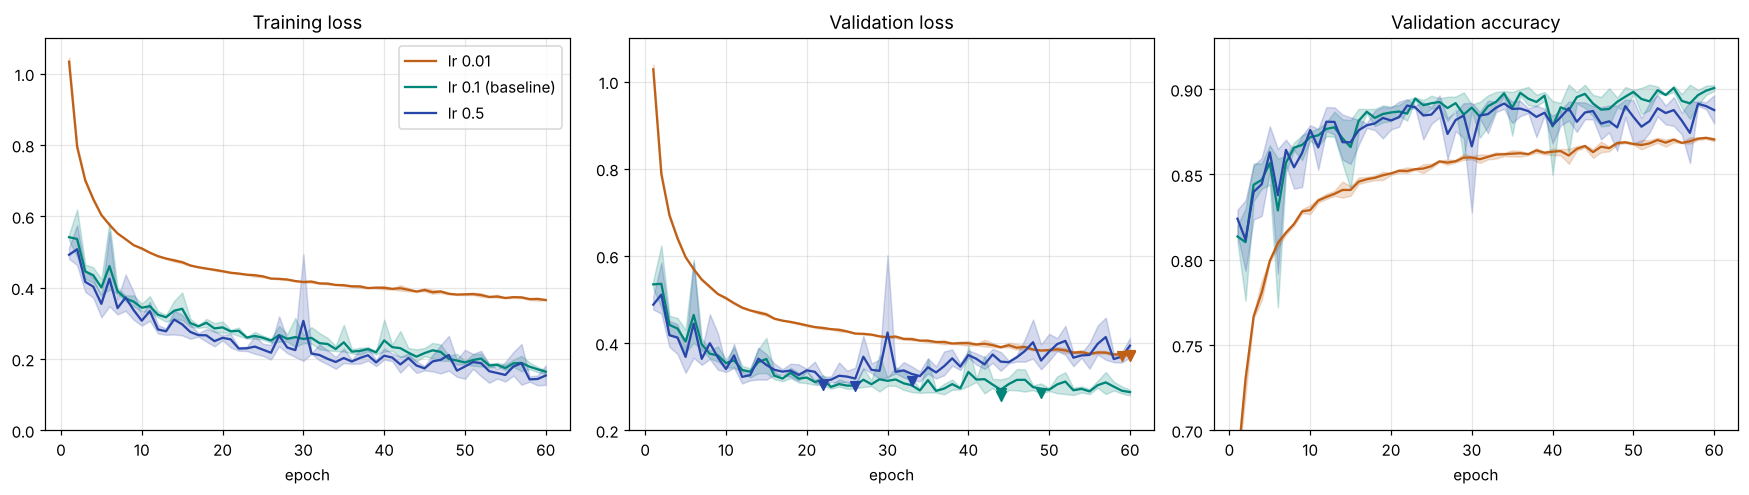

In [18]:
# ---------------- 2.3 Optimisation: learning rate 0.01 / 0.1 (baseline, reused) / 0.5, three seeds each -----------------
LRS = {"lr 0.01": 0.01, "lr 0.1 (baseline)": 0.1, "lr 0.5": 0.5}
run_config("lr 0.01", BASE_HIDDEN, 0.01); CFG["lr 0.1 (baseline)"] = CFG["baseline 128"]; run_config("lr 0.5", BASE_HIDDEN, 0.5)
opt = summarise(list(LRS), "learning rate"); opt.to_csv(RES2 / "summary_optimisation.csv", index=False)
print("Optimisation: every value per seed, with mean and sample std (checkpoint = lowest validation loss; train acc taken at the same epoch)")
display(opt.style.format(FMT).hide(axis="index"))
register(list(LRS), "P2-OPT", "2.3", "How does the learning rate change training dynamics and validation behaviour?", "0.01 is too slow for 60 epochs; 0.5 is faster but noisier.",
         "learning rate", "baseline architecture, batch 128, SGD, 60 epochs, same data and seeds", opt, "learning rate", "results/part2/summary_optimisation.csv")
curves_figure(list(LRS), list(LRS), ["#C06016", "#008579", "#2845A8"], "fig7_learning_rate_curves", "2.3",
              "Learning curves for three learning rates (baseline architecture): mean over seeds 2208, 1, 2 with min-max band; triangles mark each seed's lowest-validation-loss epoch.", [(0, 1.1), (0.2, 1.1), (0.7, 0.93)])
pd.concat([r["hist"].assign(config=r["name"], seed=r["seed"], hidden=str(r["hidden"]), lr=r["lr"]) for rs in CFG.values() for r in rs]).drop_duplicates(["config", "seed", "epoch"]).to_csv(RES2 / "learning_curves.csv", index=False)

**Figure 7 (addresses 2.3).** Mean learning curves over the three seeds for three learning rates; same layout as Figure 6.

**Interpretation.** Validation accuracy: 0.8712 (lr 0.01), 0.9013 (0.1) and 0.8943 (0.5); the seed std is at most 0.002, so these differences are larger than the seed spread. At 0.01 the validation loss was still falling at the last epoch (best epoch 59 to 60): training had not finished, so the 0.030 deficit is an optimisation shortfall of the same architecture, not a capacity limit; more epochs might close it (untested). At 0.5 training is faster (best epoch 22 to 33 against 44 to 49) but reaches a worse validation loss (0.307 against 0.282) and then degrades (0.394 at epoch 60), which is consistent with large steps overshooting the minimum (an interpretation, not tested). Caveat: with a fixed budget of 60 epochs the comparison favours rates that finish within it.

---
# Part 3: Regularisation and generalisation

*Which regularisation strategy narrows the gap between training and validation performance, and is the improvement larger than the seed-to-seed spread?*

**Main architecture: 784 → 256 → 128 → 10** (235,146 parameters), the network that over-fitted in 2.2 (validation loss rose after epoch about 25), so there is a generalisation gap to reduce. **Unregularised reference:** the Part 2 runs of this network (existing runs count, same seeds 2208, 1, 2). **Strategies, all taught in the lectures (slides 74-76):** (a) *weight decay* (L2): each step uses w ← w − lr·(gradient + λw), i.e. the loss plus (λ/2)·‖w‖²; as in the regression lab, biases are not decayed; (b) *early stopping*: keep the epoch with the lowest validation loss, which the checkpoint rule of Part 2 already does. **Comparable losses (R4):** every curve in this part is *plain* cross-entropy, evaluated without the penalty term, so a decayed network and an undecayed one are compared on the same quantity. **Fixed:** data, architecture, SGD with learning rate 0.1, batch 128, 60 epochs, seeds. **Selection:** λ is chosen on validation accuracy (mean over the three seeds); if several values are within 0.1 percentage points of the best, the largest λ (the simplest model) is kept, the same rule as Part 1.

## 3.1 Main comparison: unregularised vs weight decay, and early stopping

**Expectation.** A suitable λ shrinks the weights, lowers the late rise in validation loss and narrows the train-validation gap; validation accuracy may move less than validation loss, and by less than the seed spread. A too-large λ should under-fit. Weight decay with λ in {10⁻⁴, 10⁻³, 10⁻²} spans two orders of magnitude; λ = 0 is the reference.

Weight decay sweep: every value per seed, with mean and sample std (checkpoint = lowest validation loss; plain cross-entropy)


configuration,lambda,parameters,best epoch (seeds 2208/1/2),val acc seeds 2208/1/2,val acc mean,val acc std,train acc mean,val loss at best (mean),val loss at epoch 60 (mean),"train loss drop, last 10 epochs",val acc at epoch 60 (mean),train-val acc gap at best,weight norm at best (mean)
wd 0 (reference),0,"235,146",23/29/24,0.9021 / 0.9016 / 0.8977,0.9005,0.0024,0.9248,0.278,0.328,17.5%,0.9030,0.0243,20.4
wd 1e-4,0.0001,"235,146",23/39/53,0.9014 / 0.9033 / 0.9006,0.9018,0.0014,0.9378,0.278,0.306,18.9%,0.9001,0.0360,21.7
wd 1e-3,0.001,"235,146",42/59/58,0.9024 / 0.9008 / 0.9023,0.9018,0.0009,0.9261,0.275,0.292,4.8%,0.8926,0.0243,14.6
wd 1e-2,0.01,"235,146",55/32/53,0.8507 / 0.8521 / 0.8479,0.8502,0.0021,0.8482,0.433,0.472,0.5%,0.8327,-0.0021,6.7


Selected on validation: lambda* = 0.001 (wd 1e-3); candidates within 0.1 pp of the best: ['0.0001', '0.001']


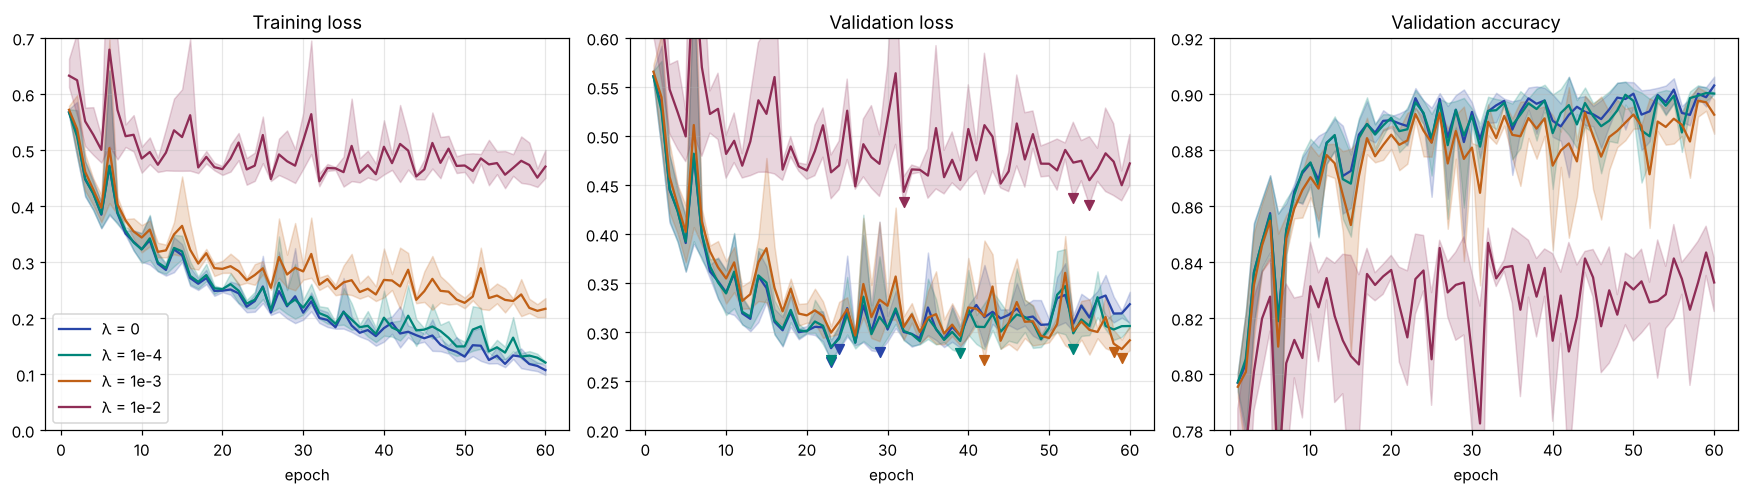

In [19]:
# ---------------- 3.1 weight decay sweep on the large network (three seeds each) -----------------
reset_register("P3-")
RES3 = ROOT / "results" / "part3"; RES3.mkdir(parents=True, exist_ok=True)
LARGE = [256, 128]
WD = {"wd 1e-4": 1e-4, "wd 1e-3": 1e-3, "wd 1e-2": 1e-2}
for nm, lam in WD.items(): run_config(nm, LARGE, BASE_LR, weight_decay=lam)
CFG["wd 0 (reference)"] = CFG["large 256-128"]                      # Part 2 runs, reused

def weight_norm(run): return float(sum((v ** 2).sum() for k, v in run["best_state"].items() if k.endswith("weight")).sqrt())   # L2 norm of all weight matrices at the checkpoint (biases excluded)
def summarise3(names, key):
    t = summarise(names, key)
    t["val acc at epoch 60 (mean)"] = [np.mean([r["hist"].val_acc.iloc[-1] for r in CFG[n]]) for n in names]
    t["train-val acc gap at best"] = t["train acc mean"] - t["val acc mean"]
    t["weight norm at best (mean)"] = [np.mean([weight_norm(r) for r in CFG[n]]) for n in names]
    return t
ORDER3 = ["wd 0 (reference)"] + list(WD)
sweep = summarise3(ORDER3, "configuration"); sweep.insert(1, "lambda", [0.0] + list(WD.values()))
sweep.to_csv(RES3 / "summary_weight_decay.csv", index=False)
FMT3 = {**FMT, "lambda": "{:g}", "val acc at epoch 60 (mean)": "{:.4f}", "train-val acc gap at best": "{:.4f}", "weight norm at best (mean)": "{:.1f}"}
print("Weight decay sweep: every value per seed, with mean and sample std (checkpoint = lowest validation loss; plain cross-entropy)")
display(sweep.style.format(FMT3).hide(axis="index"))

# validation-selected lambda (rule: highest mean validation accuracy among lambda > 0; within 0.1 pp of the best -> largest lambda)
cand = sweep[sweep["lambda"] > 0]; ok = cand[cand["val acc mean"] >= cand["val acc mean"].max() - 0.001]
LAM_STAR = float(ok["lambda"].max()); WD_STAR = [n for n, l in WD.items() if l == LAM_STAR][0]
print(f"Selected on validation: lambda* = {LAM_STAR:g} ({WD_STAR}); candidates within 0.1 pp of the best: {[f'{l:g}' for l in ok['lambda']]}")
for nm in ORDER3:
    log_experiment(id=f"P3-WD-{nm}", part_task="3.1", question="Does weight decay narrow the generalisation gap of the large MLP?", hypothesis="A moderate lambda lowers late validation loss; too large under-fits.",
        changed_variable="weight decay lambda", fixed_conditions="256-128 MLP, lr 0.1, batch 128, SGD, 60 epochs, same data and seeds", split="fit train 50k; validate 10k", seed="2208/1/2", configuration=nm,
        metric="validation accuracy at the lowest-validation-loss epoch (mean, sample std)", result=f"{sweep.set_index('configuration').loc[nm, 'val acc mean']:.4f} (std {sweep.set_index('configuration').loc[nm, 'val acc std']:.4f})",
        output_path="results/part3/summary_weight_decay.csv", notes="")
curves_figure(ORDER3, ["λ = 0", "λ = 1e-4", "λ = 1e-3", "λ = 1e-2"], ["#2845A8", "#008579", "#C06016", "#8F2D56"], "fig8_weight_decay_curves", "3.1",
              "Learning curves of the 256-128 MLP for four weight-decay values: plain cross-entropy (no penalty term), mean over seeds 2208, 1, 2 (line) with min-max band; triangles mark the lowest-validation-loss epochs.", [(0, 0.7), (0.2, 0.6), (0.78, 0.92)])

**Figure 8 (addresses 3.1).** Learning curves of the same network for four λ values; losses exclude the penalty term, so the panels are comparable.

**Interpretation.** Validation accuracy (mean of three seeds): 0.9005 (λ = 0), 0.9018 (1e-4), 0.9018 (1e-3) and 0.8502 (1e-2). The two middle values are within 0.1 percentage points, so the larger one, **λ\* = 1e-3**, is kept by the selection rule. λ = 1e-2 under-fits: training loss stays near 0.47 and accuracy near 0.85, so too strong a penalty is itself a failure. With λ\* the weight norm at the checkpoint falls from 20.4 to 14.6, training loss falls more slowly (4.8% over the last ten epochs against 17.5%) and the late validation loss is lower (0.292 against 0.329 at epoch 60). The accuracy gain of 0.0013 is smaller than the seed standard deviations (0.0024 and 0.0009).

In [20]:
# ---------------- 3.1 two strategies and their combination: weight decay x early stopping (same runs, no extra training) -----------------
def strat_row(label, names_cfg, final):
    runs = CFG[names_cfg]; pick = [r["hist"].iloc[-1] if final else r["hist"].iloc[r["best_epoch"] - 1] for r in runs]
    va = np.array([p.val_acc for p in pick]); ta = np.array([p.train_acc for p in pick])
    return {"strategy": label, "val acc seeds 2208/1/2": " / ".join(f"{v:.4f}" for v in va), "val acc mean": va.mean(), "val acc std": va.std(ddof=1),
            "val loss (mean)": np.mean([p.val_loss for p in pick]), "train-val acc gap": (ta - va).mean(), "stopping epoch (seeds)": "60/60/60" if final else "/".join(str(r["best_epoch"]) for r in runs)}
strat = pd.DataFrame([strat_row("none: stop at epoch 60", "wd 0 (reference)", True), strat_row("early stopping only (lowest val loss)", "wd 0 (reference)", False),
                      strat_row(f"weight decay λ*={LAM_STAR:g}: stop at epoch 60", WD_STAR, True), strat_row(f"weight decay λ*={LAM_STAR:g} + early stopping", WD_STAR, False)])
strat.to_csv(RES3 / "summary_strategies.csv", index=False)
print("Strategy comparison on the 256-128 network (validation; same runs as the sweep). Early stopping uses the validation loss to pick the epoch (allowed by R1).")
display(strat.style.format({"val acc mean": "{:.4f}", "val acc std": "{:.4f}", "val loss (mean)": "{:.3f}", "train-val acc gap": "{:.4f}"}).hide(axis="index"))
ref128 = summarise(["baseline 128"], "configuration").iloc[0]
print(f"Reference from Part 2 (validation-selected architecture): baseline 128 gives val acc {ref128['val acc mean']:.4f} (std {ref128['val acc std']:.4f}) and val loss {ref128['val loss at best (mean)']:.3f} at its best epoch.")
for i, r in strat.iterrows():
    log_experiment(id=f"P3-STRAT-{i+1}", part_task="3.1", question="How do weight decay and early stopping combine?", hypothesis="Each reduces the gap; early stopping mainly removes the late rise in validation loss.",
        changed_variable="weight decay on/off x early stopping on/off", fixed_conditions="256-128 MLP, lr 0.1, batch 128, 60 epochs, same data and seeds", split="fit train 50k; validate 10k", seed="2208/1/2",
        configuration=r["strategy"], metric="validation accuracy (mean, sample std)", result=f"{r['val acc mean']:.4f} (std {r['val acc std']:.4f})", output_path="results/part3/summary_strategies.csv", notes="")

Strategy comparison on the 256-128 network (validation; same runs as the sweep). Early stopping uses the validation loss to pick the epoch (allowed by R1).


strategy,val acc seeds 2208/1/2,val acc mean,val acc std,val loss (mean),train-val acc gap,stopping epoch (seeds)
none: stop at epoch 60,0.9062 / 0.9009 / 0.9020,0.9030,0.0028,0.328,0.0571,60/60/60
early stopping only (lowest val loss),0.9021 / 0.9016 / 0.8977,0.9005,0.0024,0.278,0.0243,23/29/24
weight decay λ*=0.001: stop at epoch 60,0.8858 / 0.8940 / 0.8980,0.8926,0.0062,0.292,0.0290,60/60/60
weight decay λ*=0.001 + early stopping,0.9024 / 0.9008 / 0.9023,0.9018,0.0009,0.275,0.0243,42/59/58


Reference from Part 2 (validation-selected architecture): baseline 128 gives val acc 0.9013 (std 0.0013) and val loss 0.282 at its best epoch.


**Interpretation.** Stopping at epoch 60, the unregularised network has the highest validation accuracy (0.9030) but also the largest train-validation gap (0.057) and validation loss (0.329). Early stopping lowers the loss to 0.278 and the gap to 0.024 but gives *lower* accuracy (0.9005); weight decay alone lowers the gap to 0.029 and the loss to 0.292 (accuracy 0.8926, std 0.0062); both together give 0.9018, loss 0.275, gap 0.024. Observation: both strategies narrow the gap and lower the validation loss; neither raises accuracy. Interpretation: late in training the network still classifies more images correctly while its probabilities become over-confident, so a rule based on validation *loss* trades a little accuracy for better-calibrated probabilities (stopping on accuracy was not tested). The regularised large network (0.9018) matches the smaller Part 2 baseline (0.9013, loss 0.282): within seed noise, controlling capacity by size or by penalty gave the same accuracy.

## 3.2 Randomness: the two main configurations over three seeds

**Main configurations:** λ = 0 (reference) and λ* (selected in 3.1), same architecture, same seeds 2208, 1, 2. **Every random source:** (1) weight initialisation (PyTorch default, `torch.manual_seed(seed)`); (2) mini-batch order (`torch.Generator` seeded with the same seed). There is no dropout, no data augmentation, and the train/validation split is fixed (saved indices), so none of these vary. Both configurations use the same seed, hence the same initial weights and the same batch order: differences between them are *paired*. The cell below also changes one source at a time for the reference network to see which matters more (a single extra run each, so only indicative).

Seed-level results for the two main configurations (validation)


seed,val acc λ=0,val acc λ*=0.001,paired difference,val loss λ=0,val loss λ*=0.001,"val loss at epoch 60, λ=0","val loss at epoch 60, λ*",best epoch λ=0,best epoch λ*
2208,0.9021,0.9024,0.0003,0.270,0.272,0.310,0.307,23,42
1,0.9016,0.9008,-0.0008,0.280,0.274,0.335,0.287,29,59
2,0.8977,0.9023,0.0046,0.283,0.280,0.341,0.282,24,58


mean val acc: λ=0 0.9005 (std 0.0024) | λ*=0.001 0.9018 (std 0.0009)
paired difference (λ* minus λ=0): mean +0.0014, sample std 0.0029, values [0.0003, -0.0008, 0.0046]  (3 seeds: a rough estimate, not proof)


varied random source,val acc,best epoch
both seed 2208 (existing run),0.9021,23
"init seed 1, batch order 2208",0.8980,23
"init seed 2208, batch order 1",0.9064,44
both seed 1 (existing run),0.9016,29


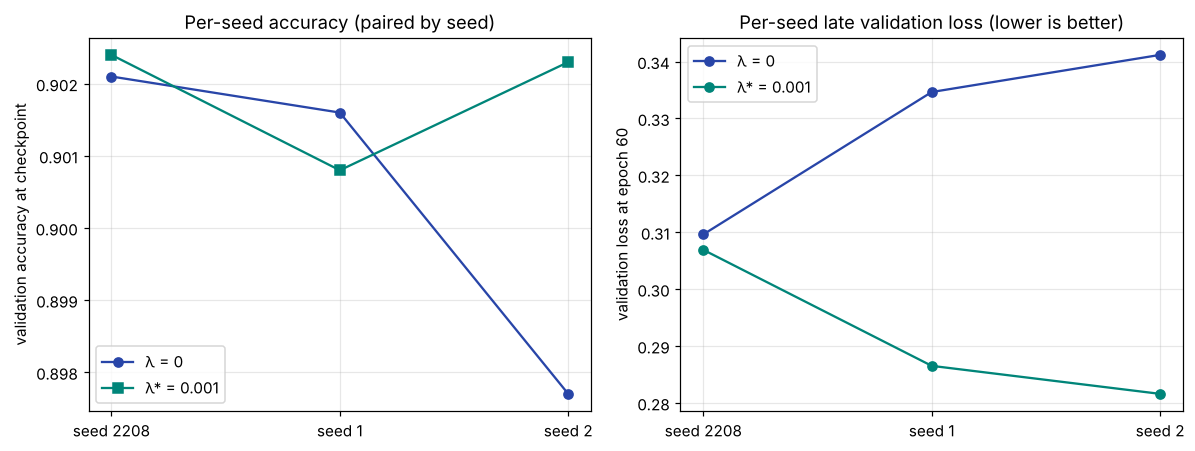

In [21]:
# ---------------- 3.2 seed-level comparison of the two main configurations, and the effect of each random source -----------------
A, B = CFG["wd 0 (reference)"], CFG[WD_STAR]
def at_best(r): return r["hist"].iloc[r["best_epoch"] - 1]
seed_tab = pd.DataFrame([{"seed": a["seed"], "val acc λ=0": at_best(a).val_acc, f"val acc λ*={LAM_STAR:g}": at_best(b).val_acc, "paired difference": at_best(b).val_acc - at_best(a).val_acc,
                          "val loss λ=0": at_best(a).val_loss, f"val loss λ*={LAM_STAR:g}": at_best(b).val_loss, "val loss at epoch 60, λ=0": a["hist"].val_loss.iloc[-1], "val loss at epoch 60, λ*": b["hist"].val_loss.iloc[-1],
                          "best epoch λ=0": a["best_epoch"], "best epoch λ*": b["best_epoch"]} for a, b in zip(A, B)])
seed_tab.to_csv(RES3 / "seed_level_main_configs.csv", index=False)
d = seed_tab["paired difference"].to_numpy()
print("Seed-level results for the two main configurations (validation)")
display(seed_tab.style.format({c: "{:.4f}" for c in seed_tab.columns if c.startswith(("val", "paired")) and "epoch" not in c} | {"val loss at epoch 60, λ=0": "{:.3f}", "val loss at epoch 60, λ*": "{:.3f}", "val loss λ=0": "{:.3f}", f"val loss λ*={LAM_STAR:g}": "{:.3f}"}).hide(axis="index"))
print(f"mean val acc: λ=0 {seed_tab['val acc λ=0'].mean():.4f} (std {seed_tab['val acc λ=0'].std(ddof=1):.4f}) | λ*={LAM_STAR:g} {seed_tab[f'val acc λ*={LAM_STAR:g}'].mean():.4f} (std {seed_tab[f'val acc λ*={LAM_STAR:g}'].std(ddof=1):.4f})")
print(f"paired difference (λ* minus λ=0): mean {d.mean():+.4f}, sample std {d.std(ddof=1):.4f}, values {np.round(d, 4).tolist()}  (3 seeds: a rough estimate, not proof)")

# one random source at a time on the reference network: (init seed, batch-order seed)
src = [("both seed 2208 (existing run)", at_best(A[0]).val_acc, A[0]["best_epoch"])]
for lab, (si, so) in {"init seed 1, batch order 2208": (1, SEED), "init seed 2208, batch order 1": (SEED, 1)}.items():
    r = train_mlp(LARGE, BASE_LR, si, order_seed=so); TIMES.append({"what": f"train MLP large, {lab}", "seconds": r["seconds"]}); src.append((lab, at_best(r).val_acc, r["best_epoch"]))
src.append(("both seed 1 (existing run)", at_best(A[1]).val_acc, A[1]["best_epoch"]))
srctab = pd.DataFrame(src, columns=["varied random source", "val acc", "best epoch"]); srctab.to_csv(RES3 / "random_sources.csv", index=False)
display(srctab.style.format({"val acc": "{:.4f}"}).hide(axis="index"))
for _, r in seed_tab.iterrows():
    log_experiment(id=f"P3-SEED-{int(r['seed'])}", part_task="3.2", question="Is the weight-decay effect larger than the seed spread?", hypothesis="The paired difference is small relative to seed noise for accuracy.",
        changed_variable="seed (paired for both configs)", fixed_conditions="256-128 MLP, lr 0.1, batch 128, 60 epochs, lambda 0 vs lambda*", split="fit train 50k; validate 10k", seed=int(r["seed"]),
        configuration=f"lambda 0 vs {LAM_STAR:g}", metric="paired difference in validation accuracy", result=f"{r['paired difference']:+.4f}", output_path="results/part3/seed_level_main_configs.csv", notes="")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2)); xs = np.arange(len(SEEDS))
ax[0].plot(xs, seed_tab["val acc λ=0"], "o-", color="#2845A8", label="λ = 0"); ax[0].plot(xs, seed_tab[f"val acc λ*={LAM_STAR:g}"], "s-", color="#008579", label=f"λ* = {LAM_STAR:g}")
ax[0].set_xticks(xs, [f"seed {s}" for s in SEEDS]); ax[0].set_ylabel("validation accuracy at checkpoint"); ax[0].set_title("Per-seed accuracy (paired by seed)"); ax[0].legend(); ax[0].grid(alpha=.3)
for lab, col, c in [("λ = 0", "val loss at epoch 60, λ=0", "#2845A8"), (f"λ* = {LAM_STAR:g}", "val loss at epoch 60, λ*", "#008579")]: ax[1].plot(xs, seed_tab[col], "o-", color=c, label=lab)
ax[1].set_xticks(xs, [f"seed {s}" for s in SEEDS]); ax[1].set_ylabel("validation loss at epoch 60"); ax[1].set_title("Per-seed late validation loss (lower is better)"); ax[1].legend(); ax[1].grid(alpha=.3)
fig.tight_layout(); save_fig(fig, "fig9_seed_level_main_configs", "3.2", "Seed-level comparison of the two main configurations: validation accuracy at the checkpoint and validation loss at epoch 60, per seed."); plt.show()

**Figure 9 (addresses 3.2).** The two main configurations, seed by seed.

**Interpretation.** Per seed, accuracy is 0.9021 / 0.9016 / 0.8977 for λ = 0 (mean 0.9005, std 0.0024) and 0.9024 / 0.9008 / 0.9023 for λ\* (mean 0.9018, std 0.0009). The paired differences are +0.0003, −0.0008 and +0.0046 (mean +0.0014, sample std 0.0029): the accuracy effect is inside the seed spread, so with three seeds it is not established. The late validation loss is lower with λ\* for all three seeds (0.310 → 0.307, 0.335 → 0.287, 0.341 → 0.282), a consistent direction of unequal size. Changing one random source at a time moved the accuracy of the seed-2208 run (0.9021) by −0.0041 (initialisation) and +0.0043 (batch order), as large as the three-seed spread: both sources matter and, from one run each, they cannot be ranked. The seeds do not vary the train/validation split, so this spread excludes split-to-split variation.

---
# Part 4: Clustering without labels

*What structure does K-means find in raw pixels, and does it match the ten classes?*

**Data (fixed, saved indices).** The 3,000-image stratified training subset `cluster_train_idx` (300 per class) is clustered; the 1,000-image subset `cluster_val_idx` (taken from the validation images) is used only to evaluate centroids on unseen images. The official-test clustering subset stays sealed. **Features:** raw pixels in [0, 1] (784 values); no fitted scaling is needed because all pixels share one unit and range (K-means is scale-sensitive, slides 27-28). **Algorithm (slides 14-23):** K-means minimising J = Σᵢ ‖zᵢ − μ_cᵢ‖², scikit-learn Lloyd's algorithm (assign each point to the nearest centre, then move each centre to the mean of its points), random initial centres as in the slides, 300 iterations at most. K-means reaches a local minimum only, so each fit is the best (lowest J) of 10 random starts. **Labels are not used until 4.2.**

In [22]:
# ---------------- Part 4 data and the reusable clustering protocol (reused by Part 5.1 on learned features) -----------------
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.stats import spearmanr
reset_register("P4-")
RES4 = ROOT / "results" / "part4"; RES4.mkdir(parents=True, exist_ok=True)
Xc, yc = prep(X_off[IDX["cluster_train_idx"]]), y_off[IDX["cluster_train_idx"]]      # 3,000 training images (labels held back until 4.2)
Xcv, ycv = prep(X_off[IDX["cluster_val_idx"]]), y_off[IDX["cluster_val_idx"]]        # 1,000 validation images
assert Xc.shape == (3000, 784) and Xcv.shape == (1000, 784) and (np.bincount(yc) == 300).all() and (np.bincount(ycv) == 100).all()
KS = [2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 20, 24, 30]; N_INIT = 10

def km_fit(Z, K, seed, n_init=N_INIT, init="random"):
    return KMeans(K, init=init, n_init=n_init, random_state=seed, algorithm="lloyd", max_iter=300).fit(Z)
def sq_dist_to_centres(km, Z): return float((km.transform(Z).min(1) ** 2).sum())      # J of unseen images against fixed centroids
def pair_ari(label_list): return float(np.mean([adjusted_rand_score(a, b) for i, a in enumerate(label_list) for b in label_list[i + 1:]]))

def kmeans_sweep(Ztr, Zva, tag):
    """Unlabelled evidence for K and initialisation stability: for each K, three seeds, each the best of 10 random starts."""
    rows, fits = [], {}
    for K in KS:
        t0 = time.perf_counter(); runs = [km_fit(Ztr, K, s) for s in SEEDS]; TIMES.append({"what": f"kmeans {tag} K={K} (3 seeds x {N_INIT} starts)", "seconds": time.perf_counter() - t0})
        for s, km in zip(SEEDS, runs): fits[(K, s)] = km
        J = np.array([km.inertia_ for km in runs]); Jv = np.array([sq_dist_to_centres(km, Zva) for km in runs])
        rows.append({"K": K, "J train (mean)": J.mean(), "J train per image": J.mean() / len(Ztr), "J val per image": Jv.mean() / len(Zva),
                     "BIC-style cost": J.mean() + 0.5 * K * Ztr.shape[1] * np.log(len(Ztr)), "J spread over seeds (max-min)/mean": (J.max() - J.min()) / J.mean(),
                     "ARI between seeds (mean of 3 pairs)": pair_ari([km.labels_ for km in runs])})
    t = pd.DataFrame(rows)
    x = (t.K - t.K.min()) / (t.K.max() - t.K.min()); y = (t["J train (mean)"] - t["J train (mean)"].min()) / (t["J train (mean)"].max() - t["J train (mean)"].min())
    t["elbow distance"] = (1 - x - y) / np.sqrt(2)                            # distance below the chord joining the first and last point of the normalised J(K) curve
    return t, fits

def restart_stability(Z, K, init, n=10):
    """Single random starts (n_init=1): how much do J and the partition change with the initial centres?"""
    seeds = [SEED] + list(range(1, n)); runs = [km_fit(Z, K, s, n_init=1, init=init) for s in seeds]
    J = np.array([km.inertia_ for km in runs])
    return {"K": K, "init": init, "starts": n, "J min": J.min(), "J mean": J.mean(), "J max": J.max(), "(max-min)/mean": (J.max() - J.min()) / J.mean(), "ARI between starts (mean of 45 pairs)": pair_ari([km.labels_ for km in runs])}

def heldout_scores(km, y_tr, Zv, yv):
    """Fixed centroids, unseen images: each cluster is mapped to the majority class of its TRAINING images (no refit)."""
    maj = pd.crosstab(km.labels_, y_tr).idxmax(axis=1); lv = km.predict(Zv)
    return {"purity": float((yv == maj.loc[lv].to_numpy()).mean()), "ARI": adjusted_rand_score(yv, lv), "NMI": normalized_mutual_info_score(yv, lv)}
def cluster_scores(labels, y):
    ct = pd.crosstab(labels, y); return {"purity": ct.max(axis=1).sum() / ct.values.sum(), "ARI": adjusted_rand_score(y, labels), "NMI": normalized_mutual_info_score(y, labels)}
print("Protocol ready: K in", KS, "| seeds", SEEDS, "| best of", N_INIT, "random starts per fit | J = sum of squared distances to the assigned centre")

Protocol ready: K in [2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 20, 24, 30] | seeds [2208, 1, 2] | best of 10 random starts per fit | J = sum of squared distances to the assigned centre


## 4.1 Choosing K without labels, and stability

**Evidence (slides 36-38), all computed without labels.** (1) *Elbow:* J on the training subset against K; the rule fixed here is the K farthest below the chord joining the first and last points of the normalised curve. (2) *Held-out check (the cross-validation idea):* per-image J of the 1,000 unseen validation images against the training centroids. (3) *BIC-style cost,* J + (p/2)·log N with p = K·784 centre coordinates, as on slide 38 (a rough guide here: the penalty ignores the noise scale of the pixels). (4) *Stability:* the three seeds (each best of 10 starts) are compared by their J and by the adjusted Rand index (ARI; 1 = identical partitions, ~0 = chance). K ranges well below and above 10. **Decision rule, fixed before any label is used: K_sel = the elbow K.** K = 10 is analysed too, as the reference for the ten classes.

Unlabelled evidence for K (three seeds, each the best of 10 starts)


K,J train (mean),J train per image,J val per image,BIC-style cost,J spread over seeds (max-min)/mean,ARI between seeds (mean of 3 pairs),elbow distance
2,"161,725",53.91,53.65,"168,002",0.0000,0.990,0.000
3,"138,971",46.32,46.07,"148,386",0.0000,1.000,0.158
4,"125,631",41.88,41.73,"138,185",0.0000,0.997,0.240
5,"117,950",39.32,39.33,"133,642",0.0000,0.992,0.276
6,"110,305",36.77,36.66,"129,136",0.0000,0.985,0.313
8,"101,027",33.68,34.04,"126,135",0.0001,0.962,0.337
10,"95,728",31.91,31.99,"127,113",0.0049,0.831,0.329
12,"90,900",30.30,30.30,"128,562",0.0050,0.725,0.317
14,"87,118",29.04,29.02,"131,057",0.0045,0.789,0.297
16,"84,404",28.13,28.09,"134,620",0.0012,0.786,0.269


Elbow rule picks K = 8; the BIC-style cost is lowest at K = 8. K_sel = 8 (fixed rule). K = 10 is kept as the reference for the ten classes.


Stability to initialisation: ten single starts per row (no restarts), random initial centres as in the slides vs k-means++ seeding


K,init,starts,J min,J mean,J max,(max-min)/mean,ARI between starts (mean of 45 pairs)
8,random,10,"101,024","101,971","105,373",0.0426,0.755
8,k-means++,10,"101,024","101,841","105,889",0.0478,0.773
10,random,10,"95,847","96,629","97,609",0.0182,0.646
10,k-means++,10,"95,768","96,174","96,648",0.0091,0.702


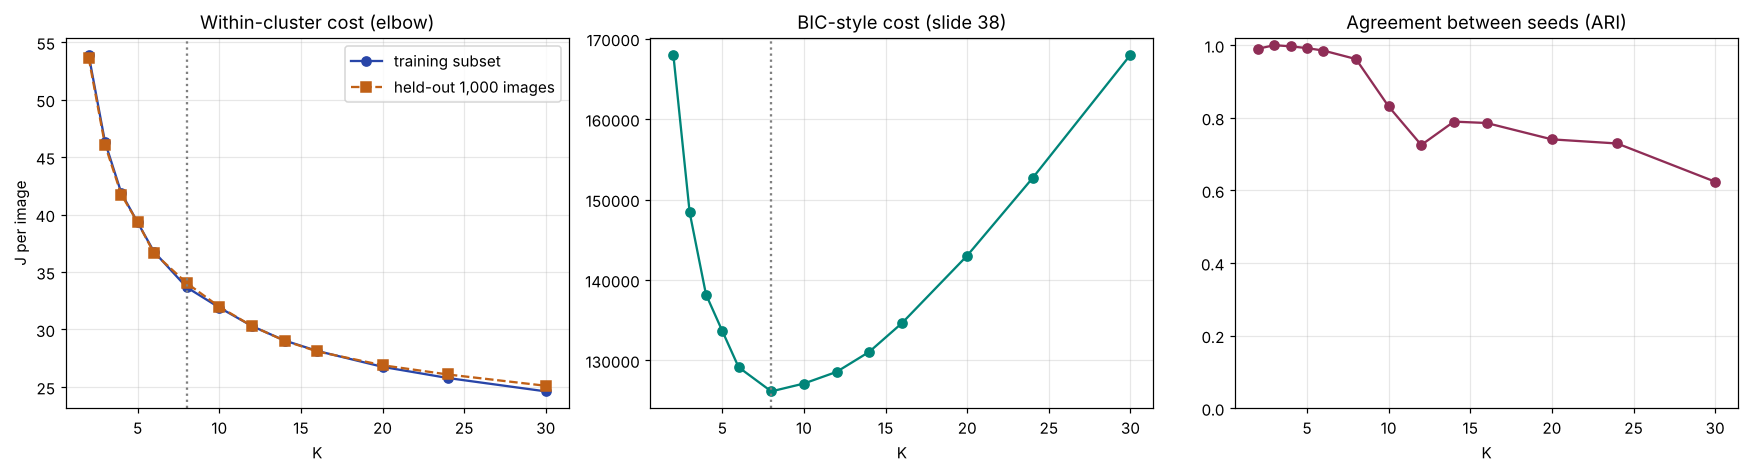

In [23]:
# ---------------- 4.1 K selection and initialisation stability on raw pixels (no labels used) -----------------
ksel, FITS_RAW = kmeans_sweep(Xc, Xcv, "raw pixels"); ksel.to_csv(RES4 / "k_selection_raw.csv", index=False)
K_ELBOW = int(ksel.loc[ksel["elbow distance"].idxmax(), "K"]); K_BIC = int(ksel.loc[ksel["BIC-style cost"].idxmin(), "K"]); K_SEL = K_ELBOW
print("Unlabelled evidence for K (three seeds, each the best of 10 starts)")
display(ksel.style.format({"J train (mean)": "{:,.0f}", "J train per image": "{:.2f}", "J val per image": "{:.2f}", "BIC-style cost": "{:,.0f}", "J spread over seeds (max-min)/mean": "{:.4f}",
                           "ARI between seeds (mean of 3 pairs)": "{:.3f}", "elbow distance": "{:.3f}"}).hide(axis="index"))
print(f"Elbow rule picks K = {K_ELBOW}; the BIC-style cost is lowest at K = {K_BIC}. K_sel = {K_SEL} (fixed rule). K = 10 is kept as the reference for the ten classes.")

stab = pd.DataFrame([restart_stability(Xc, K, init) for K in sorted({K_SEL, 10}) for init in ["random", "k-means++"]]); stab.to_csv(RES4 / "restart_stability_raw.csv", index=False)
print("Stability to initialisation: ten single starts per row (no restarts), random initial centres as in the slides vs k-means++ seeding")
display(stab.style.format({"J min": "{:,.0f}", "J mean": "{:,.0f}", "J max": "{:,.0f}", "(max-min)/mean": "{:.4f}", "ARI between starts (mean of 45 pairs)": "{:.3f}"}).hide(axis="index"))
for _, r in ksel.iterrows():
    log_experiment(id=f"P4-K-{int(r['K'])}", part_task="4.1", question="Which K do unlabelled criteria suggest, and how stable is the clustering?", hypothesis="J falls smoothly with K; the elbow is not at 10 and several K are almost equally good.",
        changed_variable="K", fixed_conditions="raw pixels, 3,000 train subset, random init, best of 10 starts, J = sum of squared distances", split="cluster_train_idx (fit), cluster_val_idx (held-out J)", seed="2208/1/2", configuration=f"K={int(r['K'])}",
        metric="J per image (train, mean over seeds)", result=f"{r['J train per image']:.2f} (val {r['J val per image']:.2f}, seed ARI {r['ARI between seeds (mean of 3 pairs)']:.3f})", output_path="results/part4/k_selection_raw.csv", notes="")
for _, r in stab.iterrows():
    log_experiment(id=f"P4-STAB-K{int(r['K'])}-{r['init']}", part_task="4.1", question="How much does one random start change J and the partition?", hypothesis="Single starts reach different local minima; restarts reduce the spread.",
        changed_variable="initialisation (random vs k-means++)", fixed_conditions="raw pixels, 3,000 train subset, 10 single starts, 300 iterations", split="cluster_train_idx", seed="2208, 1..9", configuration=f"K={int(r['K'])}, {r['init']}",
        metric="relative J spread; mean pairwise ARI", result=f"{r['(max-min)/mean']:.4f}; {r['ARI between starts (mean of 45 pairs)']:.3f}", output_path="results/part4/restart_stability_raw.csv", notes="")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].plot(ksel.K, ksel["J train per image"], "o-", color="#2845A8", label="training subset"); ax[0].plot(ksel.K, ksel["J val per image"], "s--", color="#C06016", label="held-out 1,000 images")
ax[0].axvline(K_SEL, color="grey", ls=":"); ax[0].set_xlabel("K"); ax[0].set_ylabel("J per image"); ax[0].set_title("Within-cluster cost (elbow)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ksel.K, ksel["BIC-style cost"], "o-", color="#008579"); ax[1].axvline(K_BIC, color="grey", ls=":"); ax[1].set_xlabel("K"); ax[1].set_title("BIC-style cost (slide 38)"); ax[1].grid(alpha=.3)
ax[2].plot(ksel.K, ksel["ARI between seeds (mean of 3 pairs)"], "o-", color="#8F2D56"); ax[2].set_xlabel("K"); ax[2].set_ylim(0, 1.02); ax[2].set_title("Agreement between seeds (ARI)"); ax[2].grid(alpha=.3)
fig.tight_layout(); save_fig(fig, "fig10_k_selection", "4.1", "Unlabelled evidence for K on raw pixels: per-image J (training and held-out images), BIC-style cost, and ARI between three seeds."); plt.show()

**Figure 10 (addresses 4.1).** Elbow and held-out J (left), BIC-style cost (middle), agreement between seeds (right).

**Interpretation.** J per image falls smoothly from 53.9 (K = 2) to 24.6 (K = 30) with no sharp break. The elbow rule gives **K_sel = 8** and the BIC-style cost is also lowest at K = 8, but the elbow is shallow (distance 0.337 against 0.329 at K = 10), so K = 10 is almost as good. Held-out J tracks training J (34.04 against 33.68 at K = 8; 25.10 against 24.61 at K = 30): no sign of over-fitted centres with 3,000 images, but it keeps falling with K and cannot choose K alone. Seeds agree up to K = 8 (ARI 0.96; at least 0.99 for K ≤ 5) and then diverge (0.83 at K = 10, 0.62 at K = 30): for larger K several partitions are about equally good. A single random start changes J by up to 4.3% at K = 8 (ARI 0.75) and 1.8% at K = 10 (ARI 0.65); k-means++ does not help consistently (4.8% and 0.9%). The best of ten starts cuts the spread over seeds to under 0.6%, as the slides advise. No criterion identifies a true K; K = 8 is a defensible summary, not a fact.

## 4.2 Interpreting the clusters with labels, and 4.3 link to Part 1

**Protocol is now fixed** (raw pixels, K_sel and K = 10, seed 2208, best of 10 starts), so labels are used only to describe the clusters. K-means assumes roughly spherical, similarly sized, well-separated groups in Euclidean pixel distance (slide 29); nothing guarantees that the ten *classes* are such groups, so a class may be split over several clusters and several classes may share one. The scores below measure agreement with the labels: purity (share of images in the majority class of their cluster), ARI and normalised mutual information (NMI).

Agreement with the class labels (descriptive; seed 2208): the 3,000 clustered images, and 1,000 unseen validation images assigned to the fixed centroids (clusters mapped to their training majority class)


K,purity,ARI,NMI,held-out purity,held-out ARI,held-out NMI
8,0.532,0.356,0.491,0.527,0.348,0.499
10,0.551,0.339,0.504,0.555,0.345,0.529


Cluster composition at K = 8 (rows = clusters, columns = classes, counts of the 3,000 images)


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
0,34,6,25,24,21,201,33,34,22,8
1,0,0,0,0,0,33,0,17,2,261
2,174,12,10,91,42,0,58,0,2,0
3,13,271,1,155,8,0,4,0,1,1
4,10,2,172,3,167,0,94,0,18,0
5,3,0,2,0,0,0,2,0,160,1
6,1,0,0,0,0,62,0,249,21,21
7,65,9,90,27,62,4,109,0,74,8


Cluster composition at K = 10 (rows = clusters, columns = classes, counts of the 3,000 images)


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
0,10,2,170,3,166,0,93,0,18,0
1,4,0,1,0,1,0,2,0,116,0
2,71,9,92,25,63,3,108,0,4,4
3,170,12,10,90,43,0,58,0,1,0
4,0,0,0,0,0,56,0,225,9,8
5,0,0,0,0,0,22,0,2,0,161
6,14,271,1,158,8,0,3,0,1,1
7,30,6,24,24,19,198,33,32,28,7
8,1,0,2,0,0,0,3,0,116,1


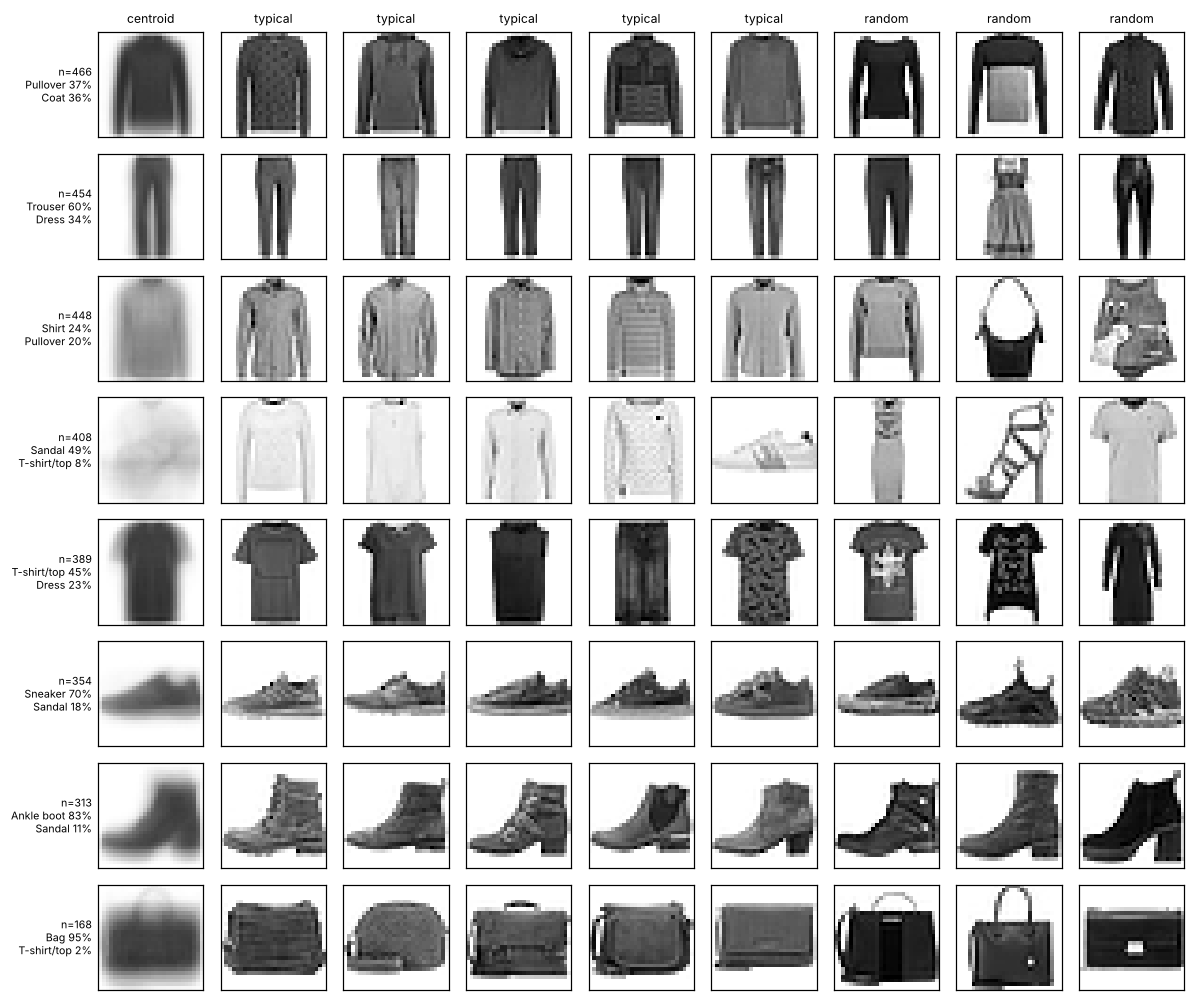

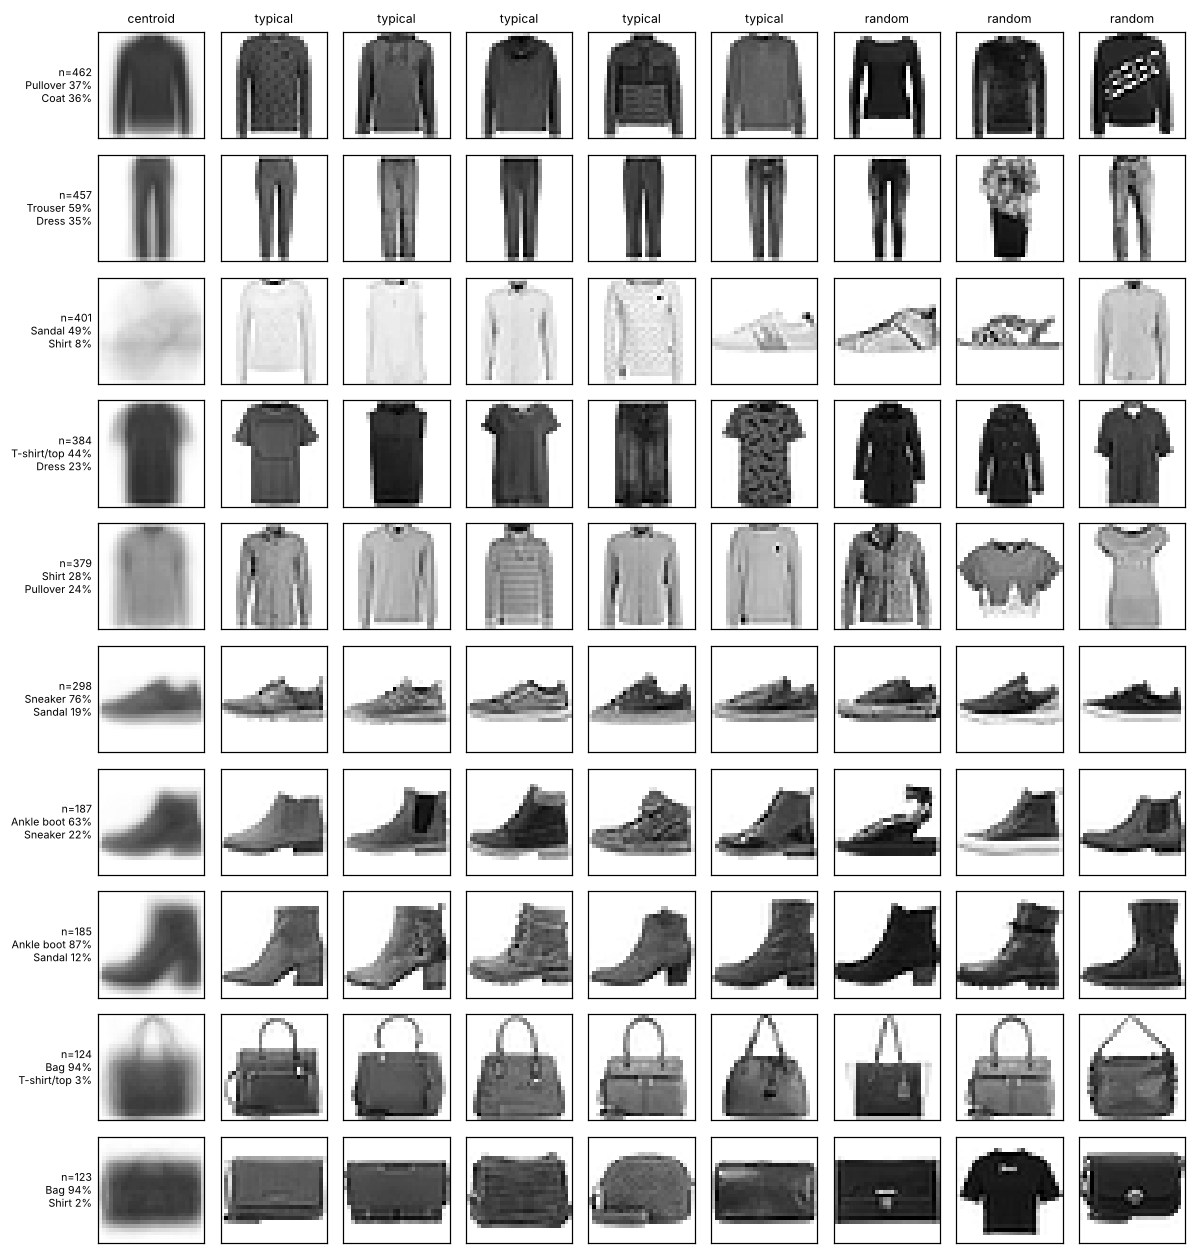

In [24]:
# ---------------- 4.2 cluster composition, example images, agreement with labels (labels used only now, protocol fixed) -----------------
def composition(km, y): return pd.crosstab(pd.Series(km.labels_, name="cluster"), pd.Series(y, name="class")).rename(columns=dict(enumerate(CLASS_NAMES)))
KM = {K: FITS_RAW[(K, SEED)] for K in sorted({K_SEL, 10})}
scores = pd.DataFrame([{"K": K, **cluster_scores(KM[K].labels_, yc), **{f"held-out {k}": v for k, v in heldout_scores(KM[K], yc, Xcv, ycv).items()}} for K in KM]); scores.to_csv(RES4 / "cluster_scores_raw.csv", index=False)
print("Agreement with the class labels (descriptive; seed 2208): the 3,000 clustered images, and 1,000 unseen validation images assigned to the fixed centroids (clusters mapped to their training majority class)")
display(scores.style.format({c: "{:.3f}" for c in scores.columns if c != "K"}).hide(axis="index"))
for K in KM:
    comp = composition(KM[K], yc); comp.to_csv(RES4 / f"composition_raw_K{K}.csv"); print(f"Cluster composition at K = {K} (rows = clusters, columns = classes, counts of the 3,000 images)"); display(comp)
for K in KM:
    log_experiment(id=f"P4-INTERP-K{K}", part_task="4.2", question="Do K-means clusters of raw pixels match the ten classes?", hypothesis="Footwear, trousers and bags separate; upper-body garments mix.",
        changed_variable="none (protocol fixed)", fixed_conditions="raw pixels, seed 2208, best of 10 starts", split="cluster_train_idx", seed=SEED, configuration=f"K={K}", metric="purity / ARI / NMI vs labels",
        result="{:.3f} / {:.3f} / {:.3f} (held-out {:.3f} / {:.3f} / {:.3f})".format(*scores.set_index('K').loc[K, ['purity', 'ARI', 'NMI', 'held-out purity', 'held-out ARI', 'held-out NMI']]), output_path="results/part4/cluster_scores_raw.csv", notes="labels used for description only")

# example images per cluster: centroid, 5 members nearest to the centroid (typical), 3 random members
def example_figure(Kfig, fname, caption):
    km = KM[Kfig]; rng = np.random.default_rng(SEED); order = np.argsort(-np.bincount(km.labels_)); compK = composition(km, yc)
    fig, axs = plt.subplots(Kfig, 9, figsize=(11, 1.15 * Kfig))
    for r_i, k in enumerate(order):
        mem = np.where(km.labels_ == k)[0]; dist = np.linalg.norm(Xc[mem] - km.cluster_centers_[k], axis=1); near_ = mem[np.argsort(dist)[:5]]; rand_ = rng.choice(mem, 3, replace=False)
        imgs = [km.cluster_centers_[k]] + [Xc[i] for i in near_] + [Xc[i] for i in rand_]
        for c_i, im in enumerate(imgs): axs[r_i, c_i].imshow(im.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); axs[r_i, c_i].set_xticks([]); axs[r_i, c_i].set_yticks([])
        top = compK.loc[k].sort_values(ascending=False)[:2]; axs[r_i, 0].set_ylabel(f"n={len(mem)}\n{top.index[0]} {top.iloc[0]/len(mem):.0%}\n{top.index[1]} {top.iloc[1]/len(mem):.0%}", rotation=0, ha="right", va="center", fontsize=7)
    for c_i, t in enumerate(["centroid"] + ["typical"] * 5 + ["random"] * 3): axs[0, c_i].set_title(t, fontsize=8)
    fig.tight_layout(); save_fig(fig, fname, "4.2", caption); plt.show()
example_figure(K_SEL, f"fig11_cluster_examples_K{K_SEL}", f"K = {K_SEL} (selected) clusters of raw pixels, seed 2208: centroid, the five members nearest to the centroid, and three random members; row labels give cluster size and the two most frequent classes.")
example_figure(10, "fig11b_cluster_examples_K10", "K = 10 clusters of raw pixels, seed 2208: centroid, the five members nearest to the centroid, and three random members; row labels give cluster size and the two most frequent classes.")

**Figures 11 and 11b (address 4.2).** Centroid, typical and random members of each cluster, for the selected K and for K = 10.

**Interpretation.** Agreement with the labels is partial: purity 0.532 / ARI 0.356 / NMI 0.491 at K = 8 and 0.551 / 0.339 / 0.504 at K = 10. The 1,000 unseen validation images assigned to the fixed centres give similar values (0.527 / 0.348 / 0.499 and 0.555 / 0.346 / 0.529), so the structure is not specific to the 3,000 clustered images. In the K = 10 clusters (Figure 11b) footwear and bags are recovered well (Sneaker 76%, Ankle boot 87% and 63%, Bag 94% twice; in the examples shown one bag cluster holds bags with handles and the other wide clutches), and trousers share a cluster with dresses (Trouser 59%, Dress 35%). Upper-body garments mix: one cluster is 37% Pullover and 36% Coat, and Shirt, although the most frequent class in one cluster, is only 28.5% of it and never a majority. One cluster (n = 401) is bright rather than class-specific: 49% Sandal, with white tops and light sneakers. Interpretation: in raw-pixel Euclidean distance, brightness, area and silhouette matter more than the class, so the ten classes are not ten natural clusters; a class can be split over clusters (Bag) and classes can share one (Pullover, Coat). The unequal cluster sizes (123 to 462) are consistent with the K-means assumptions (slide 29) not holding here, but do not prove it.

### 4.3 Connection to Part 1

If K-means groups images that look alike in pixel space, the class pairs that share clusters should be the pairs the supervised models of Part 1 confuse. Two quantities are compared over all 45 class pairs: the *cluster overlap* of a pair, Σₖ min(share of class i in cluster k, share of class j in cluster k) (0 = never share a cluster, 1 = identical distribution over clusters), and the *Part 1 confusion rate* of the pair, (errors i→j plus j→i) divided by the two class sizes, from the validation predictions of the selected logistic regression (10,000 images, not the 3,000 clustered ones).

K = 8: class pairs with the highest cluster overlap, and how Part 1 ranks the same pairs


class pair,cluster overlap,Part 1 LR confusion rate,rank by LR confusion (of 45)
Pullover / Coat,0.870,0.104,2
Coat / Shirt,0.743,0.093,4
Pullover / Shirt,0.740,0.094,3
Trouser / Dress,0.613,0.015,12
T-shirt/top / Shirt,0.573,0.115,1
T-shirt/top / Dress,0.527,0.043,5


K = 10: class pairs with the highest cluster overlap, and how Part 1 ranks the same pairs


class pair,cluster overlap,Part 1 LR confusion rate,rank by LR confusion (of 45)
Pullover / Coat,0.867,0.104,2
Pullover / Shirt,0.743,0.094,3
Coat / Shirt,0.740,0.093,4
Trouser / Dress,0.623,0.015,12
T-shirt/top / Shirt,0.583,0.115,1
T-shirt/top / Dress,0.520,0.043,5


K,Spearman rho (45 class pairs),p-value
8,0.85,1.3e-13
10,0.85,9.9e-14


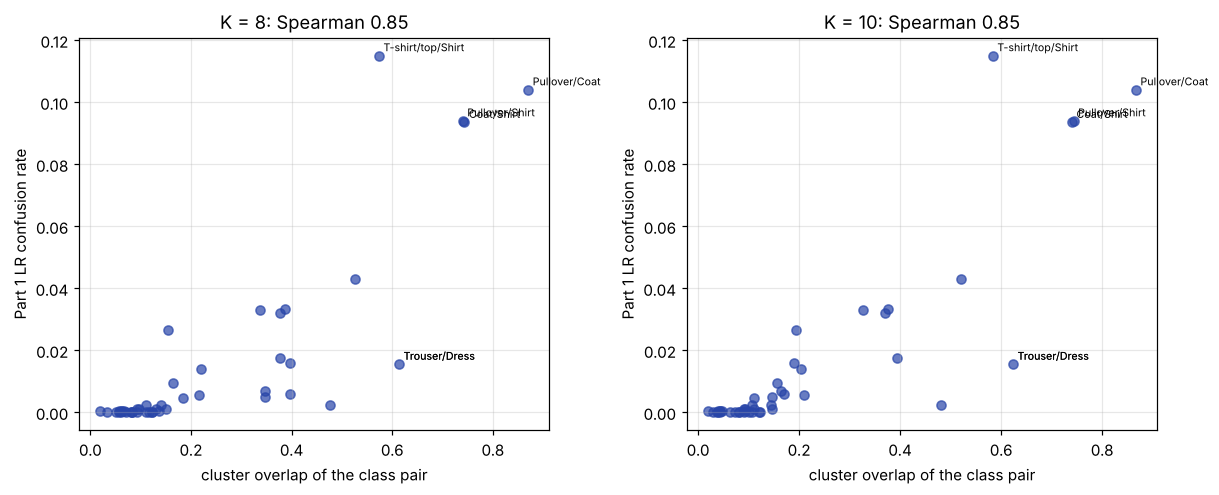

In [25]:
# ---------------- 4.3 cluster overlap of class pairs vs Part 1 (logistic regression) confusions -----------------
cm_lr = confusion_matrix(yva, PRED_VA["LR"], labels=range(10)); pairs = [(i, j) for i in range(10) for j in range(i + 1, 10)]
conf_rate = {p: (cm_lr[p[0], p[1]] + cm_lr[p[1], p[0]]) / (cm_lr[p[0]].sum() + cm_lr[p[1]].sum()) for p in pairs}
def overlap_table(km, y):
    share = np.array([np.bincount(km.labels_[y == c], minlength=km.n_clusters) / (y == c).sum() for c in range(10)])
    return {p: np.minimum(share[p[0]], share[p[1]]).sum() for p in pairs}
link_rows, OV = [], {}
for K in KM:
    ov = overlap_table(KM[K], yc); OV[K] = ov; rho, pval = spearmanr([ov[p] for p in pairs], [conf_rate[p] for p in pairs])
    link_rows.append({"K": K, "Spearman rho (45 class pairs)": rho, "p-value": pval})
    top = sorted(pairs, key=lambda p: -ov[p])[:6]
    tab = pd.DataFrame([{"class pair": f"{CLASS_NAMES[a]} / {CLASS_NAMES[b]}", "cluster overlap": ov[(a, b)], "Part 1 LR confusion rate": conf_rate[(a, b)], "rank by LR confusion (of 45)": 1 + sorted(pairs, key=lambda p: -conf_rate[p]).index((a, b))} for a, b in top])
    tab.to_csv(RES4 / f"link_to_part1_K{K}.csv", index=False); print(f"K = {K}: class pairs with the highest cluster overlap, and how Part 1 ranks the same pairs"); display(tab.style.format({"cluster overlap": "{:.3f}", "Part 1 LR confusion rate": "{:.3f}"}).hide(axis="index"))
link = pd.DataFrame(link_rows); link.to_csv(RES4 / "link_to_part1_summary.csv", index=False); display(link.style.format({"Spearman rho (45 class pairs)": "{:.2f}", "p-value": "{:.1e}"}).hide(axis="index"))
fig, ax = plt.subplots(1, len(KM), figsize=(5.6 * len(KM), 4.6), squeeze=False); ax = ax[0]
for a_, K in zip(ax, KM):
    a_.scatter([OV[K][p] for p in pairs], [conf_rate[p] for p in pairs], color="#2845A8", alpha=.7)
    for p in sorted(pairs, key=lambda q: -OV[K][q])[:5] + [(CLASS_NAMES.index("Trouser"), CLASS_NAMES.index("Dress"))]:
        a_.annotate(f"{CLASS_NAMES[p[0]]}/{CLASS_NAMES[p[1]]}", (OV[K][p], conf_rate[p]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    a_.set_xlabel("cluster overlap of the class pair"); a_.set_ylabel("Part 1 LR confusion rate"); a_.set_title(f"K = {K}: Spearman {link.set_index('K').loc[K, 'Spearman rho (45 class pairs)']:.2f}"); a_.grid(alpha=.3)
fig.tight_layout(); save_fig(fig, "fig12_overlap_vs_confusion", "4.3", "Cluster overlap against Part 1 logistic-regression confusion rate for the 45 class pairs (K-means, raw pixels, seed 2208)."); plt.show()
for _, r in link.iterrows():
    log_experiment(id=f"P4-LINK-K{int(r['K'])}", part_task="4.3", question="Do class pairs that share K-means clusters match Part 1 confusions?", hypothesis="Yes: pairs of similar-looking classes both share clusters and are confused.",
        changed_variable="none", fixed_conditions="K-means partition (seed 2208) vs LR validation confusions", split="cluster_train_idx; validation 10k", seed=SEED, configuration=f"K={int(r['K'])}", metric="Spearman rho over 45 class pairs",
        result=f"{r['Spearman rho (45 class pairs)']:.2f} (p={r['p-value']:.1e})", output_path="results/part4/link_to_part1_summary.csv", notes="")

**Figure 12 (addresses 4.3).** One point per class pair.

**Interpretation.** Across the 45 class pairs, cluster overlap and Part 1 confusion rate are strongly rank-correlated (Spearman 0.85 at both K = 8 and K = 10). The pairs sharing most clusters are those logistic regression confuses: Pullover/Coat (overlap 0.87; Part 1 rank 2), Pullover/Shirt (0.74; rank 3), Coat/Shirt (0.74; rank 4) and T-shirt/Shirt (0.58; rank 1). Interpretation: most Part 1 errors reflect real overlap of the classes in pixel space, not only weaknesses of a classifier, which also suggests why Shirt was hardest (never a majority of any cluster). One exception: Trouser/Dress overlap is 0.62 but ranks only 12th in Part 1 (confusion rate 1.6%): their silhouettes are similar for a distance-based method, while a supervised linear model separates them (hypothesis: it weights discriminative pixels, such as the gap between trouser legs; untested). Caveat: 3,000 clustered training images against 10,000 validation predictions; correlation, not causation; the 45 pairs share classes and are not independent, so the p-value is only indicative.

## 4.4 Hierarchical clustering on a small subset

**Subset:** 500 images (50 per class), drawn with the fixed seed from the 3,000 clustering images; indices saved in `splits/hier_subset_seed2208.npz`. **Method (slide 33):** agglomerative clustering, starting from one cluster per image and repeatedly merging the two nearest clusters; the result is a tree (dendrogram), not a single partition. **Linkage** defines "nearest": *single* (closest pair), *complete* (farthest pair), *average* (mean pairwise distance), *Ward* (the merge that increases the within-cluster sum of squares least). **Choice, fixed before labels are used: Ward**, because it minimises the same squared-distance criterion J as K-means, so the two methods are compared under one objective. The cophenetic correlation (how well tree distances reproduce the original pairwise distances) is reported for all four as an unlabelled diagnostic.

Linkage comparison on the 500-image subset (cophenetic correlation: unlabelled; ARI/size: descriptive, labels used after the choice of Ward was fixed)


linkage,cophenetic correlation,ARI vs labels at 8 clusters,largest cluster share at 8,ARI vs labels at 10 clusters,largest cluster share at 10
single,0.290,-0.000,0.986,-0.000,0.982
complete,0.639,0.282,0.230,0.282,0.218
average,0.689,0.244,0.312,0.243,0.310
ward,0.600,0.310,0.164,0.325,0.164


Ward vs K-means on the same 500 images (ARI against the labels)


K,Ward ARI,"K-means ARI, fitted on these 500 images","K-means ARI, fitted on 3,000 images (restricted to these 500)"
8,0.310,0.339,0.348
10,0.325,0.355,0.331


Ward tree cut into 2 clusters (counts of the 500 images):


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
1,2,1,1,3,3,50,7,50,31,50
2,48,49,49,47,47,0,43,0,19,0


Ward tree cut into 3 clusters (counts of the 500 images):


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
1,2,1,1,3,3,50,7,50,31,50
2,5,45,0,31,1,0,0,0,0,0
3,43,4,49,16,46,0,43,0,19,0


Ward tree cut into 4 clusters (counts of the 500 images):


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
1,0,0,0,0,0,3,0,0,20,35
2,2,1,1,3,3,47,7,50,11,15
3,5,45,0,31,1,0,0,0,0,0
4,43,4,49,16,46,0,43,0,19,0


Nestedness of the 10-cluster partition inside the 5-cluster partition: Ward tree 1.000 (by construction), K-means (seed 2208, 3,000 images) 0.875


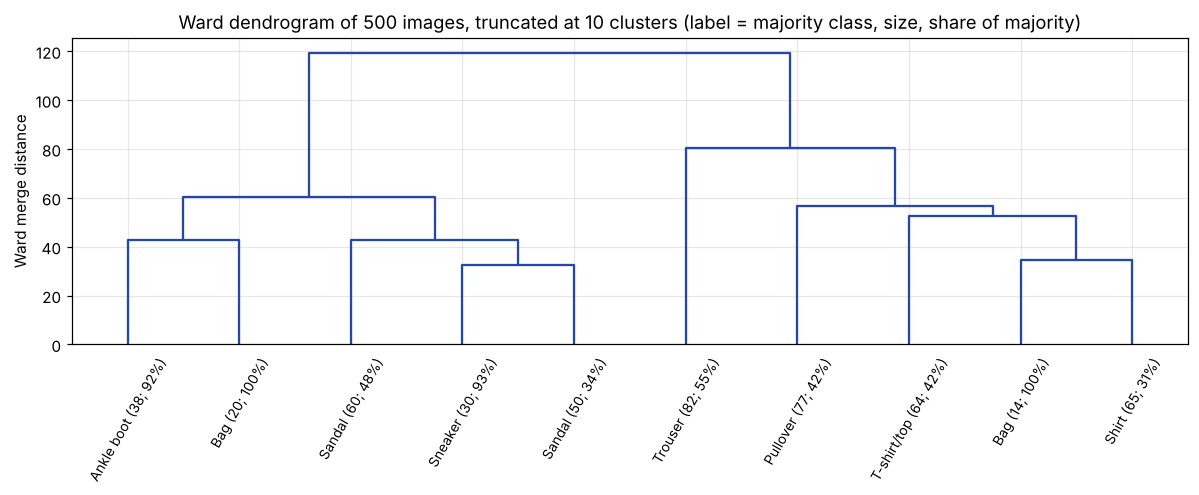

In [26]:
# ---------------- 4.4 hierarchical clustering: small fixed subset, four linkages, Ward chosen a priori -----------------
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram, to_tree
from scipy.spatial.distance import pdist
def pick_sub(idx, lab, n): return np.sort(train_test_split(idx, train_size=n, stratify=lab, random_state=SEED)[0])
HIER_IDX = pick_sub(IDX["cluster_train_idx"], y_off[IDX["cluster_train_idx"]], 500)
hpath = SPLITS_DIR / f"hier_subset_seed{SEED}.npz"
if hpath.exists():
    with np.load(hpath) as old: assert np.array_equal(old["hier_subset_idx"], HIER_IDX), "saved hierarchical subset differs: frozen"
else: np.savez_compressed(hpath, hier_subset_idx=HIER_IDX)
assert np.isin(HIER_IDX, IDX["cluster_train_idx"]).all() and (np.bincount(y_off[HIER_IDX]) == 50).all()
Xh, yh = prep(X_off[HIER_IDX]), y_off[HIER_IDX]; D = pdist(Xh)
LINKS = {}; rows = []
for meth in ["single", "complete", "average", "ward"]:
    t0 = time.perf_counter(); Z = linkage(Xh, method=meth); TIMES.append({"what": f"hierarchical linkage {meth} (500 images)", "seconds": time.perf_counter() - t0}); LINKS[meth] = Z
    c = cophenet(Z, D)[0]; row = {"linkage": meth, "cophenetic correlation": c}
    for K in (K_SEL, 10): row[f"ARI vs labels at {K} clusters"] = adjusted_rand_score(yh, fcluster(Z, K, "maxclust")); row[f"largest cluster share at {K}"] = np.bincount(fcluster(Z, K, "maxclust")).max() / len(yh)
    rows.append(row)
link_tab = pd.DataFrame(rows); link_tab.to_csv(RES4 / "linkage_comparison.csv", index=False)
print("Linkage comparison on the 500-image subset (cophenetic correlation: unlabelled; ARI/size: descriptive, labels used after the choice of Ward was fixed)")
display(link_tab.style.format({c: "{:.3f}" for c in link_tab.columns if c != "linkage"}).hide(axis="index"))
for meth in LINKS:
    log_experiment(id=f"P4-HIER-{meth}", part_task="4.4", question="Which linkage, and what does the tree show?", hypothesis="Single linkage chains into one giant cluster; Ward gives balanced, K-means-like groups.",
        changed_variable="linkage", fixed_conditions="500 stratified images, raw pixels, Euclidean distance", split="hier_subset (from cluster_train_idx)", seed=SEED, configuration=meth, metric="cophenetic correlation",
        result=f"{link_tab.set_index('linkage').loc[meth, 'cophenetic correlation']:.3f}", output_path="results/part4/linkage_comparison.csv", notes="Ward chosen a priori (same criterion as K-means)")

# like-for-like comparison with K-means on the SAME 500 images (labels used descriptively)
pos = np.searchsorted(IDX["cluster_train_idx"], HIER_IDX); assert (IDX["cluster_train_idx"][pos] == HIER_IDX).all()
cmp_rows = []
for K in sorted({K_SEL, 10}):
    cmp_rows.append({"K": K, "Ward ARI": adjusted_rand_score(yh, fcluster(LINKS["ward"], K, "maxclust")), "K-means ARI, fitted on these 500 images": adjusted_rand_score(yh, km_fit(Xh, K, SEED).labels_),
                     "K-means ARI, fitted on 3,000 images (restricted to these 500)": adjusted_rand_score(yh, FITS_RAW[(K, SEED)].labels_[pos])})
cmp500 = pd.DataFrame(cmp_rows); cmp500.to_csv(RES4 / "ward_vs_kmeans_same500.csv", index=False)
print("Ward vs K-means on the same 500 images (ARI against the labels)"); display(cmp500.style.format({c: "{:.3f}" for c in cmp500.columns if c != "K"}).hide(axis="index"))
for _, r in cmp500.iterrows():
    log_experiment(id=f"P4-HIERCMP-K{int(r['K'])}", part_task="4.4", question="Is Ward comparable to K-means on identical images?", hypothesis="Similar agreement with the labels.", changed_variable="algorithm (Ward vs K-means)",
        fixed_conditions="same 500 images, raw pixels, Euclidean distance", split="hier_subset", seed=SEED, configuration=f"K={int(r['K'])}", metric="ARI vs labels (Ward / K-means fitted on 500 / K-means from 3,000)",
        result="{:.3f} / {:.3f} / {:.3f}".format(r["Ward ARI"], r["K-means ARI, fitted on these 500 images"], r["K-means ARI, fitted on 3,000 images (restricted to these 500)"]), output_path="results/part4/ward_vs_kmeans_same500.csv", notes="descriptive")

# nested splits of the Ward tree: which classes separate first
Zw = LINKS["ward"]; splits = {}
for K in (2, 3, 4):
    lab = fcluster(Zw, K, "maxclust"); splits[K] = pd.crosstab(pd.Series(lab, name="cluster"), pd.Series(yh, name="class")).rename(columns=dict(enumerate(CLASS_NAMES)))
    print(f"Ward tree cut into {K} clusters (counts of the 500 images):"); display(splits[K])
# nestedness: share of each finer cluster that falls in its majority coarse cluster (1.0 = perfectly nested)
def nestedness(fine, coarse): return pd.crosstab(fine, coarse).max(axis=1).sum() / len(fine)
nest_h = nestedness(fcluster(Zw, 10, "maxclust"), fcluster(Zw, 5, "maxclust")); nest_k = nestedness(FITS_RAW[(10, SEED)].labels_, FITS_RAW[(5, SEED)].labels_)
print(f"Nestedness of the 10-cluster partition inside the 5-cluster partition: Ward tree {nest_h:.3f} (by construction), K-means (seed 2208, 3,000 images) {nest_k:.3f}")

lab10 = fcluster(Zw, 10, "maxclust"); nodes = to_tree(Zw, rd=True)[1]
def leaf_label(i):
    if i < len(yh): return CLASS_NAMES[yh[i]]
    mem = nodes[i].pre_order(); maj = np.bincount(yh[mem], minlength=10).argmax(); return f"{CLASS_NAMES[maj]} ({len(mem)}; {np.mean(yh[mem] == maj):.0%})"
fig, ax = plt.subplots(figsize=(11, 4.6)); dendrogram(Zw, truncate_mode="lastp", p=10, leaf_label_func=leaf_label, leaf_rotation=60, leaf_font_size=9, color_threshold=0, above_threshold_color="#2845A8", ax=ax)
ax.set_ylabel("Ward merge distance"); ax.set_title("Ward dendrogram of 500 images, truncated at 10 clusters (label = majority class, size, share of majority)"); fig.tight_layout()
save_fig(fig, "fig13_dendrogram_ward", "4.4", "Ward dendrogram of the 500-image subset truncated at ten clusters; leaf labels give the majority class, cluster size and the share of the majority class."); plt.show()

**Figure 13 (addresses 4.4).** Ward dendrogram truncated at ten clusters.

**Interpretation.** Cophenetic correlation: single 0.29, complete 0.64, average 0.69, Ward 0.60. Single linkage chains: 98.6% of the images fall in one cluster at 8 clusters (ARI 0.00). Among the linkages, Ward gives balanced clusters (largest 16%) and the best agreement with the labels (ARI 0.31 at 8 and 0.33 at 10, against 0.24 to 0.28 for complete and average). Ward was chosen in advance for its shared criterion with K-means, not for the cophenetic value (average linkage preserves pairwise distances best); the ARI comparison is descriptive. On the same 500 images K-means agrees at least as well (ARI 0.339 at K = 8 and 0.355 at K = 10 when fitted on these 500; 0.348 and 0.331 with the 3,000-image centres; Ward 0.310 and 0.325), so the tree's gain is not accuracy. **What the tree adds:** the first split separates footwear and most bags (Sandal, Sneaker, Ankle boot 50 each, Bag 31) from garments; the next separates trousers and dresses from the tops; the four-cluster cut isolates a bag/ankle-boot group. Ward partitions are nested by construction (nestedness 1.000) while K-means partitions at K = 5 and K = 10 are only 0.875 nested, so the tree gives one consistent picture across resolutions and no K must be fixed first. Limit: 500 images (the pairwise distance matrix grows as N²).

---
# Part 5: Learned representations and one extension

## 5.1 Clustering the hidden-layer features of the selected MLP

**Network (frozen).** The MLP is chosen on validation with the Part 1 rule: among all Part 2 and Part 3 configurations, the one with the fewest parameters whose mean validation accuracy is within 0.1 percentage points of the best. **Features:** activations of its final hidden layer (after ReLU), computed with the frozen checkpoint, no further training. **Protocol:** exactly that of Part 4 (same 3,000 and 1,000 images, same K values, seeds, restarts, algorithm and scores). **Transformation:** none for the main analysis; as a sensitivity check the features are also standardised with the mean and standard deviation of the 3,000 *training* features only (never of the held-out ones). **Caution:** this network was trained with the labels of the 50,000 training images, which include the 3,000 clustered ones, so on those images the learned features are not label-free; the 1,000 unseen validation images are the fairer comparison. K = K_sel and K = 10 are used for the same-K comparison; the K suggested by the learned features themselves is reported separately.

All MLP configurations of Parts 2 and 3 (mean validation accuracy over seeds 2208, 1, 2)


configuration,parameters,val acc mean,within 0.1 pp of best
wd 1e-3,"235,146",0.9018,True
wd 1e-4,"235,146",0.9018,True
baseline 128,"101,770",0.9013,True
large 256-128,"235,146",0.9005,False
lr 0.5,"101,770",0.8943,False
small 32,"25,450",0.8920,False
lr 0.01,"101,770",0.8712,False
wd 1e-2,"235,146",0.8502,False


Selected MLP: baseline 128, hidden layers [128], 101,770 parameters (fewest within 0.1 pp of the best, 0.9018); three checkpoints, seeds [2208, 1, 2]
features: 128 dimensions; share of units never active on the 3,000 images (seed 2208 network): 0.0%; feature scale: mean 0.44, mean per-unit std 0.62


Unlabelled evidence for K on the learned features (seed-2208 network; three K-means seeds, each the best of 10 starts)


K,J train (mean),J train per image,J val per image,BIC-style cost,J spread over seeds (max-min)/mean,ARI between seeds (mean of 3 pairs),elbow distance
2,"140,504",46.83,46.82,"141,529",0.0000,1.000,0.000
3,"125,257",41.75,41.42,"126,794",0.0000,1.000,0.098
4,"111,719",37.24,37.18,"113,769",0.0105,0.726,0.183
5,"101,347",33.78,33.90,"103,909",0.0000,0.990,0.242
6,"92,348",30.78,30.31,"95,422",0.0002,0.961,0.289
8,"82,911",27.64,27.09,"87,010",0.0001,0.962,0.315
10,"75,398",25.13,25.23,"80,522",0.0011,0.874,0.326
12,"70,404",23.47,23.59,"76,553",0.0039,0.872,0.316
14,"66,943",22.31,22.69,"74,116",0.0053,0.849,0.293
16,"64,344",21.45,21.81,"72,543",0.0080,0.682,0.264


Learned features: elbow rule picks K = 10, BIC-style cost lowest at K = 30 (raw pixels: 8 and 8). Same-K comparison below uses K = 8 and 10.


... (2 outputs left out)

Cluster composition of the learned features at K = 8 (rows = clusters, columns = classes, counts of the 3,000 images)


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
0,3,2,97,10,257,1,154,0,3,0
1,0,267,0,0,0,0,0,0,0,0
2,53,28,9,283,15,8,26,0,9,1
3,0,0,0,0,0,90,0,28,0,285
4,230,2,6,5,1,0,74,0,1,0
5,0,0,0,0,0,194,0,272,48,14
6,4,0,0,0,0,0,0,0,148,0
7,10,1,188,2,27,7,46,0,91,0


Cluster composition of the learned features at K = 10 (rows = clusters, columns = classes, counts of the 3,000 images)


class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
cluster,,,,,,,,,,
0,0,273,0,0,0,0,0,0,0,0
1,0,0,0,0,0,176,0,269,5,14
2,0,0,0,0,0,8,0,29,0,233
3,9,2,209,3,33,1,52,0,7,0
4,4,0,0,0,0,0,0,0,136,0
5,0,0,0,0,0,110,0,2,0,51
6,227,1,3,3,1,0,71,0,1,0
7,2,1,75,3,243,0,144,0,3,0
8,0,0,0,0,0,0,1,0,138,1


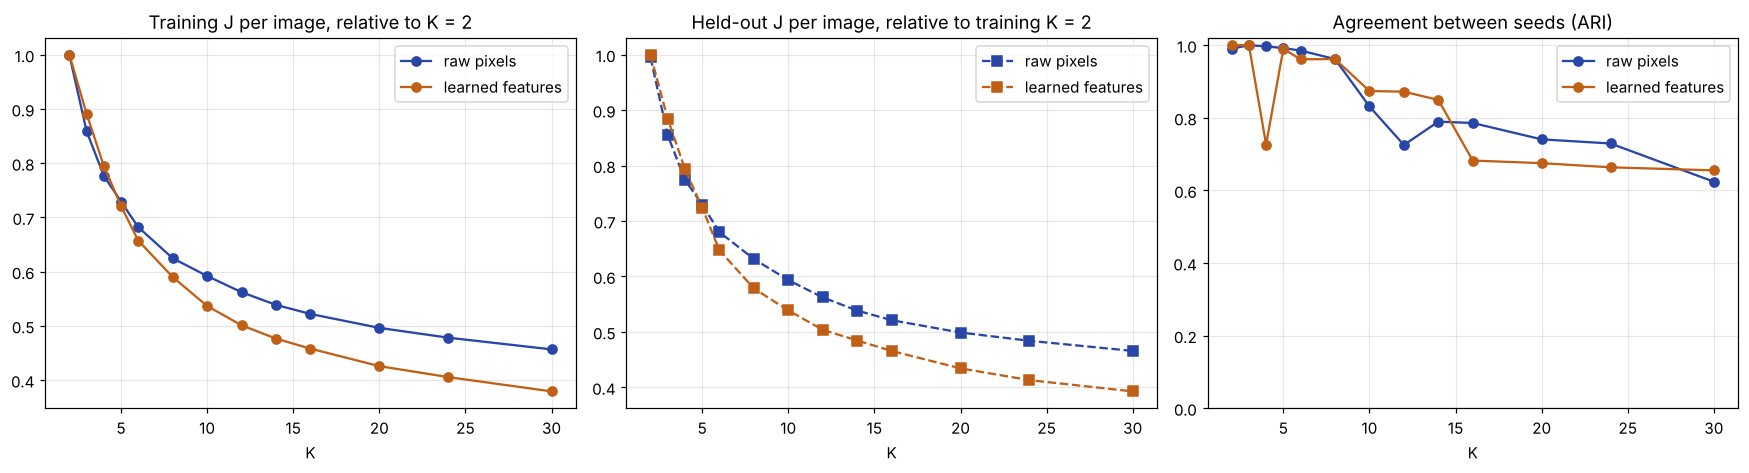

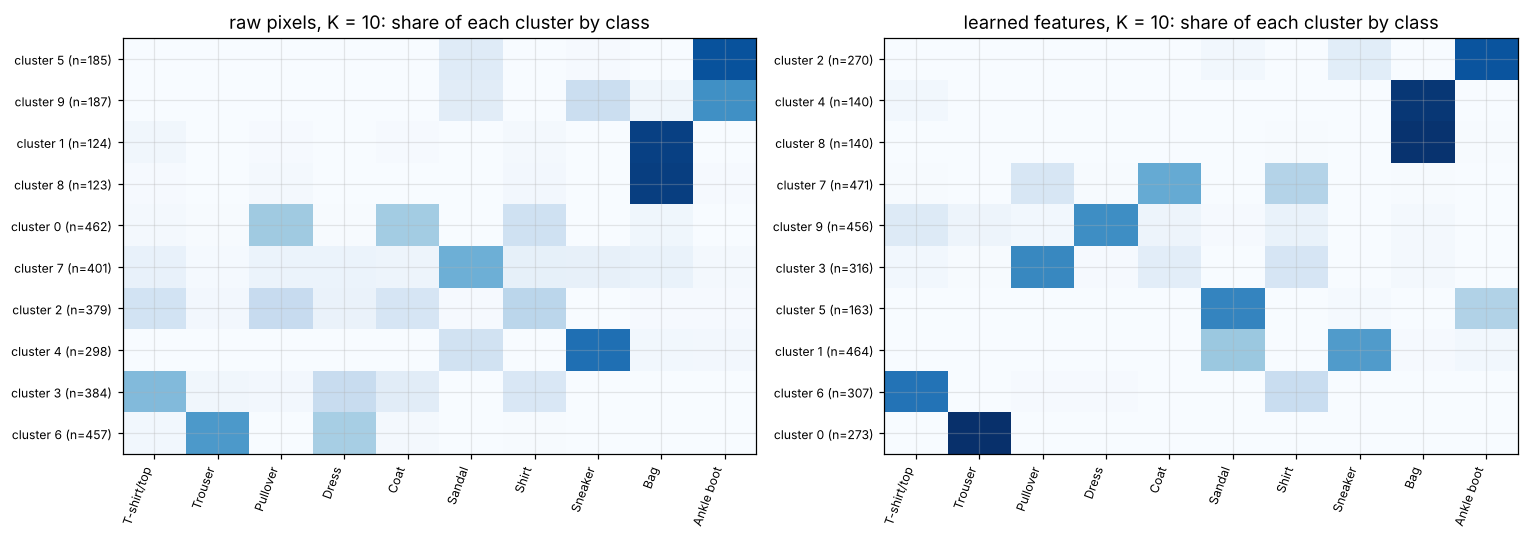

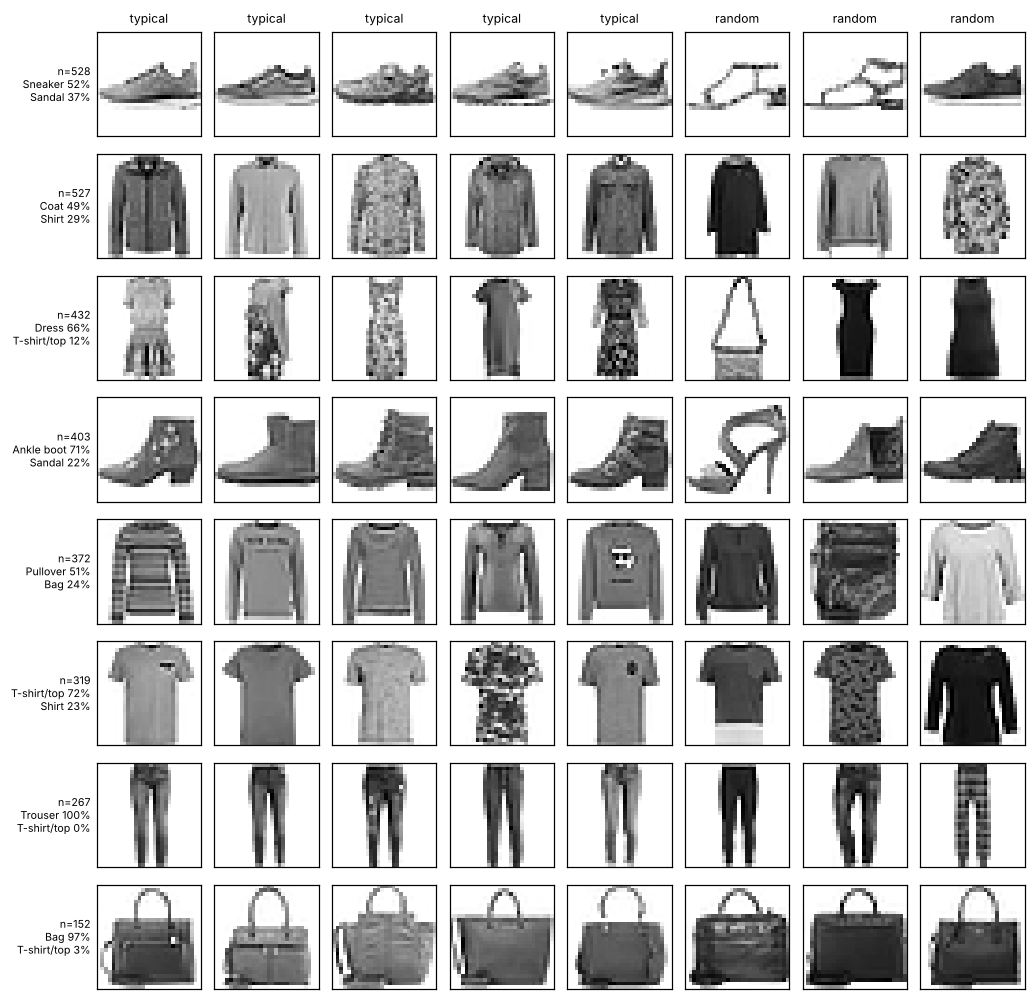

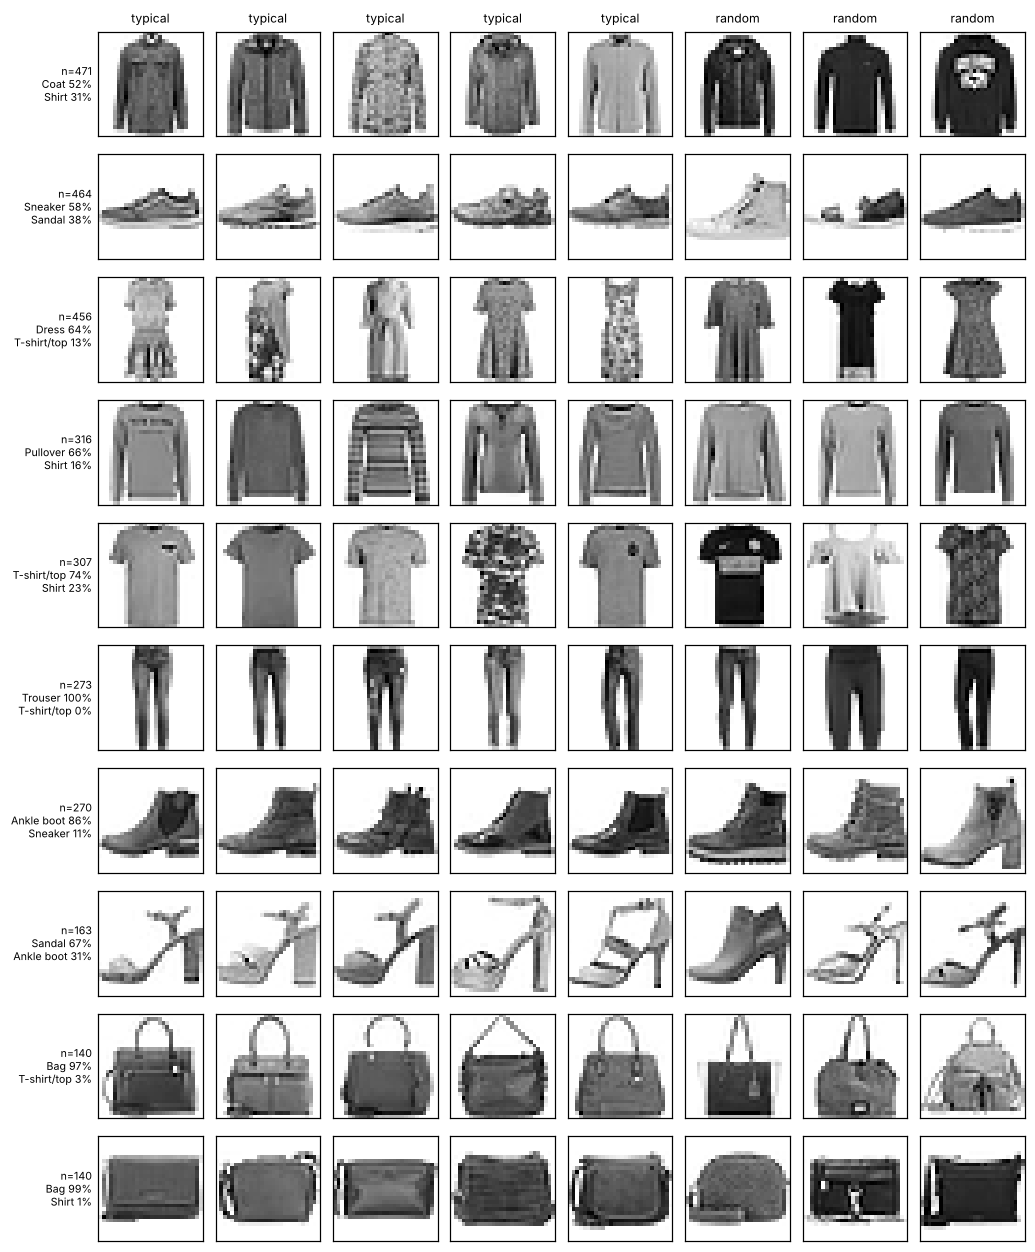

In [27]:
# ---------------- 5.1 selection of the MLP, feature extraction, and the Part 4 protocol on learned features -----------------
from scipy.stats import binomtest
reset_register("P5-")
RES5 = ROOT / "results" / "part5"; RES5.mkdir(parents=True, exist_ok=True)
def at_best_(r): return r["hist"].iloc[r["best_epoch"] - 1]
seen, rows = set(), []
for nm, rs in CFG.items():
    if id(rs) in seen: continue
    seen.add(id(rs)); rows.append({"configuration": nm, "parameters": rs[0]["params"], "val acc mean": np.mean([at_best_(r).val_acc for r in rs])})
sel_tab = pd.DataFrame(rows).sort_values("val acc mean", ascending=False)
best_acc = sel_tab["val acc mean"].max(); SEL_MLP = sel_tab[sel_tab["val acc mean"] >= best_acc - 0.001].sort_values("parameters").iloc[0]["configuration"]
SEL_RUNS = CFG[SEL_MLP]; SEL_HIDDEN = SEL_RUNS[0]["hidden"]; sel_tab["within 0.1 pp of best"] = sel_tab["val acc mean"] >= best_acc - 0.001
print("All MLP configurations of Parts 2 and 3 (mean validation accuracy over seeds 2208, 1, 2)"); display(sel_tab.style.format({"val acc mean": "{:.4f}", "parameters": "{:,}"}).hide(axis="index"))
print(f"Selected MLP: {SEL_MLP}, hidden layers {SEL_HIDDEN}, {SEL_RUNS[0]['params']:,} parameters (fewest within 0.1 pp of the best, {best_acc:.4f}); three checkpoints, seeds {SEEDS}")

def hidden_features(run, X):
    m = MLP(run["hidden"]); m.load_state_dict(run["best_state"]); m.eval()          # frozen checkpoint (lowest validation loss)
    with torch.no_grad():
        x = torch.from_numpy(X)
        for layer in m.layers[:-1]: x = torch.relu(layer(x))                         # output of the final hidden layer
    return x.numpy()
Zc_all = {r["seed"]: hidden_features(r, Xc) for r in SEL_RUNS}; Zcv_all = {r["seed"]: hidden_features(r, Xcv) for r in SEL_RUNS}
Zc, Zcv = Zc_all[SEED], Zcv_all[SEED]
print(f"features: {Zc.shape[1]} dimensions; share of units never active on the 3,000 images (seed {SEED} network): {(Zc.max(0) == 0).mean():.1%}; feature scale: mean {Zc.mean():.2f}, mean per-unit std {Zc.std(0).mean():.2f}")
ksel_f, FITS_F = kmeans_sweep(Zc, Zcv, "learned features"); ksel_f.to_csv(RES5 / "k_selection_learned.csv", index=False)
K_ELBOW_F = int(ksel_f.loc[ksel_f["elbow distance"].idxmax(), "K"]); K_BIC_F = int(ksel_f.loc[ksel_f["BIC-style cost"].idxmin(), "K"])
print("Unlabelled evidence for K on the learned features (seed-2208 network; three K-means seeds, each the best of 10 starts)")
display(ksel_f.style.format({"J train (mean)": "{:,.0f}", "J train per image": "{:.2f}", "J val per image": "{:.2f}", "BIC-style cost": "{:,.0f}", "J spread over seeds (max-min)/mean": "{:.4f}", "ARI between seeds (mean of 3 pairs)": "{:.3f}", "elbow distance": "{:.3f}"}).hide(axis="index"))
print(f"Learned features: elbow rule picks K = {K_ELBOW_F}, BIC-style cost lowest at K = {K_BIC_F} (raw pixels: {K_ELBOW} and {K_BIC}). Same-K comparison below uses K = {K_SEL} and 10.")

# same-K comparison: raw pixels vs learned features (three networks), plus a standardised-feature sensitivity check
def km_row(label, Ztr, Zva, K):
    runs = [km_fit(Ztr, K, s) for s in SEEDS]; km = runs[0]
    return {"representation": label, "K": K, **cluster_scores(km.labels_, yc), **{f"held-out {k}": v for k, v in heldout_scores(km, yc, Zva, ycv).items()}, "ARI between seeds (3 pairs)": pair_ari([r.labels_ for r in runs])}, km
rows, KMF = [], {}
for K in sorted({K_SEL, 10}):
    sc_r = scores.set_index("K").loc[K]
    rows.append({"representation": "raw pixels (Part 4)", "K": K, **{k: sc_r[k] for k in ["purity", "ARI", "NMI", "held-out purity", "held-out ARI", "held-out NMI"]}, "ARI between seeds (3 pairs)": ksel.set_index("K").loc[K, "ARI between seeds (mean of 3 pairs)"]})
    for s in SEEDS:
        r_, km_ = km_row(f"learned, network seed {s}", Zc_all[s], Zcv_all[s], K); rows.append(r_)
        if s == SEED: KMF[K] = km_
    mu, sd = Zc.mean(0), Zc.std(0) + 1e-8                                              # fitted on the 3,000 TRAINING features only
    rows.append(km_row("learned, seed 2208, standardised", (Zc - mu) / sd, (Zcv - mu) / sd, K)[0])
cmp = pd.DataFrame(rows); cmp.to_csv(RES5 / "raw_vs_learned_same_K.csv", index=False)
print("Same-K comparison (labels used only to describe; held-out = 1,000 unseen validation images on the fixed centres)")
display(cmp.style.format({c: "{:.3f}" for c in cmp.columns if c not in ("representation", "K")}).hide(axis="index"))
for _, r in cmp.iterrows():
    log_experiment(id=f"P5-FEAT-K{int(r['K'])}-{r['representation']}", part_task="5.1", question="Do learned hidden features cluster better than raw pixels at the same K?", hypothesis="Yes: the supervised network separates the classes in feature space.",
        changed_variable="representation (raw pixels vs final hidden layer)", fixed_conditions="same 3,000/1,000 images, K, seeds, best of 10 random starts, same scores", split="cluster_train_idx; cluster_val_idx (held-out)", seed="2208/1/2",
        configuration=f"{r['representation']}, K={int(r['K'])}", metric="purity / ARI / NMI (held-out purity / ARI / NMI)", result="{:.3f} / {:.3f} / {:.3f} ({:.3f} / {:.3f} / {:.3f})".format(r["purity"], r["ARI"], r["NMI"], r["held-out purity"], r["held-out ARI"], r["held-out NMI"]),
        output_path="results/part5/raw_vs_learned_same_K.csv", notes="network trained with labels of the 50k training images")

for K in KMF:
    compf = composition(KMF[K], yc); compf.to_csv(RES5 / f"composition_learned_K{K}.csv"); print(f"Cluster composition of the learned features at K = {K} (rows = clusters, columns = classes, counts of the 3,000 images)"); display(compf)
# figures: evidence for K (raw vs learned) and class-by-cluster counts at K = 10
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for tab, lab, c in [(ksel, "raw pixels", "#2845A8"), (ksel_f, "learned features", "#C06016")]:
    ax[0].plot(tab.K, tab["J train per image"] / tab["J train per image"].iloc[0], "o-", color=c, label=lab); ax[1].plot(tab.K, tab["J val per image"] / tab["J train per image"].iloc[0], "s--", color=c, label=lab); ax[2].plot(tab.K, tab["ARI between seeds (mean of 3 pairs)"], "o-", color=c, label=lab)
ax[0].set_title("Training J per image, relative to K = 2"); ax[1].set_title("Held-out J per image, relative to training K = 2"); ax[2].set_title("Agreement between seeds (ARI)"); ax[2].set_ylim(0, 1.02)
for a in ax: a.set_xlabel("K"); a.grid(alpha=.3); a.legend()
fig.tight_layout(); save_fig(fig, "fig14_k_evidence_raw_vs_learned", "5.1", "Unlabelled evidence for K on raw pixels and on learned hidden features (J normalised by its value at K = 2 so the two scales are comparable)."); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (km_, ttl) in zip(ax, [(KM[10], "raw pixels, K = 10"), (KMF[10], "learned features, K = 10")]):
    comp = composition(km_, yc); comp = comp.loc[comp.idxmax(axis=1).sort_values(kind="stable").index]
    a.imshow(comp.div(comp.sum(axis=1), axis=0).to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto"); a.set_xticks(range(10), CLASS_NAMES, rotation=70, ha="right", fontsize=8); a.set_yticks(range(len(comp)), [f"cluster {k} (n={comp.loc[k].sum()})" for k in comp.index], fontsize=8); a.set_title(ttl + ": share of each cluster by class")
fig.tight_layout(); save_fig(fig, "fig15_composition_raw_vs_learned_K10", "5.1", "Class composition of the K = 10 clusters (share of each cluster), raw pixels against learned features, seed 2208."); plt.show()

def example_figure_features(km, Z, K, fname, caption):
    rng = np.random.default_rng(SEED); order = np.argsort(-np.bincount(km.labels_)); compK = composition(km, yc)
    fig, axs = plt.subplots(K, 8, figsize=(9.5, 1.15 * K))
    for r_i, k in enumerate(order):
        mem = np.where(km.labels_ == k)[0]; dist = np.linalg.norm(Z[mem] - km.cluster_centers_[k], axis=1); near_ = mem[np.argsort(dist)[:5]]; rand_ = rng.choice(mem, 3, replace=False)
        for c_i, i in enumerate(list(near_) + list(rand_)): axs[r_i, c_i].imshow(Xc[i].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); axs[r_i, c_i].set_xticks([]); axs[r_i, c_i].set_yticks([])
        top = compK.loc[k].sort_values(ascending=False)[:2]; axs[r_i, 0].set_ylabel(f"n={len(mem)}\n{top.index[0]} {top.iloc[0]/len(mem):.0%}\n{top.index[1]} {top.iloc[1]/len(mem):.0%}", rotation=0, ha="right", va="center", fontsize=7)
    for c_i, t in enumerate(["typical"] * 5 + ["random"] * 3): axs[0, c_i].set_title(t, fontsize=8)
    fig.tight_layout(); save_fig(fig, fname, "5.1", caption); plt.show()
example_figure_features(KMF[K_SEL], Zc, K_SEL, f"fig16_learned_examples_K{K_SEL}", f"K = {K_SEL} clusters of learned features (seed-2208 network): five members nearest to the centre in feature space and three random members.")
example_figure_features(KMF[10], Zc, 10, "fig16b_learned_examples_K10", "K = 10 clusters of learned features (seed-2208 network): five members nearest to the centre in feature space and three random members.")

**Figures 14 to 16 (address 5.1).** Evidence for K on both representations (14), class composition of the K = 10 clusters (15), example images of the learned-feature clusters (16, 16b).

**Interpretation.** Same protocol as Part 4, applied to the 128 final-hidden-layer features of the selected network ("baseline 128", seed 2208). At equal K the learned features give purer clusters: purity 0.643 against 0.532 at K=8 and 0.710 against 0.551 at K=10; ARI 0.488 against 0.356 and 0.527 against 0.339. On the 1,000 held-out validation images the gap remains (ARI 0.500 against 0.348 at K=8, 0.514 against 0.345 at K=10), which is the fair check because the network saw the labels of the 3,000 clustered training images. The networks with seeds 1 and 2 point the same way (K=10 purity 0.655 and 0.725), but the size of the gain depends on the network. The elbow rule gives K=10 for learned features (K=8 for raw pixels); the BIC-style cost falls to K=30 and gives no signal. Stability is not better: seed ARI at K=10 is 0.87, 0.74 and 0.83 (raw 0.83). Standardising features (statistics from training features only) changes purity by under 0.002. Composition shows Trouser, Bag, T-shirt, Dress, Sandal and Ankle boot each with a dominant cluster, while Coat, Pullover and Shirt still share one. Hypothesis (not tested): supervised training pulls images of one class together in the hidden layer; Shirt/Pullover/Coat remain mixed because the network also confuses them.

## 5.2 Extension, route B: ensembling

**The three routes (in short).** *A, frozen pre-trained encoder:* extract features with a network trained on another large dataset (e.g. ResNet-18) and train only a small classifier on them; it needs the pre-trained weights, which cannot be downloaded in this environment, and larger inputs. *B, ensembling:* combine several already-trained models; it needs no new training here but costs several times the memory and inference time. *C, test-time augmentation:* average the predictions of one model over slightly changed copies of each test image; it needs no training and costs one forward pass per copy, but the changes must keep the label. **Chosen: B**, because the three trained checkpoints of the selected MLP already exist, so the route can be tested without new training and under the same data and budget; this is a statement about convenience, not a claim that B is better than A or C, which were not tested. **Under a fixed budget I would investigate C next,** since it needs no training and costs only extra forward passes; that is a cost argument, not a ranking.

**Rule, specified completely and fixed before looking at any ensemble result.** Members: the three checkpoints (seeds 2208, 1, 2; lowest-validation-loss epoch) of the selected MLP. Combination: average the three softmax probability vectors with equal weights; predict the class with the highest average (the lowest class index if tied). **Comparison:** the ensemble and each member on the *same* validation images (and later the same test images), with the same preprocessing. **Expectation:** the ensemble is at least as accurate as the average member, with the gain concentrated on classes where members disagree. **Extra cost:** three times the parameters and inference time, and three training runs.

Validation (10,000 images): ensemble against each member, identical images


model,accuracy,cross-entropy,"ensemble right, member wrong","member right, ensemble wrong",McNemar exact p (ensemble vs member),parameters,inference seconds,95% interval
"member, seed 2208",0.9012,0.2844,177.000000,103.000000,1.2e-05,"101,770",0.01,
"member, seed 1",0.9026,0.2846,160.000000,100.000000,0.00024,"101,770",0.01,
"member, seed 2",0.9000,0.2780,191.000000,105.000000,6.6e-07,"101,770",0.01,
ensemble (average of 3),0.9086,0.2654,,,,"305,310",0.04,"[0.9028, 0.9141]"


all three members give the same prediction on 91.8% of the validation images
Class-level effect of the ensemble on validation recall


class,member mean recall,member min recall,member max recall,ensemble recall,change (ensemble - member mean)
T-shirt/top,0.870,0.832,0.900,0.879,0.009
Trouser,0.975,0.970,0.978,0.977,0.002
Pullover,0.847,0.823,0.860,0.859,0.012
Dress,0.914,0.898,0.924,0.921,0.007
Coat,0.839,0.785,0.866,0.851,0.012
Sandal,0.969,0.957,0.977,0.973,0.004
Shirt,0.710,0.676,0.732,0.725,0.015
Sneaker,0.957,0.946,0.968,0.963,0.006
Bag,0.962,0.959,0.964,0.966,0.004
Ankle boot,0.970,0.964,0.973,0.972,0.002


extra cost: 3x parameters (305,310 against 101,770), inference 0.04 s against about 0.01 s per member on 10,000 images, training 82 s for three members against about 27 s for one


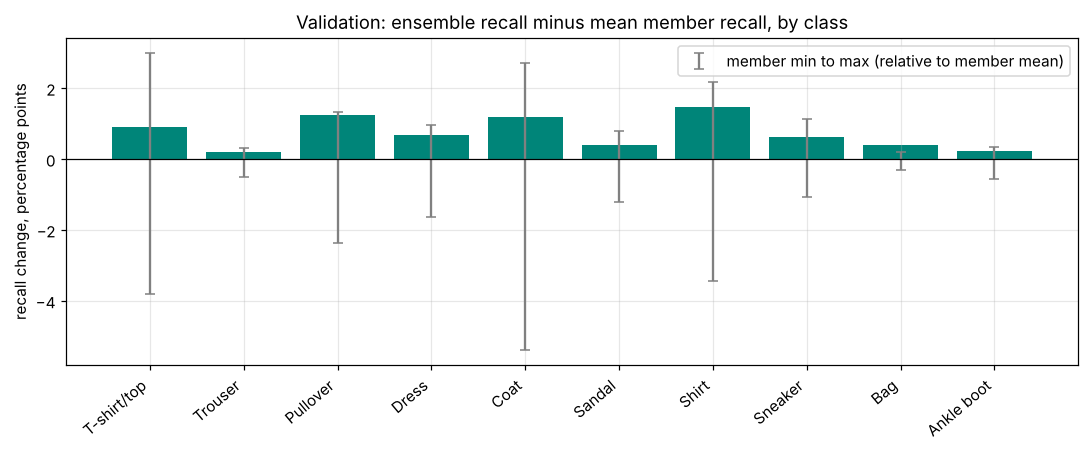

In [28]:
# ---------------- 5.2 ensemble of the three checkpoints: rule, evaluation function (reused on test later), validation results -----------------
def softmax_probs(run, X):
    m = MLP(run["hidden"]); m.load_state_dict(run["best_state"]); m.eval()
    with torch.no_grad(): return F.softmax(m(torch.from_numpy(X)), dim=1).numpy()

def ensemble_eval(X, y, label):
    """Members and equal-weight probability-averaging ensemble on identical images; returns tables and the raw predictions."""
    P, secs = [], []
    for r in SEL_RUNS: t0 = time.perf_counter(); P.append(softmax_probs(r, X)); secs.append(time.perf_counter() - t0)
    avg = np.mean(P, axis=0); pred_e = avg.argmax(1); preds = [p.argmax(1) for p in P]
    ce = lambda p: float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())
    rows = []
    for r, p, pr, sec in zip(SEL_RUNS, P, preds, secs):
        ok_m, ok_e = pr == y, pred_e == y; only_e, only_m = int((ok_e & ~ok_m).sum()), int((~ok_e & ok_m).sum())
        rows.append({"model": f"member, seed {r['seed']}", "accuracy": ok_m.mean(), "cross-entropy": ce(p), "ensemble right, member wrong": only_e, "member right, ensemble wrong": only_m,
                     "McNemar exact p (ensemble vs member)": binomtest(only_e, only_e + only_m, 0.5).pvalue if only_e + only_m else 1.0, "parameters": r["params"], "inference seconds": sec})
    lo, hi = wilson_interval(int((pred_e == y).sum()), len(y))
    rows.append({"model": "ensemble (average of 3)", "accuracy": (pred_e == y).mean(), "cross-entropy": ce(avg), "ensemble right, member wrong": np.nan, "member right, ensemble wrong": np.nan, "McNemar exact p (ensemble vs member)": np.nan,
                 "parameters": sum(r["params"] for r in SEL_RUNS), "inference seconds": sum(secs)})
    summ = pd.DataFrame(rows); summ["95% interval"] = ""; summ.loc[summ.index[-1], "95% interval"] = f"[{lo:.4f}, {hi:.4f}]"
    rec = pd.DataFrame({"class": CLASS_NAMES, "member mean recall": np.mean([per_class_table(y, pr)["recall"].to_numpy() for pr in preds], axis=0),
                        "member min recall": np.min([per_class_table(y, pr)["recall"].to_numpy() for pr in preds], axis=0), "member max recall": np.max([per_class_table(y, pr)["recall"].to_numpy() for pr in preds], axis=0),
                        "ensemble recall": per_class_table(y, pred_e)["recall"].to_numpy()}); rec["change (ensemble - member mean)"] = rec["ensemble recall"] - rec["member mean recall"]
    agree = float(np.mean((preds[0] == preds[1]) & (preds[1] == preds[2])))
    return summ, rec, agree, pred_e, preds

ens_sum, ens_rec, ens_agree, ens_pred_va, mem_pred_va = ensemble_eval(Xva, yva, "validation")
ens_sum.to_csv(RES5 / "ensemble_validation.csv", index=False); ens_rec.to_csv(RES5 / "ensemble_validation_per_class.csv", index=False)
print("Validation (10,000 images): ensemble against each member, identical images")
display(ens_sum.style.format({"accuracy": "{:.4f}", "cross-entropy": "{:.4f}", "McNemar exact p (ensemble vs member)": "{:.2g}", "parameters": "{:,.0f}", "inference seconds": "{:.2f}"}, na_rep="").hide(axis="index"))
print(f"all three members give the same prediction on {ens_agree:.1%} of the validation images")
print("Class-level effect of the ensemble on validation recall"); display(ens_rec.style.format({c: "{:.3f}" for c in ens_rec.columns if c != "class"}).hide(axis="index"))
train_cost = sum(r["seconds"] for r in SEL_RUNS); print(f"extra cost: 3x parameters ({ens_sum['parameters'].iloc[-1]:,} against {SEL_RUNS[0]['params']:,}), inference {ens_sum['inference seconds'].iloc[-1]:.2f} s against about {ens_sum['inference seconds'].iloc[:-1].mean():.2f} s per member on 10,000 images, training {train_cost:.0f} s for three members against about {train_cost/3:.0f} s for one")
for _, r in ens_sum.iterrows():
    log_experiment(id=f"P5-ENS-VAL-{r['model']}", part_task="5.2", question="Does averaging the three checkpoints improve on its members?", hypothesis="Ensemble at least as accurate as the average member; gains on classes where members disagree.",
        changed_variable="single model vs equal-weight probability average of 3", fixed_conditions="same 10,000 validation images, same preprocessing, checkpoints fixed before evaluation", split="validation 10k", seed="2208/1/2", configuration=r["model"],
        metric="accuracy", result=f"{r['accuracy']:.4f}", output_path="results/part5/ensemble_validation.csv", notes="test result is produced by the guarded final cell")
fig, ax = plt.subplots(figsize=(10, 4.2)); x = np.arange(10)
ax.bar(x, ens_rec["change (ensemble - member mean)"] * 100, color=["#008579" if v >= 0 else "#C06016" for v in ens_rec["change (ensemble - member mean)"]])
ax.errorbar(x, np.zeros(10), yerr=[(ens_rec["member mean recall"] - ens_rec["member min recall"]) * 100, (ens_rec["member max recall"] - ens_rec["member mean recall"]) * 100], fmt="none", ecolor="grey", capsize=3, label="member min to max (relative to member mean)")
ax.axhline(0, color="k", lw=.8); ax.set_xticks(x, CLASS_NAMES, rotation=40, ha="right"); ax.set_ylabel("recall change, percentage points"); ax.set_title("Validation: ensemble recall minus mean member recall, by class"); ax.legend(); ax.grid(alpha=.3, axis="y")
fig.tight_layout(); save_fig(fig, "fig17_ensemble_class_effects", "5.2", "Change in validation recall per class from ensembling (bars), with the spread of the three members around their mean (grey)."); plt.show()

**Figure 17 (addresses 5.2, validation).** Class-level effect of the ensemble.

**Interpretation.** The ensemble reaches 0.9086 (95% interval [0.9028, 0.9141]) against 0.9012, 0.9026 and 0.9000 for its members, a gain of 0.0060 to 0.0086 on the same 10,000 images. Against every member, the images the ensemble gets right and the member wrong outnumber the reverse (177 to 103, 160 to 100, 191 to 105; exact McNemar p below 0.001 each). The cross-entropy also improves (0.265 against 0.278 to 0.285). The members give the same prediction on 91.8% of the images, so the gain comes from the other 8.2%. All ten classes gain recall (0.2 to 1.5 points): most on the confusable upper-body classes (Shirt +1.5, Pullover +1.2, Coat +1.2, T-shirt +0.9), least on Trouser and Ankle boot (+0.2), which were already high. **Extra cost:** three times the parameters (305,310 against 101,770), about three times the inference time (about 0.04 s against 0.01 s per 10,000 images) and three training runs (about 80 s against 27 s). Interpretation: averaging removes part of the variance caused by initialisation and batch order, which matters most where the decision is uncertain. Limits: the members share architecture and data, so their errors are correlated and the gain stays below one point; the checkpoints were chosen on these validation images, which affects members and ensemble alike, so the test result below is the unbiased check.

The test-set results for the same frozen rule, from the guarded cell at the end of the notebook, are given in **5.2 (test)** below the frozen test plan.

In [29]:
# ---------------- frozen test evaluation of Parts 4, 5.1 and 5.2: defined here, called ONLY by the guarded cell after the frozen test plan -----------------
def final_test_part45(Xte, yte):
    """Frozen plan (results/test_plan.json): the ensemble and its members on the official test set, and the frozen K-means centres on the 1,000-image test clustering subset."""
    ci = IDX["cluster_test_idx"]; assert len(np.unique(ci)) == 1000 and ci.min() >= 0 and ci.max() < len(yte)
    es, er, ea, _, _ = ensemble_eval(Xte, yte, "test"); es.to_csv(RES5 / "ensemble_test.csv", index=False); er.to_csv(RES5 / "ensemble_test_per_class.csv", index=False)
    print("TEST (10,000 images, evaluated once): ensemble against each member, identical images")
    display(es.style.format({"accuracy": "{:.4f}", "cross-entropy": "{:.4f}", "McNemar exact p (ensemble vs member)": "{:.2g}", "parameters": "{:,.0f}", "inference seconds": "{:.2f}"}, na_rep="").hide(axis="index"))
    print(f"all three members give the same prediction on {ea:.1%} of the test images"); print("Class-level effect of the ensemble on test recall"); display(er.style.format({c: "{:.3f}" for c in er.columns if c != "class"}).hide(axis="index"))
    for _, r in es.iterrows():
        log_experiment(id=f"P5-ENS-TEST-{r['model']}", part_task="5.2", question="Final estimate of the frozen ensemble rule", hypothesis="Test result close to validation result.", changed_variable="none", fixed_conditions="frozen plan results/test_plan.json",
            split="official test 10k", seed="2208/1/2", configuration=r["model"], metric="accuracy", result=f"{r['accuracy']:.4f}", output_path="results/part5/ensemble_test.csv", notes="evaluated once, no tuning afterwards (R7)")
    Xct, yct = Xte[ci], yte[ci]; Zct = hidden_features(SEL_RUNS[0], Xct); rows = []
    for K in sorted({K_SEL, 10}):
        rows.append({"representation": "raw pixels", "K": K, **heldout_scores(KM[K], yc, Xct, yct)}); rows.append({"representation": "learned features (seed-2208 network)", "K": K, **heldout_scores(KMF[K], yc, Zct, yct)})
    ct = pd.DataFrame(rows); ct.to_csv(RES5 / "clustering_test.csv", index=False)
    print("TEST clustering subset (1,000 images assigned to the frozen centres; clusters mapped to their training majority class)"); display(ct.style.format({c: "{:.3f}" for c in ct.columns if c not in ("representation", "K")}).hide(axis="index"))
    for _, r in ct.iterrows():
        log_experiment(id=f"P5-CLTEST-K{int(r['K'])}-{r['representation']}", part_task="4.2/5.1", question="Do the frozen clusters generalise to the test clustering subset?", hypothesis="Similar to the validation held-out scores.", changed_variable="none",
            fixed_conditions="frozen centres (seed 2208), frozen plan", split="cluster_test_idx (official test)", seed=SEED, configuration=f"{r['representation']}, K={int(r['K'])}", metric="purity / ARI / NMI",
            result="{:.3f} / {:.3f} / {:.3f}".format(r["purity"], r["ARI"], r["NMI"]), output_path="results/part5/clustering_test.csv", notes="evaluated once")
    return es, er, ea, ct

## Frozen test plan (R6, R7)

The next cell records, before any test image is used, what is evaluated on the test set: the Part 1 models, the selected MLP and its three-checkpoint ensemble (5.2), and the frozen K-means centres on the test clustering subset (Parts 4 and 5.1). It is saved to `results/test_plan.json` and checked, not overwritten, on later runs; the guarded test evaluation (`RUN_FINAL_TEST`) is switched on once, after all validation work is finished, and nothing is changed afterwards.

In [30]:
test_plan = {
    "split": "official test set (10,000 images, sealed until RUN_FINAL_TEST=True)", "rule": "no model, K, threshold or setting is changed after test results are seen (R7)",
    "part1": {"fit_data": "train 50,000 (no refit)",
        "models": {"logistic_regression": {"C": SEL["LR"], "max_iter": LR_MAXIT, "seed": "deterministic"},
                   "decision_tree": {"criterion": "entropy", "max_depth": SEL["DT"], "random_state": SEED},
                   "gaussian_nb": {"var_smoothing": SEL["NB"]}},
        "metrics": ["overall accuracy with 95% Wilson interval", "per-class precision/recall/F1 with support", "confusion matrix",
                    "Shirt-vs-rest: ROC AUC, and TPR/FPR/precision/expected cost at the frozen LR thresholds"],
        "shirt_vs_rest_thresholds_selected_on_validation": BEST_T, "primary_operating_point": {"scenario": PRIMARY, "model": "LR", "threshold": T_OP}, "cost_scenarios": {k: list(v) for k, v in SCEN.items()}},
    "part5_2_ensemble": {"selected_mlp": SEL_MLP, "hidden": SEL_HIDDEN, "members": [{"seed": r["seed"], "checkpoint_epoch": r["best_epoch"]} for r in SEL_RUNS],
        "rule": "equal-weight average of the three softmax vectors; predict the argmax (lowest class index if tied)",
        "metrics": ["accuracy of each member and of the ensemble with 95% Wilson interval", "exact McNemar test of the ensemble against each member on identical images", "cross-entropy", "per-class recall change", "extra cost"]},
    "parts_4_and_5_1_clustering": {"test_subset": "cluster_test_idx (1,000 stratified images of the official test array)", "K": sorted({K_SEL, 10}),
        "frozen_centres": "K-means, seed 2208, best of 10 random starts, fitted on the 3,000 training images: raw pixels, and final-hidden-layer features of the seed-2208 network of the selected MLP",
        "metrics": ["purity (each cluster mapped to its training majority class)", "ARI", "NMI"]},
}
plan_path = ROOT / "results" / "test_plan.json"
if plan_path.exists():
    frozen = json.loads(plan_path.read_text())
    assert frozen == json.loads(json.dumps(test_plan)), "The frozen test plan differs from the current selection: do not edit the plan after seeing results (R6/R7)."
    print("Frozen test plan found and matches the current selection.")
else:
    plan_path.write_text(json.dumps(test_plan, indent=2)); print("Test plan written (frozen).")
print(json.dumps(test_plan, indent=2))

Frozen test plan found and matches the current selection.
{
  "split": "official test set (10,000 images, sealed until RUN_FINAL_TEST=True)",
  "rule": "no model, K, threshold or setting is changed after test results are seen (R7)",
  "part1": {
    "fit_data": "train 50,000 (no refit)",
    "models": {
      "logistic_regression": {
        "C": 0.1,
        "max_iter": 5000,
        "seed": "deterministic"
      },
      "decision_tree": {
        "criterion": "entropy",
        "max_depth": 12,
        "random_state": 2208
      },
      "gaussian_nb": {
        "var_smoothing": 0.1
      }
    },
    "metrics": [
      "overall accuracy with 95% Wilson interval",
      "per-class precision/recall/F1 with support",
      "confusion matrix",
      "Shirt-vs-rest: ROC AUC, and TPR/FPR/precision/expected cost at the frozen LR thresholds"
    ],
    "shirt_vs_rest_thresholds_selected_on_validation": {
      "A: balanced (FN 1, FP 1)": 0.524,
      "B: missed shirt 5x worse (FN 5, FP 1)"

In [31]:
RUN_FINAL_TEST = True   # switch on ONCE, after all validation work is finished (R6, R7)

def evaluate_frozen(X, y, label, log=False):
    """Evaluate the frozen Part 1 models on (X, y). Used on validation as a dry run, and on test only when RUN_FINAL_TEST is True."""
    yb = (y == SHIRT).astype(int); out = []
    for k, m in SEL_MODELS.items():
        p = m.predict(X); correct = int((p == y).sum()); lo, hi = wilson_interval(correct, len(y))
        row = {"model": LABEL[k], "accuracy": correct / len(y), "95% interval": f"[{lo:.4f}, {hi:.4f}]", "macro-F1": per_class_table(y, p)["F1"].mean()}
        s = m.predict_proba(X)[:, SHIRT]; row["Shirt ROC AUC"] = roc_auc_score(yb, s); out.append(row)
        if log:
            log_experiment(id=f"P1-TEST-{k}", part_task="1.2", question="Final estimate of the frozen Part 1 model", hypothesis="Test accuracy close to validation accuracy.",
                changed_variable="none", fixed_conditions="frozen plan results/test_plan.json", split="official test 10k", seed=SEED_NOTE, configuration=LABEL[k],
                metric="accuracy", result=f"{row['accuracy']:.4f}", output_path="results/part1/final_test_part1.csv", notes="evaluated once, no tuning afterwards (R7)")
    res = pd.DataFrame(out); print(f"Frozen models on {label}"); display(res.style.format({"accuracy": "{:.4f}", "macro-F1": "{:.4f}", "Shirt ROC AUC": "{:.4f}"}).hide(axis="index"))
    return res

dry = evaluate_frozen(Xva, yva, "VALIDATION (dry run of the evaluation code; the test set is not touched)")
if RUN_FINAL_TEST:
    Xte, yte = prep(read_images(FILES["te_x"])), y_test_labels      # test images are read here for the first time
    final = evaluate_frozen(Xte, yte, "TEST (final estimate, evaluated once)", log=True); final.to_csv(RES_DIR / "final_test_part1.csv", index=False)
    TEST45 = final_test_part45(Xte, yte)                              # 5.2 ensemble and the clustering test subset (frozen plan)
else:
    print("RUN_FINAL_TEST is False: the sealed test set has not been used.")

Frozen models on VALIDATION (dry run of the evaluation code; the test set is not touched)


model,accuracy,95% interval,macro-F1,Shirt ROC AUC
Logistic regression (C=0.1),0.8621,"[0.8552, 0.8687]",0.8618,0.9449
Decision tree (max_depth=12),0.8207,"[0.8131, 0.8281]",0.8209,0.8781
Gaussian NB (var_smoothing=0.1),0.6799,"[0.6707, 0.6890]",0.6690,0.7131


Frozen models on TEST (final estimate, evaluated once)


model,accuracy,95% interval,macro-F1,Shirt ROC AUC
Logistic regression (C=0.1),0.8445,"[0.8373, 0.8515]",0.8437,0.9338
Decision tree (max_depth=12),0.8111,"[0.8033, 0.8187]",0.8111,0.8578
Gaussian NB (var_smoothing=0.1),0.6718,"[0.6625, 0.6809]",0.6590,0.6879


TEST (10,000 images, evaluated once): ensemble against each member, identical images


model,accuracy,cross-entropy,"ensemble right, member wrong","member right, ensemble wrong",McNemar exact p (ensemble vs member),parameters,inference seconds,95% interval
"member, seed 2208",0.8862,0.3298,177.000000,136.000000,0.024,"101,770",0.02,
"member, seed 1",0.8834,0.3291,189.000000,120.000000,0.0001,"101,770",0.01,
"member, seed 2",0.8859,0.3293,175.000000,131.000000,0.014,"101,770",0.01,
ensemble (average of 3),0.8903,0.3090,,,,"305,310",0.04,"[0.8840, 0.8963]"


all three members give the same prediction on 90.8% of the test images
Class-level effect of the ensemble on test recall


class,member mean recall,member min recall,member max recall,ensemble recall,change (ensemble - member mean)
T-shirt/top,0.856,0.809,0.879,0.866,0.010
Trouser,0.970,0.963,0.977,0.971,0.001
Pullover,0.804,0.771,0.823,0.811,0.007
Dress,0.906,0.879,0.920,0.910,0.004
Coat,0.812,0.761,0.842,0.826,0.014
Sandal,0.961,0.954,0.969,0.960,-0.001
Shirt,0.681,0.648,0.705,0.688,0.007
Sneaker,0.953,0.938,0.968,0.953,0.000
Bag,0.954,0.944,0.962,0.958,0.004
Ankle boot,0.955,0.948,0.962,0.960,0.005


TEST clustering subset (1,000 images assigned to the frozen centres; clusters mapped to their training majority class)


representation,K,purity,ARI,NMI
raw pixels,8,0.526,0.355,0.498
learned features (seed-2208 network),8,0.636,0.475,0.633
raw pixels,10,0.553,0.348,0.516
learned features (seed-2208 network),10,0.690,0.499,0.662


### Test-set results (final, after the frozen plan)

**Observation.** Every number below comes from one evaluation of the frozen plan (`results/test_plan.json`, committed before the test set was read); nothing was changed afterwards (R7). **Part 1:** LR 0.8445 [0.8373, 0.8515], tree 0.8111, Gaussian NB 0.6718 (validation 0.8621, 0.8207, 0.6799). The ranking is unchanged, but every model is 0.8 to 1.8 points lower, and Shirt ROC AUC falls (LR 0.934 against 0.945). **Part 5.2:** the ensemble reaches 0.8903 [0.8840, 0.8963] against 0.8862, 0.8834 and 0.8859 for its members (validation 0.9086 against 0.9000 to 0.9026). The gain is 0.4 to 0.7 points, smaller than on validation; the ensemble beats each member on the same images (exact McNemar p = 0.024, 0.0001, 0.014), so significance differs by member. Cross-entropy improves from 0.329 to 0.309. Per-class recall: 8 of 10 classes gain (Coat +1.4, T-shirt +1.0, Pullover +0.7, Shirt +0.7), Sneaker is unchanged and Sandal loses 0.1 points, so "all classes gain" held on validation but not on test. **Parts 4 and 5.1 (1,000 test images, frozen clusters):** learned features still cluster better: purity 0.636 against 0.526 (K=8) and 0.690 against 0.553 (K=10); ARI 0.475 against 0.355 and 0.499 against 0.348. **Interpretation / hypothesis:** all models drop together, including the untuned ones, so the test images may be somewhat harder or validation selection slightly optimistic; this was not tested separately.

## Part 6: Claims

**Claim 1 (Parts 1 and 5.2, conclusion).** The classifier ranking LR > tree > naive Bayes, and the MLP above LR, is reliable, but absolute accuracies should be read about 1 to 2 points lower than validation suggests. *Observation:* test 0.8445 / 0.8111 / 0.6718 for 1.2, and 0.8862 to 0.8903 for the MLP in 5.2, against validation 0.8621 / 0.8207 / 0.6799 and 0.900 to 0.909. *Interpretation:* the same drop in all models points to the data, not to one method. *Hypothesis:* the test set is slightly harder than the validation set (not tested).

**Claim 2 (Part 3, observation and interpretation).** Weight decay λ=1e-3 gave no reliable accuracy gain over early stopping alone. *Observation:* mean paired difference +0.0014 with std 0.0029 over three seeds (3.2); λ=1e-2 hurts (validation accuracy 0.850). Weight decay does shrink the weights (norm 20.4 to 14.6) and lowers validation loss at epoch 60 (0.329 to 0.292). *Interpretation:* with early stopping, the main overfitting control is already in place, and three seeds cannot separate effects below about 0.3 points. Initialisation and batch order each move accuracy by about 0.4 points (3.2).

**Claim 3 (Parts 4 and 4.3, observation then hypothesis).** K-means on raw pixels groups images by overall shape and brightness more than by class. *Observation:* purity 0.532 and ARI 0.356 at K=8 (4.2); clusters overlap most for class pairs that Part 1 LR confuses most (Spearman 0.85, 4.3). *Hypothesis:* pixel distances do not separate Shirt, T-shirt, Pullover and Coat because these classes differ in fine detail that distance on raw pixels weights little; a better representation should help.

**Claim 4 (Part 5.1, observation; and conclusion on its limit).** Learned features of the MLP cluster better than raw pixels, on validation and on the frozen test subset. *Observation:* purity 0.643 against 0.532 (validation, K=8), held-out ARI 0.500 against 0.348 (5.1); test purity 0.636 against 0.526 and ARI 0.475 against 0.355. *Conclusion:* the gain is real for this protocol, but it uses labels indirectly (network trained with labels), so it shows what supervision adds, not that clustering found classes unaided. Stability is not better (seed ARI 0.87, 0.74, 0.83 at K=10).

**Claim 5 (Part 5.2, observation and conclusion).** Averaging three checkpoints improves accuracy at three times the cost, with a smaller gain on test than on validation. *Observation:* +0.4 to +0.7 points on test (+0.6 to +0.9 on validation); McNemar p = 0.024, 0.0001, 0.014 on test; Sandal −0.1 points. *Conclusion:* worth it only if three times the parameters and inference time are acceptable. *Hypothesis for the next step under a fixed budget:* test-time augmentation (route C) may give part of the gain at one training run; untested, so no ranking of the three routes is claimed.

In [32]:
# ---------------- Consistency check: the numbers quoted in the written interpretations are re-computed here -----------------
# If this cell fails after a change, the text above no longer matches the outputs and must be updated.
def near(name, got, quoted, tol=6e-4):
    assert abs(got - quoted) <= tol, f"{name}: text says {quoted}, this run gives {got:.4f}"
lr = lr_df.set_index("C"); dt = dt_df.set_index(dt_df.max_depth.astype(str)); nb = nb_df.set_index("var_smoothing"); pc = wide.set_index("class")
gap = lambda C: lr.loc[C, "train_acc"] - lr.loc[C, "val_acc"]
assert gap(1e-4) < 0.005 and gap(1e-2) < 0.005 and lr_df.converged.all()
near("LR gap C=0.1", gap(0.1), 0.011, 1e-3); near("LR gap C=1", gap(1.0), 0.022, 1e-3); near("LR gap C=10", gap(10.0), 0.034, 1e-3)
near("LR val C=0.1", lr.loc[0.1, "val_acc"], 0.8621); near("LR val C=1", lr.loc[1.0, "val_acc"], 0.8599); near("LR val C=10", lr.loc[10.0, "val_acc"], 0.8528)
near("LR logloss C=0.1", lr.loc[0.1, "val_logloss"], 0.3966); near("LR logloss C=10", lr.loc[10.0, "val_logloss"], 0.4564)
assert lr_df.val_acc.idxmax() == list(lr_df.C).index(0.1) and SEL["LR"] == 0.1 and SEL["DT"] == 12 and SEL["NB"] == 0.1
near("DT val d1", dt.loc["1", "val_acc"], 0.1991); near("DT val d2", dt.loc["2", "val_acc"], 0.3415); near("DT val d12", dt.loc["12", "val_acc"], 0.8207); near("DT val d15", dt.loc["15", "val_acc"], 0.8200)
near("DT val None", dt.loc["None", "val_acc"], 0.8087); near("DT train None", dt.loc["None", "train_acc"], 1.0)
assert list(tree_seeds.val_acc.round(4)) == [0.8207, 0.8201, 0.8156]
near("tree seed mean", tree_seeds.val_acc.mean(), 0.8188); near("tree seed std", tree_seeds.val_acc.std(ddof=1), 0.0028, 1e-4)
near("NB best", nb.loc[0.1, "val_acc"], 0.6799); near("NB logloss", nb.loc[0.1, "val_logloss"], 4.9, 0.06)
o = overall.set_index("model")["accuracy"]; near("LR overall", o.iloc[0], 0.8621); near("DT overall", o.iloc[1], 0.8207); near("NB overall", o.iloc[2], 0.6799)
near("LR Trouser recall", pc.loc["Trouser", "LR recall"], 0.966); near("LR Ankle boot recall", pc.loc["Ankle boot", "LR recall"], 0.964)
near("LR Shirt recall", pc.loc["Shirt", "LR recall"], 0.606); near("LR Pullover recall", pc.loc["Pullover", "LR recall"], 0.779); near("LR Coat recall", pc.loc["Coat", "LR recall"], 0.783)
near("DT Shirt recall", pc.loc["Shirt", "DT recall"], 0.568); near("NB Shirt recall", pc.loc["Shirt", "NB recall"], 0.231); near("NB Dress precision", pc.loc["Dress", "NB precision"], 0.610)
rk = rank.set_index("class")["mean F1 over 3 models"]
near("F1 Shirt", rk["Shirt"], 0.503); near("F1 Pullover", rk["Pullover"], 0.668); near("F1 Coat", rk["Coat"], 0.685); near("F1 Trouser", rk["Trouser"], 0.948); near("F1 Bag", rk["Bag"], 0.914); near("F1 Ankle boot", rk["Ankle boot"], 0.910)
cmx = {k: confusion_matrix(yva, PRED_VA[k], labels=range(10)) for k in ["LR", "DT"]}
assert (cmx["LR"][6, 0], cmx["LR"][2, 4], cmx["LR"][6, 2]) == (145, 120, 110) and (cmx["DT"][2, 4], cmx["DT"][0, 6], cmx["DT"][6, 0]) == (182, 140, 140)
near("AUC LR", AUC["LR"], 0.945); near("AUC DT", AUC["DT"], 0.878); near("AUC NB", AUC["NB"], 0.713)
cst = cost_table.set_index(["scenario", "model"])["expected cost @ best"]
near("cost A LR", cst.iloc[0], 0.0667); near("cost A NB", cst.iloc[2], 0.1111); near("cost B LR", cst.iloc[3], 0.1776); near("cost C LR", cst.iloc[6], 0.0890)
near("best t A", BEST_T["A: balanced (FN 1, FP 1)"], 0.524, 1e-3); near("best t B", BEST_T["B: missed shirt 5x worse (FN 5, FP 1)"], 0.199, 1e-3); near("best t C", BEST_T["C: false alarm 5x worse (FN 1, FP 5)"], 0.829, 1e-3)
thr = thr_table.set_index("threshold"); near("TPR t=.5", thr.loc[0.5, "TPR (recall)"], 0.526); near("TPR t=.1", thr.loc[0.1, "TPR (recall)"], 0.893); near("FPR t=.5", thr.loc[0.5, "FPR"], 0.022); near("FPR t=.1", thr.loc[0.1, "FPR"], 0.161)
assert op.iloc[2][["TP", "FP", "FN", "TN"]].tolist() == [805, 801, 195, 8199]
near("op precision", op.iloc[2]["precision"], 0.501); near("op cost", op.iloc[2]["cost/item (B)"], 0.1776); near("cost t=.5 B", op.iloc[1]["cost/item (B)"], 0.2568); near("op accuracy", op.iloc[2]["accuracy"], 0.9004)
assert float(cal["n images"].sum()) == 10000 and (cal["mean predicted P(Shirt)"] - cal["observed share of Shirts"]).abs().max() < 0.04
assert agree.loc["LR correct", "DT correct"] == 7677 and agree.loc["LR correct", "DT wrong"] == 944 and agree.loc["LR wrong", "DT correct"] == 530 and agree.loc["LR wrong", "DT wrong"] == 849 and agree.values.sum() == 10000
assert agree.loc["LR correct"].sum() == 8621 and agree["DT correct"].sum() == 8207   # row/column sums must equal each model's accuracy counts
assert P_MCNEMAR < 1e-6 and (only_lr, only_dt) == (944, 530)
# ---- Part 2
cp = cap.set_index("architecture"); op2 = opt.set_index("learning rate")
assert n_params(MLP([128])) == 101770 and cp.loc["small 32", "parameters"] == 25450 and cp.loc["large 256-128", "parameters"] == 235146
near("val small", cp.loc["small 32", "val acc mean"], 0.8920); near("val base", cp.loc["baseline 128", "val acc mean"], 0.9013); near("val large", cp.loc["large 256-128", "val acc mean"], 0.9005)
assert cp["val acc std"].max() < 0.0025 and (cp["val acc mean"] > 0.8621).all() and op2["val acc std"].max() < 0.002
assert list(cp["best epoch (seeds 2208/1/2)"]) == ["49/49/55", "49/44/44", "23/29/24"] and list(op2["best epoch (seeds 2208/1/2)"]) == ["60/59/60", "49/44/44", "33/22/26"]
near("train acc small", cp.loc["small 32", "train acc mean"], 0.9162); near("drop small", cp.loc["small 32", "train loss drop, last 10 epochs"], 0.047, 5e-4); near("drop large", cp.loc["large 256-128", "train loss drop, last 10 epochs"], 0.175, 5e-4)
assert cp["train loss drop, last 10 epochs"].min() > 0.04 and cp.loc["small 32", "train acc mean"] == cp["train acc mean"].min()
near("gain 32->128", cp.loc["baseline 128", "val acc mean"] - cp.loc["small 32", "val acc mean"], 0.009, 6e-4); assert cp.loc["large 256-128", "val acc mean"] <= cp.loc["baseline 128", "val acc mean"]
near("large val loss best", cp.loc["large 256-128", "val loss at best (mean)"], 0.278); near("large val loss ep60", cp.loc["large 256-128", "val loss at epoch 60 (mean)"], 0.328)
near("lr 0.01", op2.loc["lr 0.01", "val acc mean"], 0.8712); near("lr 0.5", op2.loc["lr 0.5", "val acc mean"], 0.8943); near("lr deficit", op2.loc["lr 0.1 (baseline)", "val acc mean"] - op2.loc["lr 0.01", "val acc mean"], 0.030)
near("lr 0.5 val loss best", op2.loc["lr 0.5", "val loss at best (mean)"], 0.307); near("lr 0.5 val loss ep60", op2.loc["lr 0.5", "val loss at epoch 60 (mean)"], 0.394); near("base val loss best", op2.loc["lr 0.1 (baseline)", "val loss at best (mean)"], 0.282)
# ---- Part 3
sw = sweep.set_index("configuration"); sg = strat.set_index("strategy")
near("wd0", sw.loc["wd 0 (reference)", "val acc mean"], 0.9005); near("wd1e-4", sw.loc["wd 1e-4", "val acc mean"], 0.9018); near("wd1e-3", sw.loc["wd 1e-3", "val acc mean"], 0.9018); near("wd1e-2", sw.loc["wd 1e-2", "val acc mean"], 0.8502)
assert LAM_STAR == 1e-3 and WD_STAR == "wd 1e-3"
near("norm 0", sw.loc["wd 0 (reference)", "weight norm at best (mean)"], 20.4, 0.06); near("norm 1e-3", sw.loc["wd 1e-3", "weight norm at best (mean)"], 14.6, 0.06)
near("drop 1e-3", sw.loc["wd 1e-3", "train loss drop, last 10 epochs"], 0.048, 5e-4); near("drop 0", sw.loc["wd 0 (reference)", "train loss drop, last 10 epochs"], 0.175, 5e-4)
near("val loss60 wd", sw.loc["wd 1e-3", "val loss at epoch 60 (mean)"], 0.292, 6e-4); near("val loss60 0", sw.loc["wd 0 (reference)", "val loss at epoch 60 (mean)"], 0.329, 6e-4)
near("std wd0", sw.loc["wd 0 (reference)", "val acc std"], 0.0024); near("std wd1e-3", sw.loc["wd 1e-3", "val acc std"], 0.0009); near("train loss 1e-2 acc", sw.loc["wd 1e-2", "train acc mean"], 0.85, 0.005)
assert abs((sw.loc["wd 1e-3", "val acc mean"] - sw.loc["wd 0 (reference)", "val acc mean"]) - 0.0013) < 6e-4
s0, s1, s2, s3 = (sg.iloc[i] for i in range(4))
near("S1 acc", s0["val acc mean"], 0.9030); near("S1 gap", s0["train-val acc gap"], 0.057, 6e-4); near("S1 loss", s0["val loss (mean)"], 0.329, 6e-4)
near("S2 acc", s1["val acc mean"], 0.9005); near("S2 loss", s1["val loss (mean)"], 0.278, 6e-4); near("S2 gap", s1["train-val acc gap"], 0.024, 6e-4)
near("S3 acc", s2["val acc mean"], 0.8926); near("S3 std", s2["val acc std"], 0.0062); near("S3 loss", s2["val loss (mean)"], 0.292, 6e-4); near("S3 gap", s2["train-val acc gap"], 0.029, 6e-4)
near("S4 acc", s3["val acc mean"], 0.9018); near("S4 loss", s3["val loss (mean)"], 0.275, 6e-4); near("S4 gap", s3["train-val acc gap"], 0.024, 6e-4)
assert s0["val acc mean"] == strat["val acc mean"].max() and s0["train-val acc gap"] == strat["train-val acc gap"].max()
near("base128 acc", ref128["val acc mean"], 0.9013); near("base128 loss", ref128["val loss at best (mean)"], 0.282, 6e-4)
assert list(seed_tab["val acc λ=0"].round(4)) == [0.9021, 0.9016, 0.8977] and list(seed_tab[f"val acc λ*={LAM_STAR:g}"].round(4)) == [0.9024, 0.9008, 0.9023]
assert list(seed_tab["paired difference"].round(4)) == [0.0003, -0.0008, 0.0046]
near("paired mean", seed_tab["paired difference"].mean(), 0.0014, 1e-4); near("paired std", seed_tab["paired difference"].std(ddof=1), 0.0029, 1e-4)
assert (seed_tab["val loss at epoch 60, λ*"] < seed_tab["val loss at epoch 60, λ=0"]).all()
assert list(seed_tab["val loss at epoch 60, λ=0"].round(3)) == [0.310, 0.335, 0.341] and list(seed_tab["val loss at epoch 60, λ*"].round(3)) == [0.307, 0.287, 0.282]
near("init-only shift", srctab.iloc[1]["val acc"] - srctab.iloc[0]["val acc"], -0.0041, 1e-3); near("order-only shift", srctab.iloc[2]["val acc"] - srctab.iloc[0]["val acc"], 0.0043, 1e-3)
assert max(abs(srctab.iloc[1]["val acc"] - srctab.iloc[0]["val acc"]), abs(srctab.iloc[2]["val acc"] - srctab.iloc[0]["val acc"])) > sw.loc["wd 0 (reference)", "val acc std"]
# ---- Part 4
kk = ksel.set_index("K")
near("J K2", kk.loc[2, "J train per image"], 53.9, 0.06); near("J K30", kk.loc[30, "J train per image"], 24.6, 0.06); assert K_SEL == 8 and K_BIC == 8
near("elbow d8", kk.loc[8, "elbow distance"], 0.337, 6e-4); near("elbow d10", kk.loc[10, "elbow distance"], 0.329, 6e-4)
near("Jval K8", kk.loc[8, "J val per image"], 34.04, 0.006); near("Jtr K8", kk.loc[8, "J train per image"], 33.68, 0.006); near("Jval K30", kk.loc[30, "J val per image"], 25.10, 0.006); near("Jtr K30", kk.loc[30, "J train per image"], 24.61, 0.006)
near("ARI K8", kk.loc[8, "ARI between seeds (mean of 3 pairs)"], 0.96, 6e-3); near("ARI K10", kk.loc[10, "ARI between seeds (mean of 3 pairs)"], 0.83, 6e-3); near("ARI K30", kk.loc[30, "ARI between seeds (mean of 3 pairs)"], 0.62, 6e-3)
assert (kk.loc[[2, 3, 4, 5], "ARI between seeds (mean of 3 pairs)"] >= 0.99).all() and kk["J spread over seeds (max-min)/mean"].max() < 0.006
stt = stab.set_index(["K", "init"])
near("rand K8 spread", stt.loc[(8, "random"), "(max-min)/mean"], 0.043, 6e-4); near("rand K8 ARI", stt.loc[(8, "random"), "ARI between starts (mean of 45 pairs)"], 0.75, 6e-3)
near("rand K10 spread", stt.loc[(10, "random"), "(max-min)/mean"], 0.018, 6e-4); near("rand K10 ARI", stt.loc[(10, "random"), "ARI between starts (mean of 45 pairs)"], 0.65, 6e-3)
near("pp K8 spread", stt.loc[(8, "k-means++"), "(max-min)/mean"], 0.048, 6e-4); near("pp K10 spread", stt.loc[(10, "k-means++"), "(max-min)/mean"], 0.009, 6e-4)
sc = scores.set_index("K")
near("pur8", sc.loc[8, "purity"], 0.532); near("ari8", sc.loc[8, "ARI"], 0.356); near("nmi8", sc.loc[8, "NMI"], 0.491); near("pur10", sc.loc[10, "purity"], 0.551); near("ari10", sc.loc[10, "ARI"], 0.339); near("nmi10", sc.loc[10, "NMI"], 0.504)
c10 = composition(KM[10], yc); sizes = c10.sum(axis=1); share = c10.div(sizes, axis=0)
assert sizes.min() == 123 and sizes.max() == 462 and abs(share["Shirt"].max() - 0.285) < 1e-3 and share["Shirt"].max() < 0.5 and c10.loc[share["Shirt"].idxmax()].idxmax() == "Shirt" and sizes[share["Sandal"].idxmax()] == 401
near("sneaker cl", share["Sneaker"].max(), 0.76, 6e-3); near("boot cl", share["Ankle boot"].max(), 0.87, 6e-3); near("bag cl", share["Bag"].max(), 0.94, 6e-3); near("sandal cl", share["Sandal"].max(), 0.49, 6e-3)
tr = share["Trouser"].idxmax(); near("trouser cl", share.loc[tr, "Trouser"], 0.59, 6e-3); near("dress in trouser cl", share.loc[tr, "Dress"], 0.35, 6e-3)
pc_ = share["Pullover"].idxmax(); near("pullover cl", share.loc[pc_, "Pullover"], 0.37, 6e-3); near("coat in pullover cl", share.loc[pc_, "Coat"], 0.36, 6e-3)
lk = link.set_index("K"); near("rho8", lk.loc[8, "Spearman rho (45 class pairs)"], 0.85, 6e-3); near("rho10", lk.loc[10, "Spearman rho (45 class pairs)"], 0.85, 6e-3); assert (lk["p-value"] < 1e-6).all()
t10 = pd.read_csv(RES4 / "link_to_part1_K10.csv").set_index("class pair")
near("ov PC", t10.loc["Pullover / Coat", "cluster overlap"], 0.87, 6e-3); near("ov PS", t10.loc["Pullover / Shirt", "cluster overlap"], 0.74, 6e-3); near("ov CS", t10.loc["Coat / Shirt", "cluster overlap"], 0.74, 6e-3); near("ov TS", t10.loc["T-shirt/top / Shirt", "cluster overlap"], 0.58, 6e-3); near("ov TD", t10.loc["Trouser / Dress", "cluster overlap"], 0.62, 6e-3)
assert [int(t10.loc[p, "rank by LR confusion (of 45)"]) for p in ["Pullover / Coat", "Pullover / Shirt", "Coat / Shirt", "T-shirt/top / Shirt", "Trouser / Dress"]] == [2, 3, 4, 1, 12]
near("conf TD", t10.loc["Trouser / Dress", "Part 1 LR confusion rate"], 0.016, 6e-4)
lt = link_tab.set_index("linkage")
near("coph single", lt.loc["single", "cophenetic correlation"], 0.29, 6e-3); near("coph complete", lt.loc["complete", "cophenetic correlation"], 0.64, 6e-3); near("coph average", lt.loc["average", "cophenetic correlation"], 0.69, 6e-3); near("coph ward", lt.loc["ward", "cophenetic correlation"], 0.60, 6e-3)
near("single share", lt.loc["single", "largest cluster share at 8"], 0.986, 6e-3); near("ward share", lt.loc["ward", "largest cluster share at 8"], 0.164, 6e-3)
near("ward ari8", lt.loc["ward", "ARI vs labels at 8 clusters"], 0.31, 6e-3); near("ward ari10", lt.loc["ward", "ARI vs labels at 10 clusters"], 0.33, 6e-3)
assert lt.loc["ward", "ARI vs labels at 8 clusters"] == lt["ARI vs labels at 8 clusters"].max() and lt.loc[["complete", "average"], "ARI vs labels at 8 clusters"].between(0.24, 0.285).all()
assert nest_h == 1.0; near("nest kmeans", nest_k, 0.875, 6e-4)
s2c = splits[2]; fw = s2c.loc[s2c["Sandal"].idxmax()]
assert fw[["Sandal", "Sneaker", "Ankle boot"]].tolist() == [50, 50, 50] and fw["Bag"] == 31
hs = scores.set_index("K")
for K_, vals in {8: (0.527, 0.348, 0.499), 10: (0.555, 0.346, 0.529)}.items():
    near(f"held-out purity {K_}", hs.loc[K_, "held-out purity"], vals[0]); near(f"held-out ARI {K_}", hs.loc[K_, "held-out ARI"], vals[1]); near(f"held-out NMI {K_}", hs.loc[K_, "held-out NMI"], vals[2])
cc = cmp500.set_index("K"); k5, k3 = "K-means ARI, fitted on these 500 images", "K-means ARI, fitted on 3,000 images (restricted to these 500)"
near("w8", cc.loc[8, "Ward ARI"], 0.310); near("w10", cc.loc[10, "Ward ARI"], 0.325); near("km500 8", cc.loc[8, k5], 0.339); near("km500 10", cc.loc[10, k5], 0.355); near("km3000 8", cc.loc[8, k3], 0.348); near("km3000 10", cc.loc[10, k3], 0.331)
# ---- Part 5.2 (validation)
es = ens_sum.set_index("model"); er = ens_rec.set_index("class")
for k_, v_ in {"member, seed 2208": 0.9012, "member, seed 1": 0.9026, "member, seed 2": 0.9000, "ensemble (average of 3)": 0.9086}.items(): near(k_, es.loc[k_, "accuracy"], v_)
lo_, hi_ = wilson_interval(int(round(es.loc["ensemble (average of 3)", "accuracy"] * 10000)), 10000); near("wilson lo", lo_, 0.9028); near("wilson hi", hi_, 0.9141)
assert [int(es.loc[m_, "ensemble right, member wrong"]) for m_ in ["member, seed 2208", "member, seed 1", "member, seed 2"]] == [177, 160, 191] and [int(es.loc[m_, "member right, ensemble wrong"]) for m_ in ["member, seed 2208", "member, seed 1", "member, seed 2"]] == [103, 100, 105]
assert (es["McNemar exact p (ensemble vs member)"].dropna() < 1e-3).all()
near("ens ce", es.loc["ensemble (average of 3)", "cross-entropy"], 0.265, 6e-4); assert 0.2775 < es["cross-entropy"].iloc[:3].min() < 0.2785 and 0.2845 < es["cross-entropy"].iloc[:3].max() < 0.2850
near("members agree", ens_agree, 0.918, 6e-4); assert (er["change (ensemble - member mean)"] > 0).all()
for k_, v_ in {"Shirt": 0.015, "Pullover": 0.012, "Coat": 0.012, "T-shirt/top": 0.009, "Trouser": 0.002, "Ankle boot": 0.002}.items(): near("class gain " + k_, er.loc[k_, "change (ensemble - member mean)"], v_, 6e-4)
assert es.loc["ensemble (average of 3)", "parameters"] == 305310 and es.loc["member, seed 2208", "parameters"] == 101770 and 0.015 < es["inference seconds"].iloc[-1] < 0.12 and 60 < train_cost < 110
# ---- Part 5.1 (validation)
rl = cmp.set_index(["representation", "K"])
near("raw p8", rl.loc[("raw pixels (Part 4)", 8), "purity"], 0.532); near("learned p8", rl.loc[("learned, network seed 2208", 8), "purity"], 0.643)
near("raw p10", rl.loc[("raw pixels (Part 4)", 10), "purity"], 0.551); near("learned p10", rl.loc[("learned, network seed 2208", 10), "purity"], 0.710)
near("held ARI 8", rl.loc[("learned, network seed 2208", 8), "held-out ARI"], 0.500); near("held ARI raw 8", rl.loc[("raw pixels (Part 4)", 8), "held-out ARI"], 0.348)
near("held ARI 10", rl.loc[("learned, network seed 2208", 10), "held-out ARI"], 0.514); near("held ARI raw 10", rl.loc[("raw pixels (Part 4)", 10), "held-out ARI"], 0.345)
if RUN_FINAL_TEST:
    et = pd.read_csv(RES5 / "ensemble_test.csv").set_index("model"); ec = pd.read_csv(RES5 / "ensemble_test_per_class.csv").set_index("class"); ct = pd.read_csv(RES5 / "clustering_test.csv")
    for m_, v_ in {"member, seed 2208": 0.8862, "member, seed 1": 0.8834, "member, seed 2": 0.8859, "ensemble (average of 3)": 0.8903}.items(): near(m_, et.loc[m_, "accuracy"], v_, 5e-5)
    ps_ = et["McNemar exact p (ensemble vs member)"].dropna().values; assert abs(ps_[0]-0.024) < 1e-3 and abs(ps_[1]-0.0001) < 1e-4 and abs(ps_[2]-0.014) < 1e-3
    near("ens test ce", et.loc["ensemble (average of 3)", "cross-entropy"], 0.309, 6e-4)
    ch_ = ec["change (ensemble - member mean)"]; assert (ch_ > 0).sum() == 8 and abs(ch_["Sandal"] + 0.0013) < 3e-4 and abs(ch_["Sneaker"]) < 1e-9
    for k_, v_ in {"Coat": 0.014, "T-shirt/top": 0.010, "Pullover": 0.007, "Shirt": 0.007}.items(): near("test class " + k_, ch_[k_], v_, 6e-4)
    ct_ = ct.set_index(["representation", "K"])
    for (r_, K_), (p_, a_) in {("raw pixels", 8): (0.526, 0.355), ("raw pixels", 10): (0.553, 0.348), ("learned features (seed-2208 network)", 8): (0.636, 0.475), ("learned features (seed-2208 network)", 10): (0.690, 0.499)}.items():
        near("test purity", ct_.loc[(r_, K_), "purity"], p_, 6e-4); near("test ARI", ct_.loc[(r_, K_), "ARI"], a_, 6e-4)
    ft_ = final.set_index("model")
    for m_, v_ in {"Logistic regression (C=0.1)": 0.8445, "Decision tree (max_depth=12)": 0.8111, "Gaussian NB (var_smoothing=0.1)": 0.6718}.items(): near(m_, ft_.loc[m_, "accuracy"], v_, 5e-5)
    near("LR test AUC", ft_.loc["Logistic regression (C=0.1)", "Shirt ROC AUC"], 0.934, 6e-4)
print("All numbers quoted in the interpretations match the outputs of this run.")

All numbers quoted in the interpretations match the outputs of this run.


In [33]:
# ---------------- bookkeeping: figure index and the Part 1 slice of the experiment register -----------------
pd.DataFrame(FIG_INDEX).to_csv(FIG_DIR / "figure_index.csv", index=False)
reg = pd.read_csv(REGISTER_PATH, dtype=str).fillna("")
tt = pd.DataFrame(TIMES); tt.to_csv(RES_DIR / "runtimes_part1.csv", index=False)  # Part 1 timings
print("Approximate fit and prediction times on this machine (0.2):"); display(tt.round(2).style.hide(axis="index"))
print(f"{reg['id'].str.startswith('P1-').sum()} Part 1 experiments in results/experiment_register.csv; first rows:")
display(reg[reg["id"].str.startswith("P1-")][["id", "part_task", "changed_variable", "configuration", "result"]].head(12))

Approximate fit and prediction times on this machine (0.2):


what,seconds
fit LR C=0.0001,6.160000
fit LR C=0.001,7.800000
fit LR C=0.01,11.880000
fit LR C=0.1,17.350000
fit LR C=0.3,27.520000
fit LR C=1,37.160000
fit LR C=3,64.380000
fit LR C=10,93.840000
fit tree depth=1,1.220000
fit tree depth=2,2.250000


41 Part 1 experiments in results/experiment_register.csv; first rows:


,id,part_task,changed_variable,configuration,result
0,P1-LR-01,1.4,C,C=0.0001,train=0.7551; val=0.7578; converged=True
1,P1-LR-02,1.4,C,C=0.001,train=0.8206; val=0.8225; converged=True
2,P1-LR-03,1.4,C,C=0.01,train=0.8549; val=0.8575; converged=True
3,P1-LR-04,1.4,C,C=0.1,train=0.8732; val=0.8621; converged=True
4,P1-LR-05,1.4,C,C=0.3,train=0.8777; val=0.8618; converged=True
5,P1-LR-06,1.4,C,C=1.0,train=0.8821; val=0.8599; converged=True
6,P1-LR-07,1.4,C,C=3.0,train=0.8850; val=0.8563; converged=True
7,P1-LR-08,1.4,C,C=10.0,train=0.8865; val=0.8528; converged=True
8,P1-DT-01,1.4,max_depth,max_depth=1,train=0.1987; val=0.1991; leaves=2
9,P1-DT-02,1.4,max_depth,max_depth=2,train=0.3426; val=0.3415; leaves=4
